# Analisis Data Eksploratif Nilai Rumah di California
### Tugas Individu dan Test Tengah Semester (TTS)

### Deskripsi Dataset

| Aspek | Keterangan |
|---|---|
| **Nama dataset** | California Housing Prices |
| **Sumber** | Data sensus penduduk California tahun 1990 dari Biro Sensus Amerika Serikat, dikompilasi oleh Pace & Barry (1997) dalam makalah *Sparse Spatial Autoregressions*. Salinan CSV yang dipakai berasal dari repositori buku *Hands-On Machine Learning* karya Aurélien Géron di GitHub (https://github.com/ageron/handson-ml2), dan dataset yang sama juga tersedia di Kaggle. |
| **Unit observasi** | Satu baris mewakili satu *block group* (blok sensus), yaitu wilayah terkecil yang dipublikasikan Biro Sensus dengan penduduk sekitar 600 sampai 3.000 jiwa. |
| **Ukuran data** | 20.640 observasi dan 10 variabel (9 numerik, 1 kategorik) |
| **Variabel target** | `median_house_value` (median nilai rumah dalam USD) |

### Alasan Memilih Dataset
Saya memilih dataset ini karena beberapa alasan:

1. **Cocok untuk seluruh teknik yang diminta soal.** Dataset memiliki banyak variabel numerik yang saling berkorelasi kuat (misalnya `households` dan `total_bedrooms` dengan r = 0,98), sehingga PCA benar-benar relevan dan bukan sekadar latihan. Variabel kategorik `ocean_proximity` dan variabel ordinal hasil diskretisasi memungkinkan uji Chi-Square dan ANOVA yang bermakna.
2. **Masalah kualitas datanya nyata.** Terdapat missing value pada `total_bedrooms`, distribusi yang sangat miring, outlier pada variabel cacahan, serta nilai yang terpotong (*censored*) pada batas pencatatan, misalnya nilai rumah yang berhenti di 500.001. Kondisi ini membuat tahap *data preparation* menuntut pertimbangan, bukan hanya prosedur mekanis.
3. **Ukuran data memadai.** Dengan lebih dari 20 ribu observasi, uji statistik, PCA, dan K-Means menjadi stabil dan hasilnya dapat dipercaya.
4. **Konteks mudah dipahami dan bernilai praktis.** Harga rumah dan keterjangkauan hunian adalah isu nyata, sehingga hasil segmentasi dapat diterjemahkan menjadi rekomendasi yang konkret bagi pengembang, lembaga pembiayaan, maupun pembuat kebijakan.
5. **Dasar yang baik untuk pengembangan lanjutan.** Dataset ini adalah rujukan klasik dalam pembelajaran *machine learning*, sehingga hasil analisis eksploratif ini dapat dilanjutkan ke pemodelan prediktif pada tahap berikutnya.

In [ ]:
# ---------- Library & konfigurasi global ----------
import warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Library siap. Seed =", SEED)

Library siap. Seed = 42


---
# Bagian I — Pemahaman dan Persiapan Data
## I.1 Profil Dataset
### I.1.1 Deskripsi dataset

**Identitas dataset**

| Aspek | Keterangan |
|---|---|
| **Nama** | California Housing Prices |
| **Sumber** | Sensus penduduk California tahun 1990 (Pace & Barry, 1997, *Sparse Spatial Autoregressions*); salinan CSV dari repositori buku *Hands-On Machine Learning* (A. Géron) di GitHub, juga tersedia di Kaggle |
| **Konteks** | Setiap baris adalah satu **blok sensus** (*block group*, kelompok terkecil yang dipublikasikan Biro Sensus AS, rata-rata 600–3.000 penduduk). Datanya merangkum karakteristik perumahan, kepadatan penduduk, pendapatan, dan lokasi geografis di seluruh California. |
| **Jumlah observasi** | 20.640 blok sensus |
| **Jumlah variabel** | 10 (9 numerik, 1 kategorik) |
| **Variabel target** | `median_house_value` (median nilai rumah dalam USD), numerik kontinu |

**Alasan memilih dataset ini:** memuat banyak variabel numerik yang saling berkorelasi (cocok untuk PCA), ada missing value nyata, ada nilai *censored* (batas atas) yang menarik dibahas, distribusi sangat miring, serta ada kategori lokasi untuk uji Chi-Square dan ANOVA. Data juga cukup besar (20 ribu baris) sehingga uji statistik dan clustering stabil.

In [ ]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
LOCAL = "housing.csv"
df_raw = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)

TARGET = "median_house_value"
print(f"Jumlah observasi : {df_raw.shape[0]:,}")
print(f"Jumlah variabel  : {df_raw.shape[1]}")
print(f"Variabel target  : {TARGET}\n")
df_raw.head()

Jumlah observasi : 20,640
Jumlah variabel  : 10
Variabel target  : median_house_value



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


### I.1.2 Klasifikasi tipe data setiap variabel

In [ ]:
var_info = pd.DataFrame([
    ("longitude",          "Garis bujur lokasi blok sensus (makin negatif = makin ke barat)", "Numerik kontinu"),
    ("latitude",           "Garis lintang lokasi blok sensus (makin besar = makin ke utara)", "Numerik kontinu"),
    ("housing_median_age", "Median usia bangunan rumah (tahun)",                              "Numerik diskrit"),
    ("total_rooms",        "Total ruangan pada blok sensus (cacahan)",                        "Numerik diskrit"),
    ("total_bedrooms",     "Total kamar tidur pada blok sensus (cacahan)",                    "Numerik diskrit"),
    ("population",         "Jumlah penduduk pada blok sensus (cacahan)",                      "Numerik diskrit"),
    ("households",         "Jumlah rumah tangga pada blok sensus (cacahan)",                  "Numerik diskrit"),
    ("median_income",      "Median pendapatan rumah tangga (satuan puluhan ribu USD)",        "Numerik kontinu"),
    ("median_house_value", "Median nilai rumah (USD)  <-- TARGET",                            "Numerik kontinu"),
    ("ocean_proximity",    "Kedekatan blok sensus dengan laut (5 kategori tanpa urutan alami)", "Kategorik nominal"),
], columns=["Variabel", "Deskripsi", "Klasifikasi tipe data"])
var_info["Tipe di pandas"] = var_info["Variabel"].map(df_raw.dtypes.astype(str))
var_info["Jumlah nilai unik"] = var_info["Variabel"].map(df_raw.nunique())
var_info

,Variabel,Deskripsi,Klasifikasi tipe data,Tipe di pandas,Jumlah nilai unik
0,longitude,Garis bujur lokasi blok sensus (makin negatif ...,Numerik kontinu,float64,844
1,latitude,Garis lintang lokasi blok sensus (makin besar ...,Numerik kontinu,float64,862
2,housing_median_age,Median usia bangunan rumah (tahun),Numerik diskrit,float64,52
3,total_rooms,Total ruangan pada blok sensus (cacahan),Numerik diskrit,float64,5926
4,total_bedrooms,Total kamar tidur pada blok sensus (cacahan),Numerik diskrit,float64,1923
5,population,Jumlah penduduk pada blok sensus (cacahan),Numerik diskrit,float64,3888
6,households,Jumlah rumah tangga pada blok sensus (cacahan),Numerik diskrit,float64,1815
7,median_income,Median pendapatan rumah tangga (satuan puluhan...,Numerik kontinu,float64,12928
8,median_house_value,Median nilai rumah (USD) <-- TARGET,Numerik kontinu,float64,3842
9,ocean_proximity,Kedekatan blok sensus dengan laut (5 kategori ...,Kategorik nominal,object,5


**Catatan klasifikasi.** Variabel mentah belum memuat kategorik ordinal. `ocean_proximity` saya anggap **nominal** karena label `<1H OCEAN`, `NEAR BAY`, `NEAR OCEAN`, `INLAND`, `ISLAND` tidak membentuk satu skala jarak yang konsisten (misalnya `NEAR BAY` dan `NEAR OCEAN` sama-sama "dekat", tetapi bukan tingkat yang berbeda). Variabel **ordinal** baru muncul pada tahap diskretisasi (I.2.3), dan tabel klasifikasi final yang memuatnya ditampilkan di sana.

### I.1.3 Pemeriksaan kualitas data

In [ ]:
# ---- (a) Missing values ----
miss = pd.DataFrame({
    "jumlah_missing": df_raw.isna().sum(),
    "persen_missing": df_raw.isna().mean() * 100,
})
print("(a) MISSING VALUES PER VARIABEL")
display(miss)

# ---- (b) Duplikat ----
n_dup = int(df_raw.duplicated().sum())
print(f"\n(b) Baris duplikat penuh: {n_dup} ({n_dup/len(df_raw)*100:.2f}%)")

# ---- (c) Inkonsistensi / anomali nilai ----
rph = df_raw["total_rooms"] / df_raw["households"]       # ruangan per rumah tangga
pph = df_raw["population"] / df_raw["households"]        # penghuni per rumah tangga
num_cols_raw = df_raw.select_dtypes("number").columns

checks = [
    ("total_bedrooms > total_rooms (logis mustahil)",           int((df_raw["total_bedrooms"] > df_raw["total_rooms"]).sum()),
     "Kamar tidur seharusnya bagian dari seluruh ruangan"),
    ("housing_median_age = 52 (batas atas / censored)",         int((df_raw["housing_median_age"] >= 52).sum()),
     "Usia di atas 52 tahun dicatat sebagai 52"),
    ("median_house_value >= 500.001 (censored)",                int((df_raw[TARGET] >= 500001).sum()),
     "Nilai di atas 500 ribu USD dipotong di 500.001"),
    ("median_income >= 15,0001 (censored atas)",                int((df_raw["median_income"] >= 15).sum()),
     "Pendapatan tinggi dipotong di 15,0001"),
    ("ruangan per rumah tangga > 20",                           int((rph > 20).sum()),
     "Tidak wajar untuk hunian biasa (resor / rumah liburan / salah catat)"),
    ("ruangan per rumah tangga < 1",                            int((rph < 1).sum()),
     "Rumah tangga dengan kurang dari 1 ruangan"),
    ("penghuni per rumah tangga > 20",                          int((pph > 20).sum()),
     "Kemungkinan asrama / institusi, bukan rumah tangga biasa"),
    ("penghuni per rumah tangga < 1",                           int((pph < 1).sum()),
     "Penduduk lebih sedikit dari rumah tangga"),
    ("nilai <= 0 pada variabel numerik (selain longitude yang memang negatif)",                        int((df_raw[[c for c in num_cols_raw if c != "longitude"]] <= 0).sum().sum()),
     "Tidak ada nilai nol atau negatif yang janggal"),
    ("koordinat di luar wilayah California",                    int((~df_raw["latitude"].between(32.5, 42.0) | ~df_raw["longitude"].between(-124.5, -114.1)).sum()),
     "Rentang lintang 32,5–42,0 dan bujur -124,5 s.d. -114,1"),
    ("ocean_proximity: label tidak konsisten (spasi/huruf besar-kecil)",
     int(df_raw["ocean_proximity"].nunique() - df_raw["ocean_proximity"].str.strip().str.upper().nunique()),
     "Selisih jumlah label unik sebelum dan sesudah normalisasi teks"),
    ("ocean_proximity: kategori sangat langka (n < 10)",        int((df_raw["ocean_proximity"].value_counts() < 10).sum()),
     "Kategori ISLAND hanya beberapa baris"),
]
inc = pd.DataFrame(checks, columns=["Pemeriksaan", "Jumlah kasus", "Keterangan"])
inc["Persen dari data"] = inc["Jumlah kasus"] / len(df_raw) * 100
print("\n(c) PEMERIKSAAN INKONSISTENSI / ANOMALI")
display(inc)

(a) MISSING VALUES PER VARIABEL


,jumlah_missing,persen_missing
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,207,1.003
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000



(b) Baris duplikat penuh: 0 (0.00%)

(c) PEMERIKSAAN INKONSISTENSI / ANOMALI


,Pemeriksaan,Jumlah kasus,Keterangan,Persen dari data
0,total_bedrooms > total_rooms (logis mustahil),0,Kamar tidur seharusnya bagian dari seluruh rua...,0.000
1,housing_median_age = 52 (batas atas / censored),1273,Usia di atas 52 tahun dicatat sebagai 52,6.168
2,median_house_value >= 500.001 (censored),965,Nilai di atas 500 ribu USD dipotong di 500.001,4.675
3,"median_income >= 15,0001 (censored atas)",51,"Pendapatan tinggi dipotong di 15,0001",0.247
4,ruangan per rumah tangga > 20,69,Tidak wajar untuk hunian biasa (resor / rumah ...,0.334
5,ruangan per rumah tangga < 1,2,Rumah tangga dengan kurang dari 1 ruangan,0.010
6,penghuni per rumah tangga > 20,10,"Kemungkinan asrama / institusi, bukan rumah ta...",0.048
7,penghuni per rumah tangga < 1,3,Penduduk lebih sedikit dari rumah tangga,0.015
8,nilai <= 0 pada variabel numerik (selain longi...,0,Tidak ada nilai nol atau negatif yang janggal,0.000
9,koordinat di luar wilayah California,0,"Rentang lintang 32,5–42,0 dan bujur -124,5 s.d...",0.000


In [ ]:
# ---- Tabel ringkasan kualitas data ----
ringkasan_kualitas = pd.DataFrame([
    ("Missing value",              f"total_bedrooms: {int(miss.loc['total_bedrooms','jumlah_missing'])} sel ({miss.loc['total_bedrooms','persen_missing']:.2f}%)", "Perlu imputasi"),
    ("Duplikat penuh",             f"{n_dup} baris", "Aman"),
    ("Nilai censored (batas atas)", f"usia=52: {int((df_raw['housing_median_age']>=52).sum())}; nilai rumah=500.001: {int((df_raw[TARGET]>=500001).sum())}; income=15,0001: {int((df_raw['median_income']>=15).sum())}", "Dipertahankan + diberi penanda"),
    ("Rasio tidak wajar",          f"{int(((rph>20)|(rph<1)|(pph>20)|(pph<1)).sum())} baris (rasio ruangan/penghuni per rumah tangga)", "Dihapus"),
    ("Logika antar-variabel",      "bedrooms > rooms: 0 baris", "Aman"),
    ("Konsistensi label kategorik","tidak ada label ganda", "Aman"),
    ("Kategori langka",            f"ISLAND hanya {int((df_raw['ocean_proximity']=='ISLAND').sum())} baris", "Dicatat sebagai keterbatasan"),
    ("Distribusi sangat miring",   "total_rooms, total_bedrooms, population, households (skewness > 3)", "Transformasi (akar kuadrat/log1p) + pembatasan nilai ekstrem"),
], columns=["Aspek kualitas", "Temuan", "Tindak lanjut"])
ringkasan_kualitas

,Aspek kualitas,Temuan,Tindak lanjut
0,Missing value,total_bedrooms: 207 sel (1.00%),Perlu imputasi
1,Duplikat penuh,0 baris,Aman
2,Nilai censored (batas atas),usia=52: 1273; nilai rumah=500.001: 965; incom...,Dipertahankan + diberi penanda
3,Rasio tidak wajar,83 baris (rasio ruangan/penghuni per rumah tan...,Dihapus
4,Logika antar-variabel,bedrooms > rooms: 0 baris,Aman
5,Konsistensi label kategorik,tidak ada label ganda,Aman
6,Kategori langka,ISLAND hanya 5 baris,Dicatat sebagai keterbatasan
7,Distribusi sangat miring,"total_rooms, total_bedrooms, population, house...",Transformasi (akar kuadrat/log1p) + pembatasan...


### I.1.4 Tantangan utama dataset dan rencana penanganan

Dari pemeriksaan awal, ada tujuh tantangan utama beserta rencana penanganannya:

| # | Tantangan | Bukti pada data | Rencana penanganan |
|---|---|---|---|
| 1 | **Missing value** pada `total_bedrooms` | 207 sel (1,00%) | Imputasi berbasis rasio terhadap `households`; metode dipilih lewat uji penyembunyian nilai (MAE terkecil), bukan asumsi. |
| 2 | **Nilai tersensor (censored)** di batas pencatatan | usia = 52: 1.273 baris (6,17%); nilai rumah = 500.001: 965 baris (4,68%); pendapatan = 15,0001: 51 baris (0,25%) | Dipertahankan dan diberi penanda (`flag_*`); dibahas sebagai keterbatasan karena menghapusnya membuang segmen termahal. |
| 3 | **Skewness tinggi dan outlier** pada variabel cacahan | skewness 3,41–4,94; outlier IQR 5,8–6,2% | Cap pada Q3 + 3×IQR, lalu transformasi akar kuadrat/log1p dan Z-score. |
| 4 | **Baris dengan rasio tidak wajar** | 83 baris (0,40%): ruangan/rumah tangga > 20 atau < 1, penghuni/rumah tangga > 20 atau < 1 | Dihapus karena bukan hunian rumah tangga biasa. |
| 5 | **Multikolinearitas dan skala berbeda** | `households` dan `total_bedrooms` berkorelasi 0,98; varians `total_rooms` ≈ 2,8 juta vs `bedrooms_per_room` ≈ 0,003 | Pembentukan fitur rasio, standardisasi, dan PCA. |
| 6 | **Kategori sangat langka** | `ISLAND` hanya 5 baris (0,02%) | Generalisasi menjadi `lokasi` (Pesisir/Daratan) dan uji ketahanan tanpa ISLAND. |
| 7 | **Hanya satu variabel kategorik asli**, target numerik | `ocean_proximity` | Diskretisasi `median_income`, `housing_median_age`, `median_house_value` menjadi variabel ordinal agar uji Chi-Square dan profil klaster dapat dilakukan. |

Data tidak memiliki duplikat dan tidak ada inkonsistensi logis (kamar tidur tidak pernah melebihi total ruangan, koordinat seluruhnya berada di California, tidak ada label ganda).

---
## I.2 Pipeline Data Preparation
Pipeline dikerjakan berurutan pada salinan data (`df`) supaya data mentah `df_raw` tetap utuh sebagai pembanding:
**(1) imputasi missing value → (2) deteksi dan penanganan outlier → (3) pembentukan fitur, normalisasi, diskretisasi/generalisasi → (4) verifikasi sebelum vs sesudah.**

### I.2.1 Penanganan missing values

In [ ]:
df = df_raw.copy()
num_cols  = df.select_dtypes("number").columns.tolist()
cat_cols  = df.select_dtypes("object").columns.tolist()

# Aturan strategi (berdasarkan tipe variabel dan persentase missing)
aturan = pd.DataFrame({
    "Tipe variabel": ["Numerik", "Numerik", "Kategorik", "Kategorik", "Semua"],
    "% missing":     ["< 5%", "5% – 30%", "< 5%", "5% – 30%", "> 30%"],
    "Strategi":      ["Imputasi sederhana (median / berbasis rasio), baris tidak dibuang",
                      "Imputasi berbasis model (KNN / regresi)",
                      "Modus (kategori paling sering)",
                      "Kategori baru 'Tidak Diketahui' (modus akan menggembungkan satu kelas)",
                      "Pertimbangkan membuang variabel"],
    "Alasan": ["Missing sedikit, membuang baris memboroskan data; median tahan terhadap skewness",
               "Missing cukup banyak sehingga struktur hubungan antar-variabel perlu dipakai",
               "Distorsi distribusi sangat kecil bila persentase rendah",
               "Missing cukup banyak: informasi 'tidak diketahui' itu sendiri bisa bermakna",
               "Informasi terlalu sedikit untuk diandalkan"],
})
display(aturan)
print("\nVariabel dengan missing:", miss[miss.jumlah_missing > 0].index.tolist())
print("Missing pada variabel kategorik:", int(df[cat_cols].isna().sum().sum()))

,Tipe variabel,% missing,Strategi,Alasan
0,Numerik,< 5%,"Imputasi sederhana (median / berbasis rasio), ...","Missing sedikit, membuang baris memboroskan da..."
1,Numerik,5% – 30%,Imputasi berbasis model (KNN / regresi),Missing cukup banyak sehingga struktur hubunga...
2,Kategorik,< 5%,Modus (kategori paling sering),Distorsi distribusi sangat kecil bila persenta...
3,Kategorik,5% – 30%,Kategori baru 'Tidak Diketahui' (modus akan me...,Missing cukup banyak: informasi 'tidak diketah...
4,Semua,> 30%,Pertimbangkan membuang variabel,Informasi terlalu sedikit untuk diandalkan



Variabel dengan missing: ['total_bedrooms']
Missing pada variabel kategorik: 0


`total_bedrooms` (numerik) memiliki missing sekitar 1%, sedangkan variabel kategorik tidak memiliki missing. Karena persentasenya rendah, saya tidak membuang baris, tetapi memilih metode imputasi secara **empiris**: saya sembunyikan 5% nilai `total_bedrooms` yang sebenarnya diketahui, lalu lihat metode mana yang paling akurat memulihkannya (MAE dan RMSE terkecil).

In [ ]:
# ---- Kandidat metode imputasi untuk total_bedrooms ----
obs = df["total_bedrooms"].notna()
grp_med = lambda col, s, train_idx: s.loc[train_idx].groupby(df.loc[train_idx, "ocean_proximity"]).median()

def impute_methods(frame, target_idx, known_idx):
    """Kembalikan dict {nama_metode: prediksi untuk baris target_idx} dengan statistik hanya dari known_idx."""
    k = frame.loc[known_idx]
    out = {}
    out["Mean global"]   = pd.Series(k["total_bedrooms"].mean(),   index=target_idx)
    out["Median global"] = pd.Series(k["total_bedrooms"].median(), index=target_idx)
    gm = k.groupby("ocean_proximity")["total_bedrooms"].median()
    out["Median per ocean_proximity"] = frame.loc[target_idx, "ocean_proximity"].map(gm)
    r_hh = (k["total_bedrooms"] / k["households"]).median()
    out["Rasio kamar tidur/households"] = (frame.loc[target_idx, "households"] * r_hh)
    r_rm = (k["total_bedrooms"] / k["total_rooms"]).median()
    out["Rasio kamar tidur/total_rooms"] = (frame.loc[target_idx, "total_rooms"] * r_rm)
    return out

rng = np.random.RandomState(SEED)
obs_idx   = df.index[obs]
mask_idx  = rng.choice(obs_idx, size=int(0.05 * len(obs_idx)), replace=False)
known_idx = obs_idx.difference(mask_idx)
true_vals = df.loc[mask_idx, "total_bedrooms"]

rows = []
for name, pred in impute_methods(df, mask_idx, known_idx).items():
    err = pred - true_vals
    rows.append((name, err.abs().mean(), np.sqrt((err**2).mean())))
eval_imp = pd.DataFrame(rows, columns=["Metode", "MAE", "RMSE"]).sort_values("MAE").reset_index(drop=True)
display(eval_imp)
best_method = eval_imp.loc[0, "Metode"]
print(f"\nMetode terbaik berdasarkan MAE: {best_method}")

,Metode,MAE,RMSE
0,Rasio kamar tidur/households,33.320,84.523
1,Rasio kamar tidur/total_rooms,100.239,167.817
2,Median global,268.102,471.098
3,Median per ocean_proximity,268.258,471.486
4,Mean global,282.998,457.612



Metode terbaik berdasarkan MAE: Rasio kamar tidur/households


In [ ]:
# ---- Terapkan metode terbaik pada missing yang sebenarnya ----
miss_idx = df.index[df["total_bedrooms"].isna()]
preds = impute_methods(df, miss_idx, obs_idx)[best_method]
df["flag_bedrooms_imputed"] = df["total_bedrooms"].isna()      # penanda baris hasil imputasi
df.loc[miss_idx, "total_bedrooms"] = preds.round().clip(lower=1)
n_imputed = len(miss_idx)
print(f"Nilai total_bedrooms yang diimputasi: {n_imputed} ({n_imputed/len(df)*100:.2f}%)")

# ---- Dampak imputasi terhadap distribusi ----
cmp = pd.DataFrame({
    "Sebelum (tanpa missing)": df_raw["total_bedrooms"].describe(),
    "Sesudah imputasi":        df["total_bedrooms"].describe(),
}).loc[["count", "mean", "std", "min", "50%", "max"]]
display(cmp)
print("Skewness  sebelum/sesudah:", round(df_raw['total_bedrooms'].skew(), 3), "/", round(df['total_bedrooms'].skew(), 3))

Nilai total_bedrooms yang diimputasi: 207 (1.00%)


,Sebelum (tanpa missing),Sesudah imputasi
count,"20,433.000","20,640.000"
mean,537.871,537.841
std,421.385,421.214
min,1.000,1.000
50%,435.000,435.000
max,"6,445.000","6,445.000"


Skewness  sebelum/sesudah: 3.46 / 3.456


In [ ]:
# ---- Missing pada variabel KATEGORIK: strategi didefinisikan dan diuji lewat simulasi ----
# Data asli tidak punya missing kategorik. Agar strategi tetap terbukti berfungsi, saya menyuntikkan 8% missing
# acak (MCAR) pada salinan ocean_proximity lalu membandingkan dua strategi dengan distribusi aslinya.
sim = df["ocean_proximity"].copy()
sim.loc[np.random.RandomState(SEED).choice(sim.index, int(0.08*len(sim)), replace=False)] = np.nan

modus_imp = sim.fillna(sim.mode()[0])
unk_imp   = sim.fillna("Tidak Diketahui")
asli      = df["ocean_proximity"].value_counts(normalize=True)

tab_sim = pd.DataFrame({
    "Distribusi asli (%)":          asli * 100,
    "Imputasi modus (%)":           modus_imp.value_counts(normalize=True) * 100,
    "Kategori 'Tidak Diketahui' (%)": unk_imp.value_counts(normalize=True) * 100,
}).fillna(0)
display(tab_sim)
tvd_modus = 0.5 * (tab_sim["Distribusi asli (%)"] - tab_sim["Imputasi modus (%)"]).abs().sum()
print(f"Total variation distance modus vs asli: {tvd_modus:.2f} poin persen")
print("Kesimpulan: untuk missing di bawah 5% modus cukup aman; pada 8% modus sudah menggembungkan kelas terbesar,")
print("sehingga aturan di atas memakai kategori 'Tidak Diketahui' untuk missing 5%–30%.")

# Fungsi imputasi kategorik yang dipakai pipeline (tidak ada efek pada data ini karena missing = 0)
def impute_kategorik(s, batas=0.05):
    p = s.isna().mean()
    if p == 0: return s
    return s.fillna(s.mode()[0]) if p < batas else s.fillna("Tidak Diketahui")
for c in cat_cols:
    df[c] = impute_kategorik(df[c])
print("\nSisa missing setelah imputasi:", int(df.isna().sum().sum()))

,Distribusi asli (%),Imputasi modus (%),Kategori 'Tidak Diketahui' (%)
ocean_proximity,,,
<1H OCEAN,44.264,48.750,40.751
INLAND,31.739,29.196,29.196
ISLAND,0.024,0.024,0.024
NEAR BAY,11.095,10.291,10.291
NEAR OCEAN,12.878,11.739,11.739
Tidak Diketahui,0.000,0.000,7.999


Total variation distance modus vs asli: 4.49 poin persen
Kesimpulan: untuk missing di bawah 5% modus cukup aman; pada 8% modus sudah menggembungkan kelas terbesar,
sehingga aturan di atas memakai kategori 'Tidak Diketahui' untuk missing 5%–30%.

Sisa missing setelah imputasi: 0


### I.2.2 Penanganan outlier (IQR vs Z-Score)

,Variabel,n IQR,% IQR,n Z-Score,% Z-Score,Terdeteksi keduanya,Hanya IQR,Hanya Z,Kesesuaian (Jaccard),Skewness
0,housing_median_age,0,0.000,0,0.000,0,0,0,0.000,0.060
1,total_rooms,1287,6.235,373,1.807,373,914,0,0.290,4.147
2,total_bedrooms,1286,6.231,371,1.797,371,915,0,0.288,3.456
3,population,1196,5.795,342,1.657,342,854,0,0.286,4.936
4,households,1220,5.911,363,1.759,363,857,0,0.298,3.410
5,median_income,681,3.299,345,1.672,345,336,0,0.507,1.647
6,median_house_value,1071,5.189,0,0.000,0,1071,0,0.000,0.978


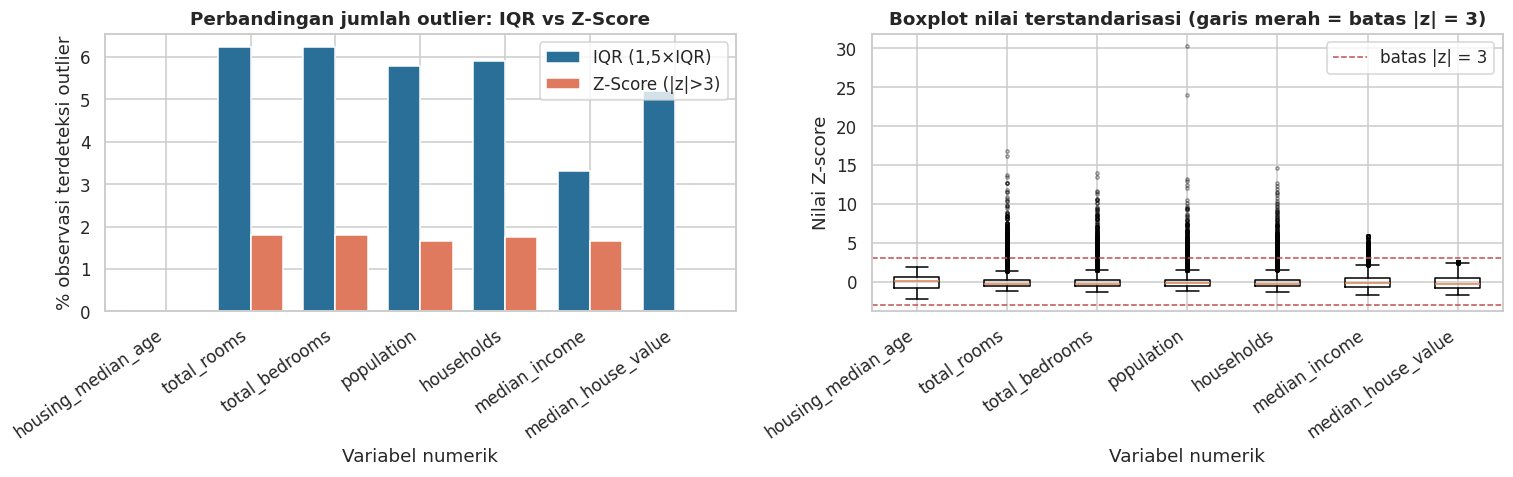

In [ ]:
OUT_VARS = ["housing_median_age", "total_rooms", "total_bedrooms", "population",
            "households", "median_income", "median_house_value"]

def mask_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - k*iqr) | (s > q3 + k*iqr)

def mask_z(s, thr=3):
    return ((s - s.mean()) / s.std(ddof=0)).abs() > thr

rows = []
for v in OUT_VARS:
    a, b = mask_iqr(df[v]), mask_z(df[v])
    both, only_iqr, only_z = int((a & b).sum()), int((a & ~b).sum()), int((~a & b).sum())
    rows.append((v, int(a.sum()), a.mean()*100, int(b.sum()), b.mean()*100, both, only_iqr, only_z,
                 both / max(int((a | b).sum()), 1), df[v].skew()))
out_cmp = pd.DataFrame(rows, columns=["Variabel", "n IQR", "% IQR", "n Z-Score", "% Z-Score",
                                      "Terdeteksi keduanya", "Hanya IQR", "Hanya Z", "Kesesuaian (Jaccard)", "Skewness"])
display(out_cmp)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(OUT_VARS)); w = 0.38
axes[0].bar(x - w/2, out_cmp["% IQR"], w, label="IQR (1,5×IQR)", color="#2a6f97")
axes[0].bar(x + w/2, out_cmp["% Z-Score"], w, label="Z-Score (|z|>3)", color="#e07a5f")
axes[0].set_xticks(x); axes[0].set_xticklabels(OUT_VARS, rotation=35, ha="right"); axes[0].set_xlabel("Variabel numerik")
axes[0].set_ylabel("% observasi terdeteksi outlier"); axes[0].set_title("Perbandingan jumlah outlier: IQR vs Z-Score"); axes[0].legend()

zdf = ((df[OUT_VARS] - df[OUT_VARS].mean()) / df[OUT_VARS].std(ddof=0))
axes[1].boxplot([zdf[v] for v in OUT_VARS], showfliers=True, flierprops=dict(markersize=2, alpha=.4))
axes[1].axhline(3, ls="--", c="r", lw=1, label="batas |z| = 3"); axes[1].axhline(-3, ls="--", c="r", lw=1)
axes[1].set_xlabel("Variabel numerik"); axes[1].set_ylabel("Nilai Z-score"); axes[1].legend(loc="upper right")
axes[1].set_xticklabels(OUT_VARS, rotation=35, ha="right")
axes[1].set_title("Boxplot nilai terstandarisasi (garis merah = batas |z| = 3)")
plt.tight_layout(); plt.show()

**Gambar 1. Perbandingan deteksi outlier.** Kiri: persentase observasi yang ditandai outlier oleh IQR (1,5×IQR, biru) dan Z-Score (|z| > 3, oranye) pada tujuh variabel numerik; IQR menandai jauh lebih banyak pada variabel cacahan yang miring ke kanan. Kanan: boxplot nilai terstandarisasi; garis putus-putus merah adalah batas |z| = 3.

**Perbandingan kedua metode.**

- **Jumlah deteksi.** IQR menandai 3,3% sampai 6,2% observasi sebagai outlier pada enam variabel (`total_rooms` 6,24%, `total_bedrooms` 6,23%, `households` 5,91%, `population` 5,80%, `median_house_value` 5,19%, `median_income` 3,30%), sedangkan Z-Score hanya 1,66% sampai 1,81% pada lima variabel yang sama. `housing_median_age` tidak memiliki outlier menurut kedua metode.
- **Tumpang tindih.** Seluruh nilai yang ditandai Z-Score (|z| > 3) juga ditandai IQR (kolom "Hanya Z" = 0), tetapi IQR menandai sekitar 2 sampai 3,5 kali lebih banyak. Kesesuaian (Jaccard) hanya 0,29–0,30 pada variabel cacahan dan 0,51 pada `median_income`.
- **Mengapa berbeda.** Z-Score memakai rata-rata dan simpangan baku yang **sendiri terdongkrak oleh outlier** (efek *masking*) dan mengasumsikan distribusi simetris. Pada variabel cacahan yang miring ke kanan (skewness 3,4–4,9), ekor kanan yang panjang menaikkan simpangan baku, sehingga hanya nilai yang benar-benar ekstrem melewati |z| > 3. IQR berbasis kuartil sehingga tahan terhadap nilai ekstrem dan lebih sesuai untuk data miring.
- **Kasus `median_house_value`.** Z-Score tidak mendeteksi satu pun karena nilai tertinggi (500.001) hanya sekitar 2,5 simpangan baku di atas rata-rata. IQR menandai 1.071 baris, dan sebagian besar (965 baris) adalah nilai tersensor di 500.001, yaitu **artefak pencatatan, bukan anomali nyata**. Jadi metode otomatis perlu diikuti penilaian konteks, dan keputusan "hapus" di sini akan keliru.

Kesimpulan: IQR dipakai sebagai alat deteksi utama untuk data miring, dan Z-Score dipakai sebagai pembanding. Keputusan tindakan ditentukan per variabel pada tabel berikut.

**Keputusan akhir per variabel** (dijelaskan dari karakteristik datanya, bukan sekadar angka deteksi):

In [ ]:
keputusan = pd.DataFrame([
    ("total_rooms, total_bedrooms, population, households", "CAP (winsorizing) pada Q3 + 3×IQR (batas outlier ekstrem), hanya sisi atas",
     "Skewness sangat tinggi karena blok sensus yang sangat besar. Nilai ekstrem seperti 39.320 ruangan masih mungkin sah tetapi bukan 'blok sensus khas', dan akan mendominasi PCA dan K-Means yang berbasis varians/jarak. Dibatasi, bukan dibuang, agar baris tetap terpakai. Outlier ringan (di antara 1,5 dan 3×IQR) dibiarkan sebagai variasi wajar."),
    ("Baris dengan rasio tidak wajar (ruangan/rumah tangga >20 atau <1; penghuni/rumah tangga >20 atau <1)", "HAPUS",
     "Bukan hunian rumah tangga biasa (resor, asrama, kemungkinan salah catat). Jumlahnya sangat kecil sehingga membuang tidak mengubah populasi analisis."),
    ("median_income", "PERTAHANKAN (+ penanda censored)",
     "Pendapatan tinggi di wilayah kaya adalah sinyal sah, justru informatif untuk nilai rumah. Titik 15,0001 adalah batas pencatatan, bukan outlier."),
    ("median_house_value (target)", "PERTAHANKAN (+ penanda censored)",
     "Lonjakan di 500.001 adalah pemotongan pencatatan (censoring). Menghapus atau mengubahnya akan membuang 4–5% data bagian termahal dan menggeser target. Dicatat sebagai keterbatasan."),
    ("housing_median_age", "PERTAHANKAN (+ penanda censored)",
     "Hampir tidak ada outlier IQR; tumpukan di 52 adalah batas pencatatan."),
], columns=["Variabel", "Keputusan", "Justifikasi"])
pd.set_option("display.max_colwidth", 250)
display(keputusan)

,Variabel,Keputusan,Justifikasi
0,"total_rooms, total_bedrooms, population, households","CAP (winsorizing) pada Q3 + 3×IQR (batas outlier ekstrem), hanya sisi atas","Skewness sangat tinggi karena blok sensus yang sangat besar. Nilai ekstrem seperti 39.320 ruangan masih mungkin sah tetapi bukan 'blok sensus khas', dan akan mendominasi PCA dan K-Means yang berbasis varians/jarak. Dibatasi, bukan dibuang, agar b..."
1,Baris dengan rasio tidak wajar (ruangan/rumah tangga >20 atau <1; penghuni/rumah tangga >20 atau <1),HAPUS,"Bukan hunian rumah tangga biasa (resor, asrama, kemungkinan salah catat). Jumlahnya sangat kecil sehingga membuang tidak mengubah populasi analisis."
2,median_income,PERTAHANKAN (+ penanda censored),"Pendapatan tinggi di wilayah kaya adalah sinyal sah, justru informatif untuk nilai rumah. Titik 15,0001 adalah batas pencatatan, bukan outlier."
3,median_house_value (target),PERTAHANKAN (+ penanda censored),Lonjakan di 500.001 adalah pemotongan pencatatan (censoring). Menghapus atau mengubahnya akan membuang 4–5% data bagian termahal dan menggeser target. Dicatat sebagai keterbatasan.
4,housing_median_age,PERTAHANKAN (+ penanda censored),Hampir tidak ada outlier IQR; tumpukan di 52 adalah batas pencatatan.


(1) Baris dihapus karena rasio tidak wajar: 83 (0.40%)
(2) Nilai yang dibatasi (cap):


,Variabel,Batas atas cap (Q3+3·IQR),Jumlah nilai di-cap,% observasi
0,total_rooms,"8,237.000",491,2.388
1,total_bedrooms,"1,700.000",443,2.155
2,population,"4,535.000",417,2.029
3,households,"1,581.000",412,2.004


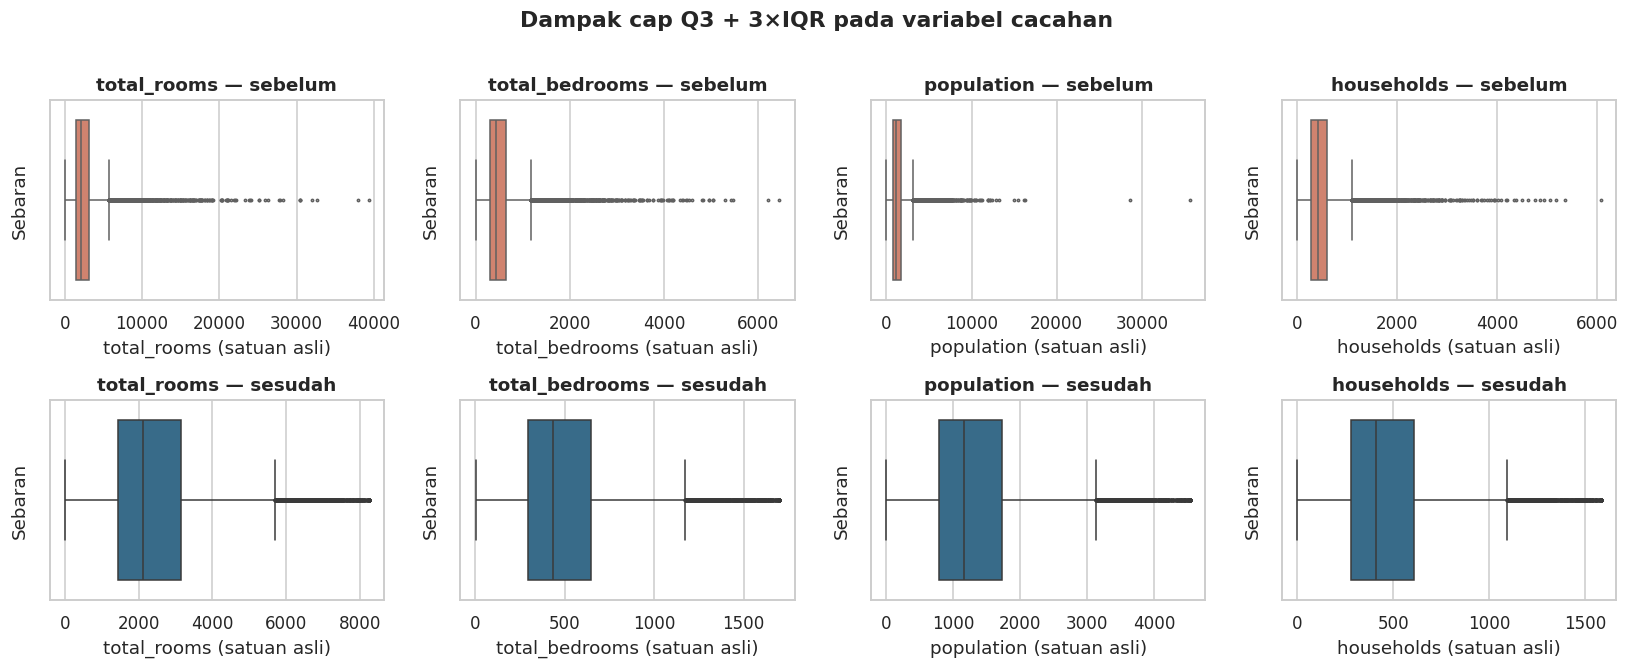

(3) Dipertahankan dengan penanda censored: median_income, median_house_value, housing_median_age


In [ ]:
n_before = len(df)
df_before_outlier = df.copy()          # simpan untuk perbandingan boxplot sebelum/sesudah

# Penanda censored (informasi dipertahankan agar analisis lanjutan bisa mengendalikannya)
df["flag_value_censored"]  = df["median_house_value"] >= 500001
df["flag_age_censored"]    = df["housing_median_age"] >= 52
df["flag_income_censored"] = df["median_income"] >= 15

# (1) HAPUS: baris dengan rasio tidak wajar
rph_ = df["total_rooms"] / df["households"]; pph_ = df["population"] / df["households"]
bad = (rph_ > 20) | (rph_ < 1) | (pph_ > 20) | (pph_ < 1)
n_removed = int(bad.sum())
df = df.loc[~bad].copy()
print(f"(1) Baris dihapus karena rasio tidak wajar: {n_removed} ({n_removed/n_before*100:.2f}%)")

# (2) CAP: Q3 + 3*IQR untuk variabel cacahan
CAP_VARS = ["total_rooms", "total_bedrooms", "population", "households"]
cap_tbl = []
for v in CAP_VARS:
    q1, q3 = df[v].quantile([.25, .75]); upper = q3 + 3*(q3 - q1)
    n_cap = int((df[v] > upper).sum())
    df[v] = df[v].clip(upper=upper)
    cap_tbl.append((v, upper, n_cap, n_cap/len(df)*100))
cap_tbl = pd.DataFrame(cap_tbl, columns=["Variabel", "Batas atas cap (Q3+3·IQR)", "Jumlah nilai di-cap", "% observasi"])
print("(2) Nilai yang dibatasi (cap):"); display(cap_tbl)
n_cells_capped = int(cap_tbl["Jumlah nilai di-cap"].sum())

# Visual sebelum vs sesudah
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, v in enumerate(CAP_VARS):
    sns.boxplot(x=df_before_outlier[v], ax=axes[0, j], color="#e07a5f", fliersize=1.5); axes[0, j].set_title(f"{v} — sebelum")
    sns.boxplot(x=df[v],                 ax=axes[1, j], color="#2a6f97", fliersize=1.5); axes[1, j].set_title(f"{v} — sesudah")
    axes[0, j].set_xlabel(f"{v} (satuan asli)"); axes[1, j].set_xlabel(f"{v} (satuan asli)")
    axes[0, j].set_ylabel("Sebaran"); axes[1, j].set_ylabel("Sebaran")
plt.suptitle("Dampak cap Q3 + 3×IQR pada variabel cacahan", y=1.01, fontweight="bold"); plt.tight_layout(); plt.show()
print("(3) Dipertahankan dengan penanda censored: median_income, median_house_value, housing_median_age")

**Gambar 2. Dampak cap Q3 + 3×IQR.** Boxplot empat variabel cacahan sebelum (baris atas, merah) dan sesudah (baris bawah, biru) pembatasan nilai ekstrem. Ekor kanan yang sangat panjang terpotong pada batas atas, sedangkan badan distribusi tidak berubah.

### I.2.3 Transformasi data: fitur turunan, normalisasi, diskretisasi dan generalisasi

,Skewness awal,|skew| akar kuadrat,|skew| log1p,Transformasi dipilih,Skewness setelah
housing_median_age,0.058,0.474,1.141,asli,0.058
total_rooms,1.533,0.543,1.276,akar kuadrat,0.543
total_bedrooms,1.541,0.579,1.153,akar kuadrat,0.579
population,1.508,0.534,1.168,akar kuadrat,0.534
households,1.524,0.542,1.175,akar kuadrat,0.542
median_income,1.643,0.689,0.228,log1p,0.228
rooms_per_household,1.944,0.747,0.143,log1p,0.143
bedrooms_per_room,2.149,1.154,1.614,akar kuadrat,1.154
population_per_household,4.065,1.543,0.799,log1p,0.799


,mean (Z),std (Z),min (MinMax),max (MinMax)
housing_median_age,0.000,1.000,0.000,1.000
total_rooms,0.000,1.000,0.000,1.000
total_bedrooms,-0.000,1.000,0.000,1.000
population,0.000,1.000,0.000,1.000
households,-0.000,1.000,0.000,1.000
median_income,0.000,1.000,0.000,1.000
rooms_per_household,0.000,1.000,0.000,1.000
bedrooms_per_room,-0.000,1.000,0.000,1.000
population_per_household,-0.000,1.000,0.000,1.000


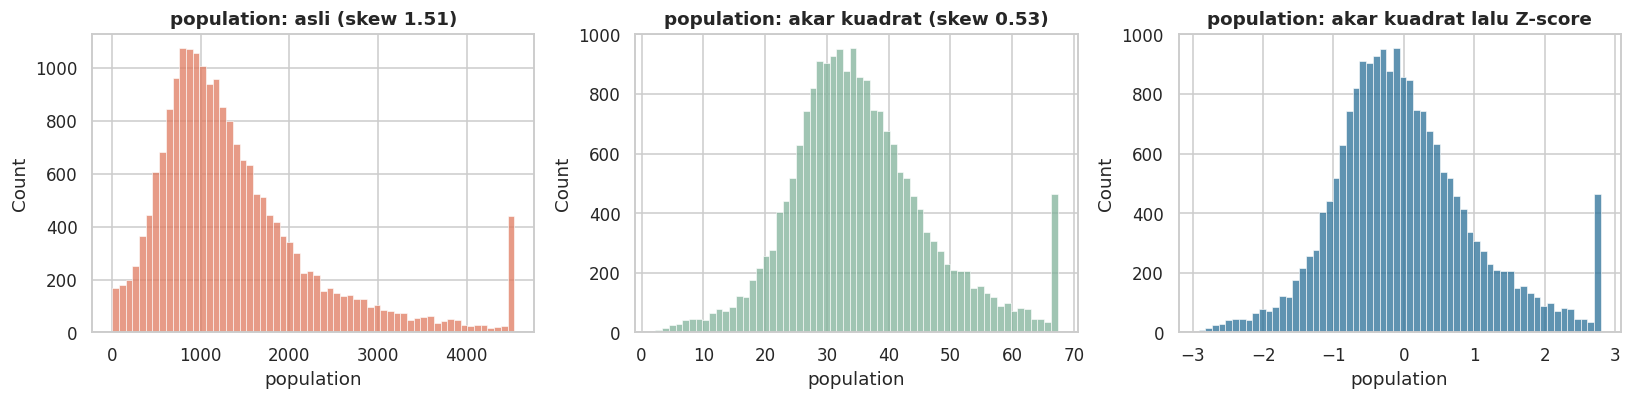

In [ ]:
# ---- (a) Fitur turunan (rasio) agar ukuran blok sensus tidak mengaburkan karakteristiknya ----
# PENTING: rasio dihitung dari nilai SEBELUM di-cap (df_before_outlier, baris tidak wajar sudah dibuang).
# Jika dihitung dari kolom yang sudah di-cap, pembilang dan penyebut terpotong pada batas berbeda sehingga rasio terdistorsi.
_u = df_before_outlier.loc[df.index]
df["rooms_per_household"]      = _u["total_rooms"] / _u["households"]
df["bedrooms_per_room"]        = _u["total_bedrooms"] / _u["total_rooms"]
df["population_per_household"] = _u["population"] / _u["households"]

# ---- (b) Normalisasi: transformasi pemangkas skewness (akar kuadrat / log1p), lalu Z-score ----
NUM_MODEL = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households",
             "median_income", "rooms_per_household", "bedrooms_per_room", "population_per_household"]

skew_before = df[NUM_MODEL].skew()

def pilih_transformasi(s_):
    """Pilih transformasi (asli / akar kuadrat / log1p) dengan |skewness| terkecil. Variabel yang sudah simetris (|skew| <= 1) tidak diubah."""
    if abs(stats.skew(s_)) <= 1:
        return "asli", s_
    cand = {"asli": s_, "akar kuadrat": np.sqrt(s_), "log1p": np.log1p(s_)}
    best = min(cand, key=lambda k: abs(stats.skew(cand[k])))
    return best, cand[best]

df_tr = pd.DataFrame(index=df.index); TRANS = {}
for v in NUM_MODEL:
    TRANS[v], df_tr[v] = pilih_transformasi(df[v])
skew_after = df_tr.skew()

tr = pd.DataFrame({"Skewness awal": skew_before,
                   "|skew| akar kuadrat": [abs(stats.skew(np.sqrt(df[v]))) for v in NUM_MODEL],
                   "|skew| log1p": [abs(stats.skew(np.log1p(df[v]))) for v in NUM_MODEL],
                   "Transformasi dipilih": pd.Series(TRANS), "Skewness setelah": skew_after})
display(tr)
LOG_VARS = [v for v in NUM_MODEL if TRANS[v] != "asli"]      # variabel yang ditransformasi

scaler = StandardScaler().fit(df_tr)
X_scaled = pd.DataFrame(scaler.transform(df_tr), columns=NUM_MODEL, index=df.index)      # Z-score (dipakai PCA & K-Means)
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(df_tr), columns=NUM_MODEL, index=df.index)   # Min-Max (pembanding)

display(pd.DataFrame({"mean (Z)": X_scaled.mean(), "std (Z)": X_scaled.std(ddof=0),
                      "min (MinMax)": X_minmax.min(), "max (MinMax)": X_minmax.max()}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
v = "population"
sns.histplot(df[v], bins=60, ax=axes[0], color="#e07a5f"); axes[0].set_title(f"{v}: asli (skew {skew_before[v]:.2f})")
sns.histplot(df_tr[v], bins=60, ax=axes[1], color="#81b29a"); axes[1].set_title(f"{v}: {TRANS[v]} (skew {skew_after[v]:.2f})")
sns.histplot(X_scaled[v], bins=60, ax=axes[2], color="#2a6f97"); axes[2].set_title(f"{v}: {TRANS[v]} lalu Z-score")
plt.tight_layout(); plt.show()

**Gambar 3. Efek transformasi pada `population`.** Dari kiri ke kanan: distribusi asli (skewness 1,51 setelah cap), setelah transformasi yang dipilih (akar kuadrat, skewness 0,53), dan setelah Z-score (bentuk sama, skala rata-rata 0 dan simpangan baku 1).

**Hasil transformasi.**

- Variabel cacahan (`total_rooms`, `total_bedrooms`, `population`, `households`) paling baik ditangani **akar kuadrat**: skewness turun dari sekitar 1,5 menjadi sekitar 0,5. Log1p justru *over-correct* (|skewness| ≈ 1,2, miring ke kiri) karena nilai ekstremnya sudah di-cap.
- `median_income`, `rooms_per_household`, dan `population_per_household` paling baik ditangani **log1p**: skewness turun dari 1,64 menjadi 0,23; dari 1,94 menjadi 0,14; dan dari 4,06 menjadi 0,80.
- `bedrooms_per_room` turun dari 2,15 menjadi 1,15 sehingga masih sedikit miring, tetapi sudah jauh lebih terkendali. `housing_median_age` sudah simetris (0,06) sehingga tidak diubah.
- Setelah Z-score, seluruh variabel memiliki rata-rata 0 dan simpangan baku 1. Min-Max menghasilkan rentang 0–1, tetapi sebarannya tetap bergantung pada nilai ekstrem, sehingga tidak dipakai.

In [ ]:
# ---- (c) Diskretisasi (3 variabel numerik -> ordinal) dan generalisasi (1 variabel kategorik -> kategori lebih umum) ----
# 1) median_income -> income_cat (kuartil, supaya tiap kelas berisi jumlah seimbang)
lab_inc = ["Rendah", "Menengah", "Menengah-Atas", "Tinggi"]
df["income_cat"] = pd.qcut(df["median_income"], q=4, labels=lab_inc)

# 2) housing_median_age -> age_cat (batas berbasis makna: bangunan baru, cukup baru, lama, sangat lama)
lab_age = ["Baru (<=15)", "Cukup baru (16-30)", "Lama (31-45)", "Sangat lama (>45)"]
df["age_cat"] = pd.cut(df["housing_median_age"], bins=[0, 15, 30, 45, 100], labels=lab_age)

# 3) median_house_value -> value_cat (tertil: kelas harga untuk Chi-Square, PCA, clustering)
lab_val = ["Murah", "Menengah", "Mahal"]
df["value_cat"] = pd.qcut(df["median_house_value"], q=3, labels=lab_val)

# 4) GENERALISASI ocean_proximity (5 kategori) -> lokasi (2 kategori)
peta_lokasi = {"<1H OCEAN": "Pesisir", "NEAR OCEAN": "Pesisir", "NEAR BAY": "Pesisir", "ISLAND": "Pesisir", "INLAND": "Daratan"}
df["lokasi"] = df["ocean_proximity"].map(peta_lokasi)

for c, labs in [("income_cat", lab_inc), ("age_cat", lab_age), ("value_cat", lab_val)]:
    df[c] = pd.Categorical(df[c], categories=labs, ordered=True)

print("Batas kuartil median_income:", df["median_income"].quantile([.25, .5, .75]).round(3).tolist())
print("Batas tertil median_house_value:", df["median_house_value"].quantile([1/3, 2/3]).round(0).tolist())
for c in ["income_cat", "age_cat", "value_cat", "lokasi"]:
    vc = df[c].value_counts().sort_index() if c != "lokasi" else df[c].value_counts()
    display(pd.DataFrame({"Frekuensi": vc, "Persen (%)": vc / vc.sum() * 100}).rename_axis(c))

Batas kuartil median_income: [2.564, 3.535, 4.744]
Batas tertil median_house_value: [141400.0, 230600.0]


,Frekuensi,Persen (%)
income_cat,,
Rendah,5142,25.013
Menengah,5137,24.989
Menengah-Atas,5139,24.999
Tinggi,5139,24.999


,Frekuensi,Persen (%)
age_cat,,
Baru (<=15),3256,15.839
Cukup baru (16-30),7822,38.050
Lama (31-45),7273,35.380
Sangat lama (>45),2206,10.731


,Frekuensi,Persen (%)
value_cat,,
Murah,6853,33.337
Menengah,6859,33.366
Mahal,6845,33.298


,Frekuensi,Persen (%)
lokasi,,
Pesisir,14082,68.502
Daratan,6475,31.498


**Alasan setiap transformasi**

| Transformasi | Alasan |
|---|---|
| **Fitur rasio** (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`) | Jumlah ruangan/penduduk mentah hanya mencerminkan *ukuran blok*, bukan *karakter hunian*. Rasio memisahkan keduanya. Rasio dihitung dari nilai **sebelum di-cap** (setelah baris tidak wajar dibuang), karena pembilang dan penyebut yang di-cap pada batas berbeda akan mendistorsi rasio blok-blok besar. |
| **Akar kuadrat / log1p** pada variabel dengan \|skewness\| > 1 | Menekan ekor panjang kanan. Untuk tiap variabel saya uji akar kuadrat dan log1p lalu memilih yang \|skewness\|-nya paling kecil (log1p bisa *over-correct* menjadi miring ke kiri pada variabel yang sudah di-cap). Pengaruh nilai besar pada PCA/K-Means jadi tidak berlebihan. |
| **Z-score** | PCA dan K-Means berbasis varians/jarak, sehingga semua variabel harus memiliki skala yang sama. Z-score dipilih daripada Min-Max karena Min-Max tetap sensitif terhadap nilai ekstrem (satu nilai besar menekan seluruh sebaran ke ujung 0). Min-Max ditampilkan hanya sebagai pembanding. |
| **Diskretisasi `median_income`** (kuartil) | Membuat variabel ordinal dengan kelas seimbang untuk analisis tabulasi silang. |
| **Diskretisasi `housing_median_age`** (batas bermakna) | Batas 15/30/45 tahun mengikuti generasi pembangunan perumahan, lebih mudah ditafsirkan daripada kuantil. |
| **Diskretisasi `median_house_value`** (tertil) | Mengubah target kontinu menjadi kelas harga untuk Chi-Square, pewarnaan PCA, dan profil klaster. |
| **Generalisasi `ocean_proximity` → `lokasi`** | Menggabungkan 4 kategori pesisir (termasuk ISLAND yang hanya beberapa baris) menjadi "Pesisir" vs "Daratan", sehingga kategori langka tidak merusak uji statistik. |

In [ ]:
# ---- Tabel klasifikasi variabel FINAL (termasuk variabel turunan) ----
final_info = pd.DataFrame([
    ("longitude, latitude", "Numerik kontinu", "asli"),
    ("housing_median_age", "Numerik diskrit", "asli (di-flag censored)"),
    ("total_rooms, total_bedrooms, population, households", "Numerik diskrit", "asli (di-cap Q3+3·IQR; total_bedrooms diimputasi)"),
    ("median_income, median_house_value", "Numerik kontinu", "asli (di-flag censored)"),
    ("rooms_per_household, bedrooms_per_room, population_per_household", "Numerik kontinu", "turunan (rasio)"),
    ("ocean_proximity", "Kategorik nominal", "asli"),
    ("lokasi", "Kategorik nominal (biner)", "turunan (generalisasi ocean_proximity)"),
    ("income_cat", "Kategorik ORDINAL (4 tingkat)", "turunan (diskretisasi median_income)"),
    ("age_cat", "Kategorik ORDINAL (4 tingkat)", "turunan (diskretisasi housing_median_age)"),
    ("value_cat", "Kategorik ORDINAL (3 tingkat)", "turunan (diskretisasi target)"),
    ("flag_* (value/age/income censored, bedrooms imputed)", "Biner (boolean)", "penanda"),
], columns=["Variabel", "Klasifikasi final", "Asal"])
final_info

,Variabel,Klasifikasi final,Asal
0,"longitude, latitude",Numerik kontinu,asli
1,housing_median_age,Numerik diskrit,asli (di-flag censored)
2,"total_rooms, total_bedrooms, population, households",Numerik diskrit,asli (di-cap Q3+3·IQR; total_bedrooms diimputasi)
3,"median_income, median_house_value",Numerik kontinu,asli (di-flag censored)
4,"rooms_per_household, bedrooms_per_room, population_per_household",Numerik kontinu,turunan (rasio)
5,ocean_proximity,Kategorik nominal,asli
6,lokasi,Kategorik nominal (biner),turunan (generalisasi ocean_proximity)
7,income_cat,Kategorik ORDINAL (4 tingkat),turunan (diskretisasi median_income)
8,age_cat,Kategorik ORDINAL (4 tingkat),turunan (diskretisasi housing_median_age)
9,value_cat,Kategorik ORDINAL (3 tingkat),turunan (diskretisasi target)


### I.2.4 Verifikasi pipeline (sebelum vs sesudah)

In [ ]:
NUM_ORI = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
           "population", "households", "median_income", "median_house_value"]

def iqr_pct(frame):
    return float(np.mean([mask_iqr(frame[v].dropna()).mean() for v in OUT_VARS]) * 100)

sel_cells_total = len(df) * len(NUM_ORI)
modified_cells = n_imputed + n_cells_capped

ver = pd.DataFrame({
    "Sebelum preparation": [len(df_raw), df_raw.shape[1], int(df_raw.isna().sum().sum()), int(df_raw.duplicated().sum()),
                            iqr_pct(df_raw)],
    "Sesudah preparation": [len(df), df.shape[1], int(df[NUM_ORI + ["ocean_proximity"]].isna().sum().sum()),
                            int(df[df_raw.columns].duplicated().sum()), iqr_pct(df)],
}, index=["Jumlah baris", "Jumlah kolom (sesudah: termasuk fitur turunan & penanda)", "Total missing", "Baris duplikat", "Rata-rata % outlier IQR (7 var)"])
display(ver)

stat_cmp = pd.concat({
    "Sebelum": df_raw[NUM_ORI].agg(["mean", "std", "skew"]).T,
    "Sesudah": df[NUM_ORI].agg(["mean", "std", "skew"]).T,
}, axis=1)
display(stat_cmp)

print(f"Baris hilang       : {n_removed} dari {n_before:,} = {n_removed/n_before*100:.2f}%")
print(f"Sel diimputasi     : {n_imputed} = {n_imputed/sel_cells_total*100:.3f}% dari seluruh sel numerik")
print(f"Sel di-cap         : {n_cells_capped} = {n_cells_capped/sel_cells_total*100:.3f}% dari seluruh sel numerik")
print(f"Total sel berubah  : {modified_cells} = {modified_cells/sel_cells_total*100:.3f}%")
print(f"Baris tersisa      : {len(df):,} ({len(df)/n_before*100:.2f}% dari data awal)")

,Sebelum preparation,Sesudah preparation
Jumlah baris,"20,640.000","20,557.000"
Jumlah kolom (sesudah: termasuk fitur turunan & penanda),10.000,21.000
Total missing,207.000,0.000
Baris duplikat,0.000,0.000
Rata-rata % outlier IQR (7 var),4.664,4.660


Sebelum                        Sesudah                   
                          mean         std   skew        mean         std   skew
longitude             -119.570       2.004 -0.298    -119.570       2.005 -0.299
latitude                35.632       2.136  0.466      35.625       2.133  0.470
housing_median_age      28.639      12.586  0.060      28.671      12.577  0.058
total_rooms          2,635.763   2,181.615  4.147   2,539.451   1,667.835  1.533
total_bedrooms         537.871     421.385  3.460     522.410     341.990  1.541
population           1,425.477   1,132.462  4.936   1,388.789     900.955  1.508
households             499.540     382.330  3.410     488.022     314.336  1.524
median_income            3.871       1.900  1.647       3.871       1.898  1.643
median_house_value 206,855.817 115,395.616  0.978 206,969.600 115,455.472  0.976

Baris hilang       : 83 dari 20,640 = 0.40%
Sel diimputasi     : 207 = 0.112% dari seluruh sel numerik
Sel di-cap         : 1763 = 0.953% dari seluruh sel numerik
Total sel berubah  : 1970 = 1.065%
Baris tersisa      : 20,557 (99.60% dari data awal)


**Ringkasan hasil pipeline.**

| Indikator | Hasil |
|---|---|
| Baris yang hilang | 83 dari 20.640 = **0,40%** (hanya baris dengan rasio tidak wajar) |
| Sel yang berubah | 1.970 dari sekitar 185 ribu sel numerik = **1,07%** (207 diimputasi + 1.763 di-cap) |
| Missing value | 207 → **0** |
| Duplikat | 0 → 0 |
| Rata-rata `median_house_value` | 206.856 → 206.970 (praktis tidak bergeser) |
| Simpangan baku variabel cacahan | turun 18–24% (mis. `total_rooms` 2.181,6 → 1.667,8; `population` 1.132,5 → 901,0) |
| Skewness variabel cacahan | turun dari 3,4–4,9 menjadi sekitar 1,5 |
| `median_income`, `latitude`, `longitude` | tidak berubah |

Kualitas data **sudah memadai untuk analisis**: tidak ada missing, hanya 0,40% baris yang dibuang, dan perubahan nilai sangat kecil serta terkonsentrasi di ekor distribusi. Rata-rata persentase outlier IQR hampir tidak berubah (4,66% → 4,66%) karena cap sengaja hanya memotong outlier **ekstrem** (di atas 3×IQR) dan mempertahankan variasi wajar. Sisa catatan yang tidak dapat diperbaiki oleh pipeline: (1) nilai tersensor yang hanya diberi penanda, (2) kategori `ISLAND` dengan 5 baris, dan (3) `bedrooms_per_room` yang masih sedikit miring.

---
# Bagian II — Analisis Univariat dan Bivariat Mendalam
Analisis memakai dataset hasil preparation (`df`).

## II.1 Profil Statistik Komprehensif
### II.1.1 Tabel statistik deskriptif variabel numerik

In [ ]:
NUM_ALL = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population",
           "households", "median_income", "median_house_value",
           "rooms_per_household", "bedrooms_per_room", "population_per_household"]

def profil(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({
        "Mean": s.mean(), "Median": s.median(), "Std Dev": s.std(),
        "IQR": q3 - q1, "Skewness": stats.skew(s), "Kurtosis (excess)": stats.kurtosis(s),
        "% Outlier (IQR)": mask_iqr(s).mean() * 100,
    })

tabel_stat = df[NUM_ALL].apply(profil).T
display(tabel_stat)

,Mean,Median,Std Dev,IQR,Skewness,Kurtosis (excess),% Outlier (IQR)
longitude,-119.570,-118.490,2.005,3.790,-0.299,-1.334,0.000
latitude,35.625,34.250,2.133,3.780,0.470,-1.112,0.000
housing_median_age,28.671,29.000,12.577,19.000,0.058,-0.800,0.000
total_rooms,"2,539.451","2,127.000","1,667.835","1,697.000",1.533,2.550,6.212
total_bedrooms,522.410,435.000,341.990,351.000,1.540,2.544,6.202
population,"1,388.789","1,168.000",900.955,936.000,1.508,2.520,5.803
households,488.022,410.000,314.336,325.000,1.524,2.563,5.925
median_income,3.871,3.535,1.898,2.180,1.643,4.928,3.293
median_house_value,"206,969.600","179,800.000","115,455.472","145,400.000",0.976,0.323,5.186
rooms_per_household,5.335,5.225,1.421,1.604,1.944,12.607,2.194


### II.1.2 Variabel numerik dengan distribusi paling menyimpang dari normal

Peringkat |skewness| tertinggi:


,|skewness|
population_per_household,4.064
bedrooms_per_room,2.149
rooms_per_household,1.944
median_income,1.643
total_bedrooms,1.540



Variabel paling menyimpang dari normal: population_per_household


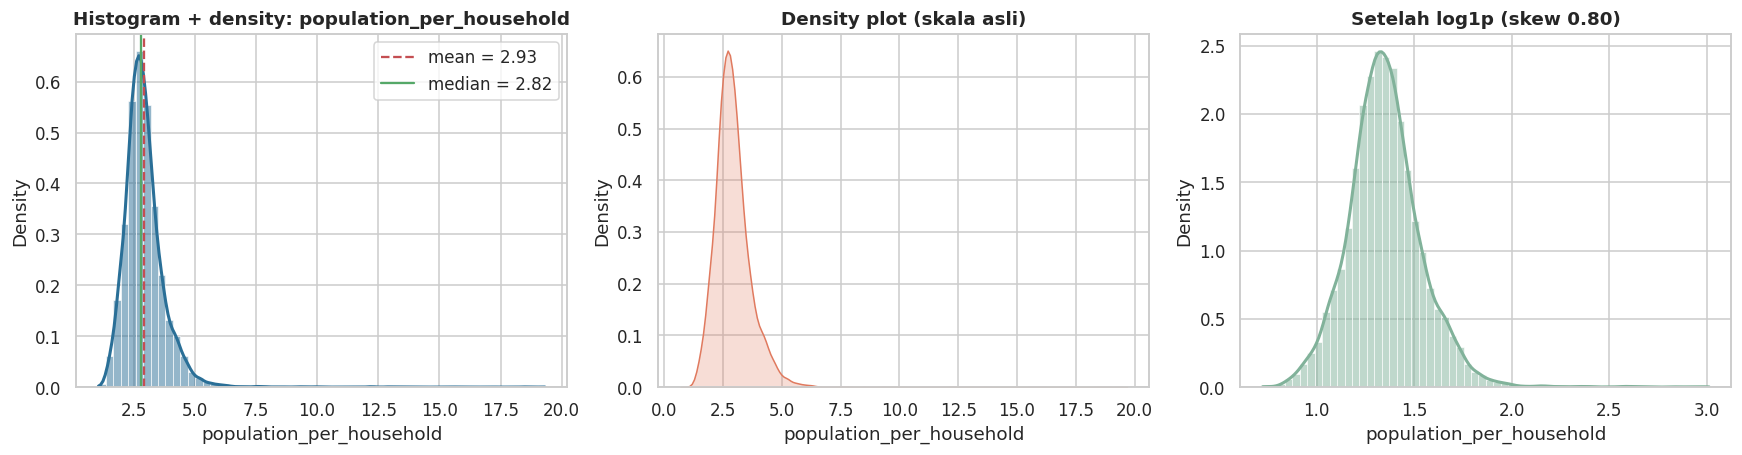

Skewness asli = 4.064; excess kurtosis = 49.611; mean/median = 1.040
Skewness setelah log1p = 0.799


In [ ]:
skew_rank = tabel_stat["Skewness"].abs().sort_values(ascending=False)
print("Peringkat |skewness| tertinggi:"); display(skew_rank.head(5).to_frame("|skewness|"))
VAR_SKEW = skew_rank.index[0]
print(f"\nVariabel paling menyimpang dari normal: {VAR_SKEW}")

s = df[VAR_SKEW]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.histplot(s, bins=60, kde=True, stat="density", color="#2a6f97", ax=axes[0], line_kws={"lw": 2})
axes[0].axvline(s.mean(), c="r", ls="--", label=f"mean = {s.mean():.2f}")
axes[0].axvline(s.median(), c="g", ls="-", label=f"median = {s.median():.2f}")
axes[0].set_title(f"Histogram + density: {VAR_SKEW}"); axes[0].legend()

sns.kdeplot(s, fill=True, color="#e07a5f", ax=axes[1])
axes[1].set_title("Density plot (skala asli)")

ls = np.log1p(s)
sns.histplot(ls, bins=60, kde=True, stat="density", color="#81b29a", ax=axes[2], line_kws={"lw": 2})
axes[2].set_title(f"Setelah log1p (skew {stats.skew(ls):.2f})")
plt.tight_layout(); plt.show()

print(f"Skewness asli = {stats.skew(s):.3f}; excess kurtosis = {stats.kurtosis(s):.3f}; mean/median = {s.mean()/s.median():.3f}")
print(f"Skewness setelah log1p = {stats.skew(ls):.3f}")

**Gambar 4. Variabel dengan distribusi paling menyimpang (`population_per_household`).** Kiri: histogram dan kurva density dengan garis rata-rata (merah) dan median (hijau); tengah: density plot skala asli; kanan: distribusi setelah log1p yang jauh lebih simetris (skewness turun dari 4,06 menjadi 0,80).

**Variabel yang paling menyimpang dari normal: `population_per_household`** (skewness = 4,06 dan kurtosis berlebih = 49,6). Distribusinya memiliki puncak sempit di sekitar 2,8 penghuni per rumah tangga dengan ekor kanan yang sangat panjang, sehingga kurtosis jauh di atas normal (0) yang menandakan banyak nilai ekstrem. Dua variabel rasio lain juga menyimpang: `bedrooms_per_room` (2,15) dan `rooms_per_household` (1,94).

**Implikasi untuk analisis selanjutnya:**

1. **Statistik ringkas.** Rata-rata dan simpangan baku menyesatkan pada variabel ini; median dan IQR lebih mewakili.
2. **Korelasi.** Pearson sensitif terhadap ekor panjang, sehingga hubungan dengan variabel ini perlu dicek dengan Spearman.
3. **PCA dan K-Means.** Variabel perlu ditransformasi (log1p menurunkan skewness menjadi 0,80) agar beberapa titik ekstrem tidak mendominasi varians dan jarak.
4. **Uji statistik.** Asumsi normalitas tidak terpenuhi, sehingga uji non-parametrik (Kruskal-Wallis, Mann-Whitney) dipakai sebagai pendamping uji parametrik.
5. **Pemeriksaan substansi.** Nilai ekstrem yang tersisa (hingga sekitar 20 penghuni per rumah tangga) mungkin blok non-residensial dan layak dikaji lebih jauh.

### II.1.3 Variabel kategorik: tabel frekuensi dan ketidakseimbangan kelas


=== ocean_proximity ===


,Frekuensi,Persen (%)
ocean_proximity,,
<1H OCEAN,9132,44.423
INLAND,6475,31.498
NEAR OCEAN,2655,12.915
NEAR BAY,2290,11.140
ISLAND,5,0.024



=== lokasi ===


,Frekuensi,Persen (%)
lokasi,,
Pesisir,14082,68.502
Daratan,6475,31.498



=== income_cat ===


,Frekuensi,Persen (%)
income_cat,,
Rendah,5142,25.013
Menengah,5137,24.989
Menengah-Atas,5139,24.999
Tinggi,5139,24.999


... (3 outputs left out)

,Frekuensi,Persen (%)
value_cat,,
Murah,6853,33.337
Menengah,6859,33.366
Mahal,6845,33.298



RINGKASAN KETIDAKSEIMBANGAN KELAS


,Jumlah kelas,Kelas terbesar,% terbesar,Kelas terkecil,% terkecil,Rasio terbesar/terkecil,Entropi ternormalisasi
ocean_proximity,5,<1H OCEAN,44.423,ISLAND,0.024,"1,826.400",0.767
lokasi,2,Pesisir,68.502,Daratan,31.498,2.175,0.899
income_cat,4,Rendah,25.013,Menengah,24.989,1.001,1.000
age_cat,4,Cukup baru (16-30),38.050,Sangat lama (>45),10.731,3.546,0.914
value_cat,3,Menengah,33.366,Mahal,33.298,1.002,1.000



Variabel dengan ketidakseimbangan paling signifikan: ocean_proximity


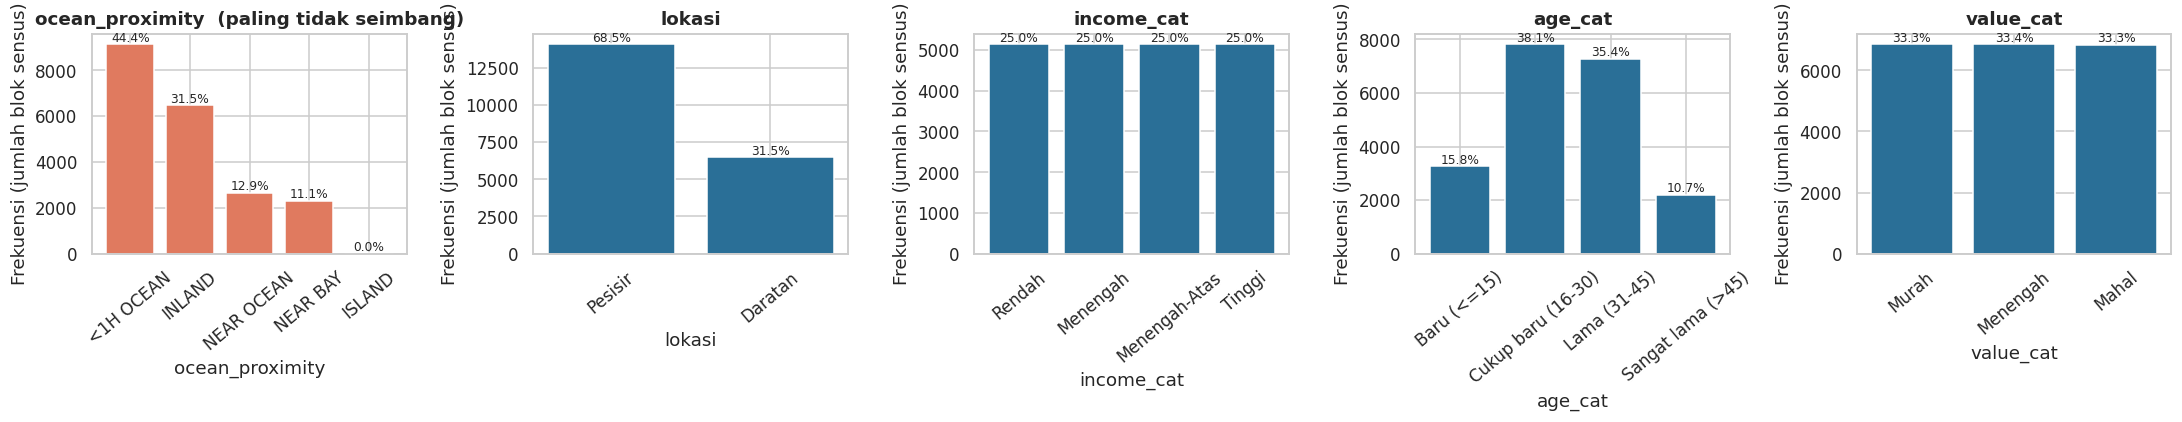

In [ ]:
CAT_ALL = ["ocean_proximity", "lokasi", "income_cat", "age_cat", "value_cat"]

def kelas_stat(s):
    vc = s.value_counts()
    p = vc / vc.sum()
    ent = -(p * np.log(p)).sum() / np.log(len(p))             # entropi ternormalisasi (1 = sangat seimbang)
    return pd.Series({"Jumlah kelas": len(vc), "Kelas terbesar": vc.index[0], "% terbesar": p.max()*100,
                      "Kelas terkecil": vc.index[-1], "% terkecil": p.min()*100,
                      "Rasio terbesar/terkecil": vc.max()/vc.min(), "Entropi ternormalisasi": ent})

for c in CAT_ALL:
    ft = df[c].value_counts().sort_index() if str(df[c].dtype) == "category" else df[c].value_counts()
    print(f"\n=== {c} ===")
    display(pd.DataFrame({"Frekuensi": ft, "Persen (%)": ft / ft.sum() * 100}))

ringkas_cat = pd.DataFrame({c: kelas_stat(df[c]) for c in CAT_ALL}).T
ringkas_cat = ringkas_cat.astype({"Jumlah kelas": int})
print("\nRINGKASAN KETIDAKSEIMBANGAN KELAS"); display(ringkas_cat)
VAR_IMB = ringkas_cat["Rasio terbesar/terkecil"].astype(float).idxmax()
print(f"\nVariabel dengan ketidakseimbangan paling signifikan: {VAR_IMB}")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, CAT_ALL):
    vc = df[c].value_counts().sort_index() if str(df[c].dtype) == "category" else df[c].value_counts()
    colors = ["#e07a5f" if c == VAR_IMB else "#2a6f97"] * len(vc)
    bars = ax.bar(vc.index.astype(str), vc.values, color=colors)
    for b_, v_ in zip(bars, vc.values):
        ax.text(b_.get_x() + b_.get_width()/2, v_, f"{v_/vc.sum()*100:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.set_title(c + ("  (paling tidak seimbang)" if c == VAR_IMB else "")); ax.tick_params(axis="x", rotation=40)
    ax.set_ylabel("Frekuensi (jumlah blok sensus)"); ax.set_xlabel(c)
plt.tight_layout(); plt.show()

**Gambar 5. Frekuensi variabel kategorik.** Label di atas batang adalah persentase kelas. `ocean_proximity` (batang oranye) paling tidak seimbang karena kelas `ISLAND` hanya 5 baris (0,02%); `income_cat` dan `value_cat` seimbang karena dibentuk dari kuantil.

**Variabel paling tidak seimbang: `ocean_proximity`.** Kelas terbesar (`<1H OCEAN`) mencakup 44,4% data, sedangkan kelas terkecil (`ISLAND`) hanya 5 baris (0,02%), rasio terbesar/terkecil mencapai **1.826 : 1** dan entropi ternormalisasi hanya 0,767. Variabel lain jauh lebih seimbang: `lokasi` (68,5% : 31,5%, rasio 2,2), `age_cat` (rasio 3,5), sedangkan `income_cat` dan `value_cat` seimbang (rasio 1,00) karena memang dibentuk dari kuantil.

**Implikasi.** Estimasi apa pun untuk `ISLAND` tidak stabil (n = 5). Frekuensi harapan pada uji Chi-Square akan di bawah 5, perbandingan rata-rata menjadi tidak andal, dan model prediktif tidak akan belajar apa pun tentang kelas ini. Karena itu saya (a) membuat generalisasi `lokasi`, (b) menjalankan uji ketahanan tanpa `ISLAND` pada Chi-Square, dan (c) tidak menarik kesimpulan khusus tentang pulau.

### II.1.4 Distribusi variabel target (`median_house_value`)

Mean = 206,970 | Median = 179,800 | Std = 115,455
Skewness = 0.976 | Excess kurtosis = 0.323
Proporsi nilai censored (>= 500.001): 4.68%
Shapiro-Wilk (n=5000): W = 0.9103, p = 2.11e-47
D'Agostino K^2 (n=20,557): K2 = 2,411.9, p = 0.00e+00

Skewness log(target)               : -0.175
Skewness target tanpa baris censored: 0.808


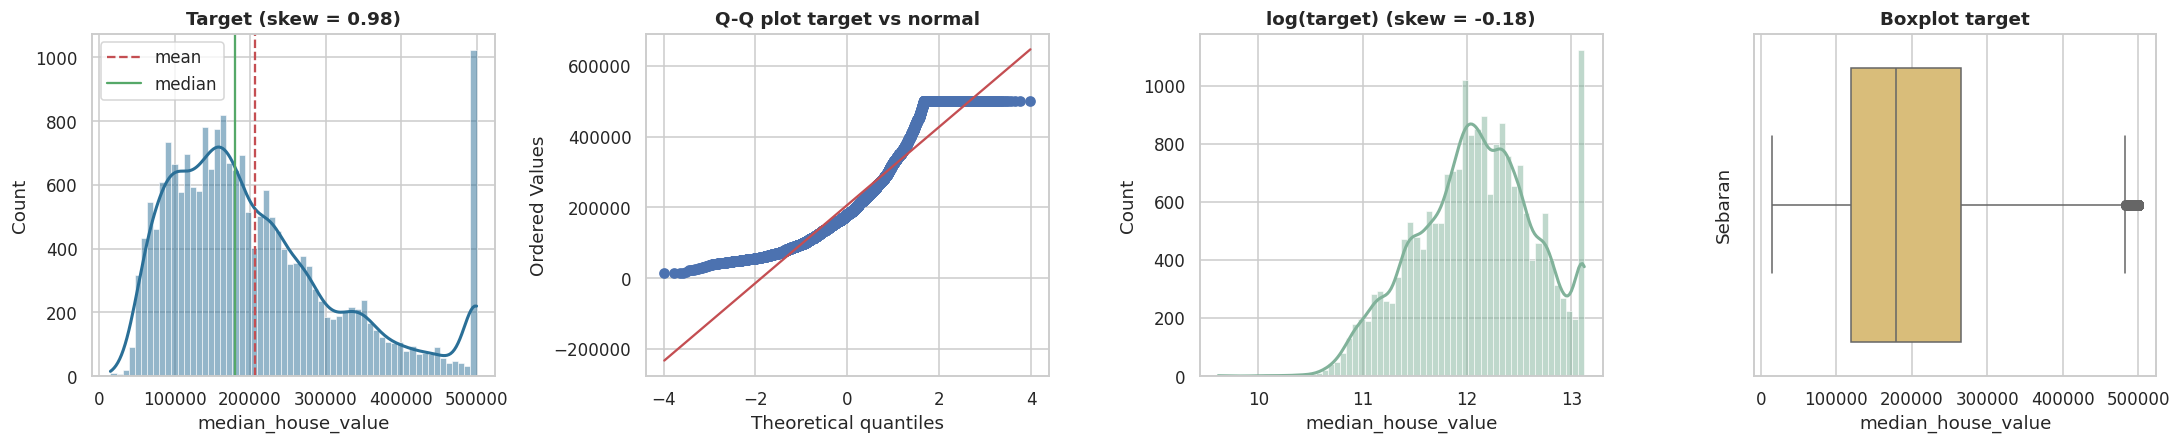

In [ ]:
y = df[TARGET]
sk, ku = stats.skew(y), stats.kurtosis(y)
print(f"Mean = {y.mean():,.0f} | Median = {y.median():,.0f} | Std = {y.std():,.0f}")
print(f"Skewness = {sk:.3f} | Excess kurtosis = {ku:.3f}")
print(f"Proporsi nilai censored (>= 500.001): {df['flag_value_censored'].mean()*100:.2f}%")

# Uji normalitas (Shapiro pada sampel 5.000 karena batas uji; D'Agostino pada seluruh data)
shap = stats.shapiro(y.sample(5000, random_state=SEED))
dag  = stats.normaltest(y)
print(f"Shapiro-Wilk (n=5000): W = {shap.statistic:.4f}, p = {shap.pvalue:.2e}")
print(f"D'Agostino K^2 (n={len(y):,}): K2 = {dag.statistic:,.1f}, p = {dag.pvalue:.2e}")

# Perbandingan setelah log dan tanpa baris censored
y_nc = y[~df["flag_value_censored"]]
print(f"\nSkewness log(target)               : {stats.skew(np.log(y)):.3f}")
print(f"Skewness target tanpa baris censored: {stats.skew(y_nc):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
sns.histplot(y, bins=60, kde=True, color="#2a6f97", ax=axes[0], line_kws={"lw": 2})
axes[0].axvline(y.mean(), c="r", ls="--", label="mean"); axes[0].axvline(y.median(), c="g", label="median"); axes[0].legend()
axes[0].set_title(f"Target (skew = {sk:.2f})")
stats.probplot(y, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot target vs normal")
sns.histplot(np.log(y), bins=60, kde=True, color="#81b29a", ax=axes[2], line_kws={"lw": 2}); axes[2].set_title(f"log(target) (skew = {stats.skew(np.log(y)):.2f})")
sns.boxplot(x=y, ax=axes[3], color="#e9c46a"); axes[3].set_title("Boxplot target"); axes[3].set_ylabel("Sebaran")
plt.tight_layout(); plt.show()

**Gambar 6. Distribusi variabel target.** Dari kiri ke kanan: histogram dengan garis rata-rata dan median (miring ke kanan, skewness 0,98, dengan lonjakan di 500.001), Q-Q plot terhadap distribusi normal (menyimpang pada kedua ujung), distribusi log(target) yang mendekati simetris, dan boxplot target.

**Distribusi target (`median_house_value`).** Target **miring ke kanan secara moderat**: rata-rata (206.970) lebih besar daripada median (179.800), skewness = 0,98, dan kurtosis berlebih = 0,32 (ekor tidak terlalu berat). Uji Shapiro-Wilk (W = 0,910, p ≈ 2×10⁻⁴⁷) dan D'Agostino K² (2.411,9, p ≈ 0) menolak normalitas, dan Q-Q plot menyimpang dari garis normal: melengkung di ujung bawah dan mendatar di 500.001 pada ujung atas. Ciri paling mencolok adalah **lonjakan di 500.001** yang mencakup 4,68% data, yaitu efek pemotongan pencatatan (censoring), bukan puncak alami.

**Implikasi:**

1. **Model.** Residual regresi linear pada skala asli akan tidak normal dan heteroskedastis. Transformasi log menurunkan skewness menjadi −0,18 (hampir simetris), sehingga memodelkan log-nilai rumah lebih sesuai.
2. **Censoring.** Nilai rumah yang sebenarnya di atas 500 ribu USD tercatat terlalu rendah, sehingga hubungan dengan prediktor terlemahkan pada ujung atas dan korelasi cenderung diremehkan. Model khusus data tersensor (mis. Tobit) atau pemisahan kelas "≥ 500 ribu" perlu dipertimbangkan.
3. **Uji statistik.** Dengan n besar uji parametrik cukup kokoh, tetapi saya tetap melengkapinya dengan uji non-parametrik.
4. **Metrik.** RMSE akan didominasi rumah mahal sehingga MAE atau error relatif perlu dilaporkan juga.

## II.2 Analisis Hubungan Antar Variabel
### II.2.1 Matriks korelasi dan heatmap

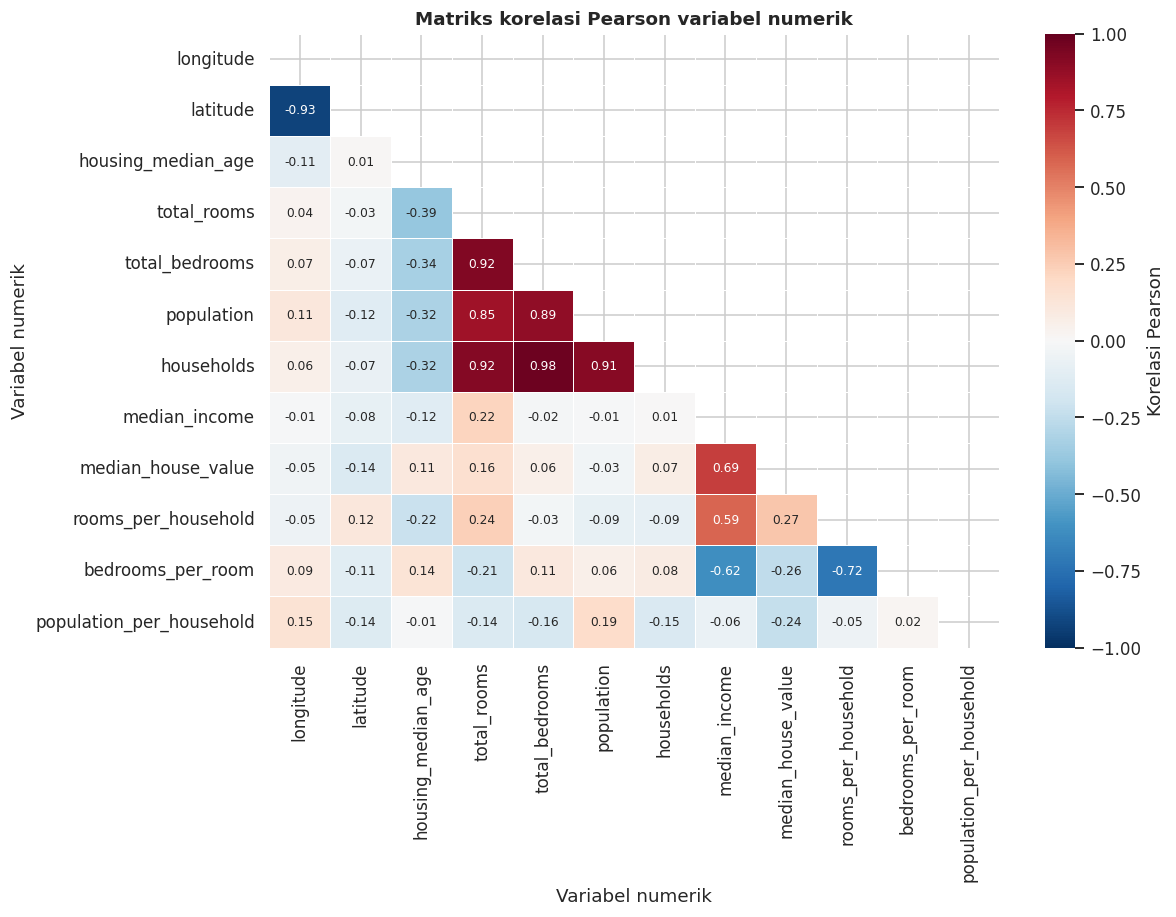

(a) Pasangan korelasi POSITIF terkuat : households x total_bedrooms (r = 0.984)
(b) Pasangan korelasi NEGATIF terkuat : latitude x longitude (r = -0.926)

(c) Korelasi dengan target (median_house_value), diurutkan:


,Pearson,Spearman,|Pearson|
median_income,0.690,0.678,0.690
rooms_per_household,0.274,0.267,0.274
bedrooms_per_room,-0.256,-0.331,0.256
population_per_household,-0.242,-0.259,0.242
total_rooms,0.159,0.207,0.159
latitude,-0.144,-0.165,0.144
housing_median_age,0.105,0.074,0.105
households,0.072,0.112,0.072
total_bedrooms,0.057,0.088,0.057
longitude,-0.046,-0.070,0.046


Variabel paling berkorelasi dengan target: median_income (r = 0.690)

Pasangan multikolinear kuat (|r| > 0.8):


,Var1,Var2,r
0,households,total_bedrooms,0.984
1,latitude,longitude,-0.926
2,total_bedrooms,total_rooms,0.922
3,households,total_rooms,0.919
4,households,population,0.911
5,population,total_bedrooms,0.886
6,population,total_rooms,0.849


In [ ]:
corr = df[NUM_ALL].corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 8.5))
mask_ = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask_, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=.5, cbar_kws={"label": "Korelasi Pearson"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Matriks korelasi Pearson variabel numerik"); ax.set_xlabel("Variabel numerik"); ax.set_ylabel("Variabel numerik"); plt.tight_layout(); plt.show()

# Ekstrak pasangan (segitiga bawah)
pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().rename("r").reset_index()
pairs.columns = ["Var1", "Var2", "r"]
top_pos = pairs.sort_values("r", ascending=False).iloc[0]
top_neg = pairs.sort_values("r").iloc[0]
print("(a) Pasangan korelasi POSITIF terkuat :", top_pos.Var1, "x", top_pos.Var2, f"(r = {top_pos.r:.3f})")
print("(b) Pasangan korelasi NEGATIF terkuat :", top_neg.Var1, "x", top_neg.Var2, f"(r = {top_neg.r:.3f})")

ct = pd.DataFrame({"Pearson": corr[TARGET].drop(TARGET),
                   "Spearman": df[NUM_ALL].corr(method="spearman")[TARGET].drop(TARGET)})
ct["|Pearson|"] = ct["Pearson"].abs(); ct = ct.sort_values("|Pearson|", ascending=False)
print(f"\n(c) Korelasi dengan target ({TARGET}), diurutkan:"); display(ct)
BEST_PRED = ct.index[0]
print(f"Variabel paling berkorelasi dengan target: {BEST_PRED} (r = {ct.loc[BEST_PRED,'Pearson']:.3f})")

print("\nPasangan multikolinear kuat (|r| > 0.8):")
display(pairs[pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False).reset_index(drop=True))

**Gambar 7. Heatmap korelasi Pearson.** Merah menandakan korelasi positif dan biru negatif. Blok merah pekat pada `total_rooms`, `total_bedrooms`, `population`, dan `households` menunjukkan multikolinearitas variabel ukuran blok; `median_income` adalah variabel yang paling kuat berkorelasi dengan target (0,690).

**Temuan dari matriks korelasi:**

- **(a) Korelasi positif terkuat: `households` dengan `total_bedrooms` (r = 0,984).** Variabel ukuran blok lain juga saling berkorelasi sangat kuat (`total_bedrooms`–`total_rooms` 0,922; `households`–`total_rooms` 0,919; `households`–`population` 0,911). Semuanya mengukur hal yang sama, yaitu *besar kecilnya blok sensus*. Ada 7 pasangan dengan |r| > 0,8, sehingga terdapat **multikolinearitas berat**. Inilah alasan kuat memakai PCA dan fitur rasio.
- **(b) Korelasi negatif terkuat: `latitude` dengan `longitude` (r = −0,926).** Ini bukan hubungan kausal, melainkan bentuk geografis California: garis pantainya memanjang dari barat daya (selatan, bujur kurang negatif) ke barat laut (utara, bujur lebih negatif).
- **(c) Variabel paling berkorelasi dengan target: `median_income` (r = 0,690; Spearman 0,678).** Jauh di atas yang kedua (`rooms_per_household` 0,274), disusul `bedrooms_per_room` (−0,256) dan `population_per_household` (−0,242). Variabel ukuran blok hampir tidak berkaitan dengan harga (`total_bedrooms` 0,057, `population` −0,032), artinya blok besar tidak otomatis lebih mahal.

### II.2.2 Scatter plot tiga pasangan variabel paling menarik

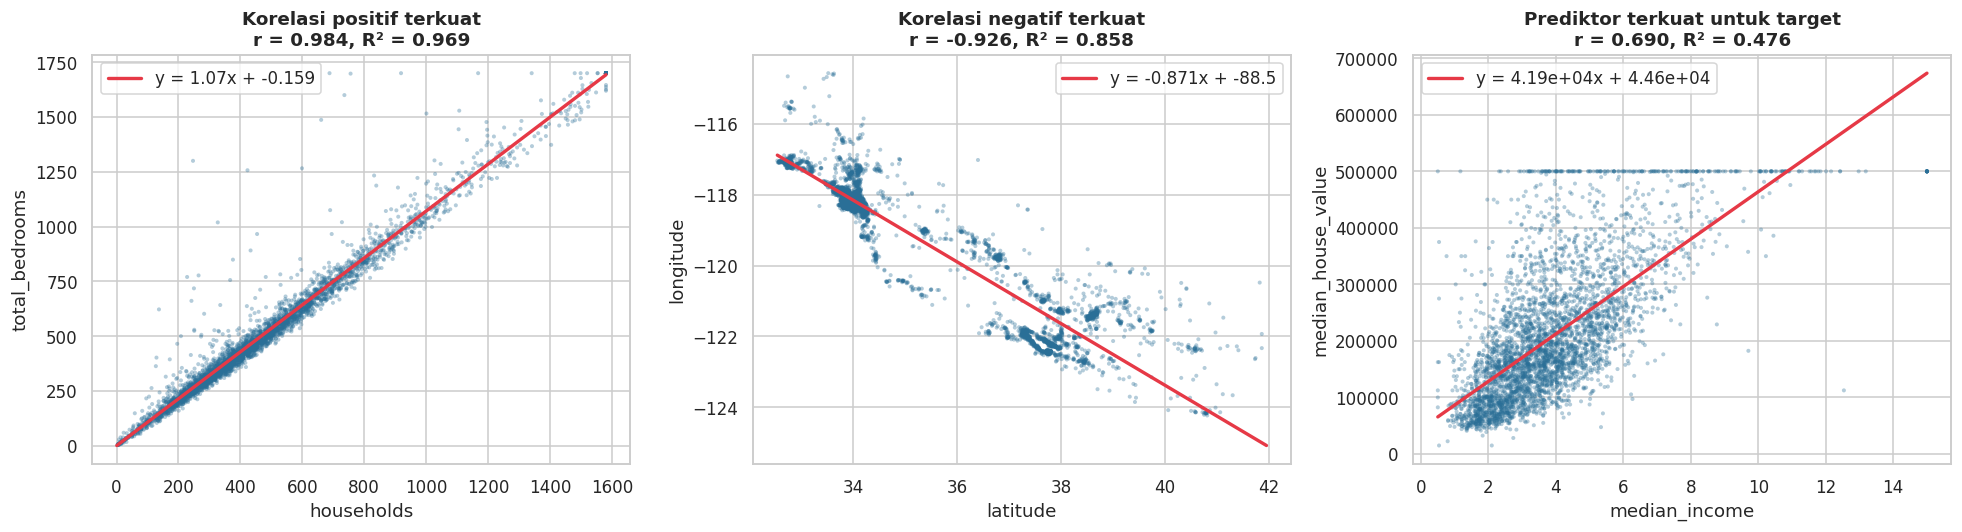

,X,Y,Pearson r,Spearman rho,R²,Slope,p-value
0,households,total_bedrooms,0.984,0.982,0.969,1.071,0.000
1,latitude,longitude,-0.926,-0.880,0.858,-0.871,0.000
2,median_income,median_house_value,0.690,0.678,0.476,"41,936.109",0.000


In [ ]:
trios = [(top_pos.Var1, top_pos.Var2, "Korelasi positif terkuat"),
         (top_neg.Var1, top_neg.Var2, "Korelasi negatif terkuat"),
         (BEST_PRED, TARGET, "Prediktor terkuat untuk target")]

samp = df.sample(4000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
reg_rows = []
for ax, (a, b, judul) in zip(axes, trios):
    ax.scatter(samp[a], samp[b], s=7, alpha=.35, color="#2a6f97", edgecolor="none")
    slope, intercept, r, p, se = stats.linregress(df[a], df[b])              # garis regresi dari SELURUH data
    xs = np.linspace(df[a].min(), df[a].max(), 100)
    ax.plot(xs, intercept + slope*xs, c="#e63946", lw=2.2, label=f"y = {slope:.3g}x + {intercept:.3g}")
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{judul}\nr = {r:.3f}, R² = {r**2:.3f}"); ax.legend(loc="best")
    rho = stats.spearmanr(df[a], df[b]).correlation
    reg_rows.append((a, b, r, rho, r**2, slope, p))
plt.tight_layout(); plt.show()
display(pd.DataFrame(reg_rows, columns=["X", "Y", "Pearson r", "Spearman rho", "R²", "Slope", "p-value"]))

**Gambar 8. Tiga pasangan variabel terpilih.** Titik adalah sampel 4.000 blok sensus, garis merah adalah regresi pada seluruh data. Kiri: korelasi positif terkuat (r = 0,984); tengah: korelasi negatif terkuat (r = −0,926), dua pita menunjukkan kelompok wilayah; kanan: pendapatan vs nilai rumah (r = 0,690) dengan pita datar di 500.001 akibat censoring.

**Interpretasi pola:**

1. **`households` vs `total_bedrooms` (r = 0,984; R² = 0,969).** Titik-titik hampir persis berada pada garis lurus dengan kemiringan 1,07: tiap tambahan satu rumah tangga rata-rata menambah sekitar satu kamar tidur. Sebaran melebar sedikit pada nilai besar, dan tumpukan di ujung kanan atas adalah efek cap pada 1.581 dan 1.700. Kedua variabel nyaris **redundan**, sehingga cukup satu yang dipakai pada model regresi atau diwakili komponen utama.
2. **`latitude` vs `longitude` (r = −0,926; R² = 0,858).** Titik membentuk dua pita diagonal yang terpisah: kelompok selatan (lintang sekitar 33–35, area Los Angeles–San Diego) dan kelompok tengah-utara (sekitar 36–39, area Teluk San Francisco/Central Valley). Garis lurus menyederhanakan bentuk ini, sehingga r tinggi tetapi hubungan sebenarnya adalah *dua kluster spasial*, bukan satu tren.
3. **`median_income` vs `median_house_value` (r = 0,690; R² = 0,476).** Hubungan positif yang jelas: tiap kenaikan 1 unit pendapatan (10 ribu USD) berkaitan dengan kenaikan nilai rumah sekitar 41.900 USD. Pola menyerupai kipas (varians nilai rumah melebar pada pendapatan tinggi, yaitu heteroskedastisitas) dan ada **pita datar horizontal di 500.001** yang melandaikan hubungan pada ujung atas. Pendapatan menjelaskan sekitar 48% variasi nilai rumah, sisanya dipengaruhi lokasi dan faktor lain.

### II.2.3 Tabulasi silang dan uji Chi-Square (dua variabel kategorik vs kelas nilai rumah)

Karena target (`median_house_value`) numerik, uji Chi-Square memakai versi kategoriknya, yaitu `value_cat` (Murah/Menengah/Mahal). Dua variabel kategorik yang saya duga berhubungan dengan harga rumah:

1. **`ocean_proximity`**: kedekatan dengan laut sering dikaitkan dengan harga tanah yang lebih mahal.
2. **`age_cat`**: usia bangunan, karena kawasan lama dan baru berbeda karakternya.

ocean_proximity  x  value_cat
Tabel tabulasi silang (frekuensi):


value_cat,Murah,Menengah,Mahal,Total
ocean_proximity,,,,
<1H OCEAN,1236,4003,3893,9132
INLAND,4647,1368,460,6475
ISLAND,0,0,5,5
NEAR BAY,397,728,1165,2290
NEAR OCEAN,573,760,1322,2655
Total,6853,6859,6845,20557


Persentase baris (%):


value_cat,Murah,Menengah,Mahal
ocean_proximity,,,
<1H OCEAN,13.535,43.835,42.630
INLAND,71.768,21.127,7.104
ISLAND,0.000,0.000,100.000
NEAR BAY,17.336,31.790,50.873
NEAR OCEAN,21.582,28.625,49.793


Chi-Square = 6,851.49 | dof = 8 | p-value = 0.000e+00 | Cramér's V = 0.408
Frekuensi harapan terkecil = 1.66  ->  sel dengan harapan < 5: 3 dari 15
Residual terstandarisasi (|nilai| > 2 = sel menyumbang asosiasi):


value_cat,Murah,Menengah,Mahal
ocean_proximity,,,
<1H OCEAN,-32.774,17.320,15.455
INLAND,53.561,-17.049,-36.526
ISLAND,-1.291,-1.292,2.585
NEAR BAY,-13.261,-1.305,14.576
NEAR OCEAN,-10.490,-4.229,14.729


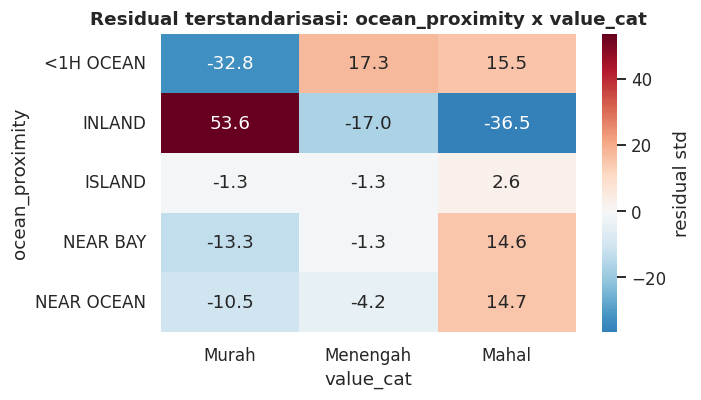

age_cat  x  value_cat
Tabel tabulasi silang (frekuensi):


value_cat,Murah,Menengah,Mahal,Total
age_cat,,,,
Baru (<=15),1195,1171,890,3256
Cukup baru (16-30),2701,2516,2605,7822
Lama (31-45),2325,2664,2284,7273
Sangat lama (>45),632,508,1066,2206
Total,6853,6859,6845,20557


Persentase baris (%):


value_cat,Murah,Menengah,Mahal
age_cat,,,
Baru (<=15),36.701,35.964,27.334
Cukup baru (16-30),34.531,32.166,33.304
Lama (31-45),31.968,36.629,31.404
Sangat lama (>45),28.649,23.028,48.323


Chi-Square = 329.04 | dof = 6 | p-value = 4.869e-68 | Cramér's V = 0.089
Frekuensi harapan terkecil = 734.55  ->  sel dengan harapan < 5: 0 dari 12
Residual terstandarisasi (|nilai| > 2 = sel menyumbang asosiasi):


value_cat,Murah,Menengah,Mahal
age_cat,,,
Baru (<=15),3.325,2.567,-5.897
Cukup baru (16-30),1.829,-1.837,0.009
Lama (31-45),-2.022,4.817,-2.799
Sangat lama (>45),-3.813,-8.406,12.230


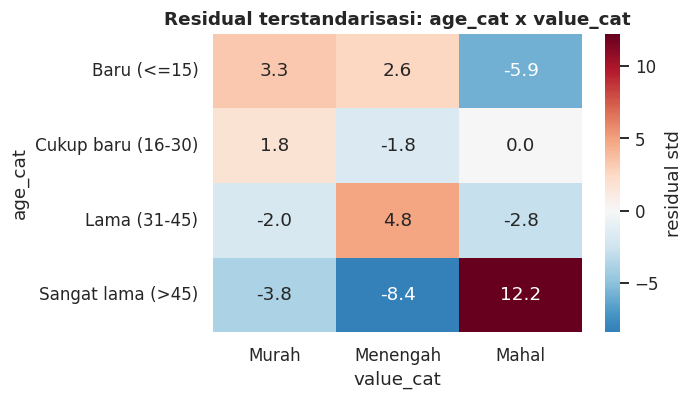


Uji ketahanan (ocean_proximity tanpa ISLAND): Chi2 = 6,841.27, dof = 6, p = 0.000e+00, V = 0.408, min harapan = 762.1


In [ ]:
def chi_square_report(var, target_cat="value_cat", drop=None):
    d = df if drop is None else df[~df[var].isin(drop)]
    obs = pd.crosstab(d[var], d[target_cat])
    chi2, p, dof, exp = stats.chi2_contingency(obs)
    n = obs.values.sum(); k = min(obs.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    exp = pd.DataFrame(exp, index=obs.index, columns=obs.columns)
    resid = (obs - exp) / np.sqrt(exp)                                    # residual terstandarisasi
    return obs, exp, resid, chi2, p, dof, v

for var in ["ocean_proximity", "age_cat"]:
    obs, exp, resid, chi2, p, dof, v = chi_square_report(var)
    print("=" * 90); print(f"{var}  x  value_cat"); print("=" * 90)
    print("Tabel tabulasi silang (frekuensi):");     display(pd.crosstab(df[var], df["value_cat"], margins=True, margins_name="Total"))
    print("Persentase baris (%):");                   display(pd.crosstab(df[var], df["value_cat"], normalize="index") * 100)
    print(f"Chi-Square = {chi2:,.2f} | dof = {dof} | p-value = {p:.3e} | Cramér's V = {v:.3f}")
    print(f"Frekuensi harapan terkecil = {exp.values.min():.2f}  ->  sel dengan harapan < 5: {(exp.values < 5).sum()} dari {exp.size}")
    print("Residual terstandarisasi (|nilai| > 2 = sel menyumbang asosiasi):"); display(resid)
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "residual std"})
    ax.set_title(f"Residual terstandarisasi: {var} x value_cat"); plt.tight_layout(); plt.show()

# Uji ketahanan: ocean_proximity tanpa ISLAND (n sangat kecil)
_, e2, _, chi2_b, p_b, dof_b, v_b = chi_square_report("ocean_proximity", drop=["ISLAND"])
print(f"\nUji ketahanan (ocean_proximity tanpa ISLAND): Chi2 = {chi2_b:,.2f}, dof = {dof_b}, p = {p_b:.3e}, V = {v_b:.3f}, min harapan = {e2.min().min():.1f}")

**Gambar 9–10. Residual terstandarisasi uji Chi-Square.** Sel merah (nilai positif) berarti frekuensi teramati lebih besar daripada yang diharapkan jika tidak ada hubungan, sel biru sebaliknya; |nilai| > 2 dianggap menyumbang asosiasi. Gambar 9 (`ocean_proximity`): blok `INLAND` sangat berlebih pada kelas Murah. Gambar 10 (`age_cat`): bangunan sangat lama berlebih pada kelas Mahal, tetapi asosiasinya lemah (V = 0,089).

**Hasil Chi-Square:**

| Variabel | χ² | dof | p-value | Cramér's V | Kekuatan asosiasi |
|---|---|---|---|---|---|
| `ocean_proximity` × `value_cat` | 6.851,5 | 8 | < 0,001 | **0,408** | Kuat |
| `age_cat` × `value_cat` | 329,0 | 6 | 4,9×10⁻⁶⁸ | **0,089** | Sangat lemah |

**`ocean_proximity`.** Hubungannya sangat signifikan dan cukup kuat. Residual terstandarisasi menunjukkan polanya: blok `INLAND` sangat berlebih pada kelas Murah (71,8% blok Inland tergolong murah; residual +53,6) dan sangat kurang pada kelas Mahal (7,1%; residual −36,5), sedangkan `NEAR BAY` (50,9% Mahal) dan `NEAR OCEAN` (49,8% Mahal) berlebih pada kelas Mahal. `<1H OCEAN` condong ke kelas Menengah–Mahal. Karena `ISLAND` hanya 5 baris, 3 dari 15 sel memiliki frekuensi harapan di bawah 5 (terkecil 1,66), tetapi uji ketahanan tanpa `ISLAND` memberi hasil hampir identik (χ² = 6.841,3; V = 0,408), jadi kesimpulan tidak bergantung pada kategori langka itu.

**`age_cat`.** p-value sangat kecil hanya karena n besar (20.557). Ukuran efeknya (V = 0,089) sangat lemah sehingga **signifikan secara statistik tetapi lemah secara praktis**. Pola yang ada: bangunan "Sangat lama (>45 tahun)" lebih sering berada di kelas Mahal (48,3%; residual +12,2), mungkin karena kawasan tua yang mapan di pusat kota atau area teluk. Bangunan baru (≤ 15 tahun) lebih sering Murah (36,7%).

**Catatan.** Variabel kategorik yang paling "menjelaskan" harga adalah **lokasi**, bukan usia bangunan.

### II.2.4 Perbandingan distribusi target antar kelompok (box plot, uji T / ANOVA)

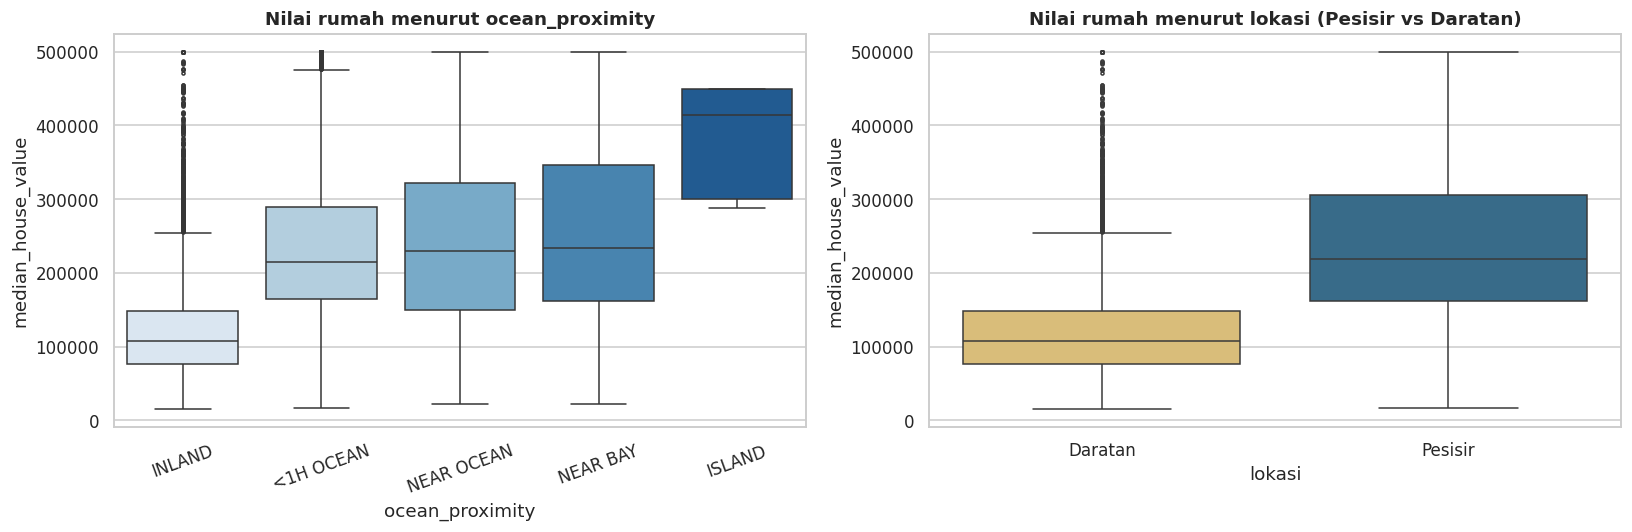

,count,mean,median,std
ocean_proximity,,,,
INLAND,6475,"124,326.660","108,200.000","69,739.036"
<1H OCEAN,9132,"240,040.246","214,800.000","106,097.093"
NEAR OCEAN,2655,"249,383.432","229,400.000","122,457.206"
NEAR BAY,2290,"259,212.312","233,800.000","122,818.537"
ISLAND,5,"380,440.000","414,700.000","80,559.562"


Asumsi normalitas per kelompok (Shapiro-Wilk, maks 5.000 sampel):
  <1H OCEAN    n= 9132  p = 4.72e-47
  INLAND       n= 6475  p = 1.92e-59
  ISLAND       n=    5  p = 8.27e-02
  NEAR BAY     n= 2290  p = 5.95e-30
  NEAR OCEAN   n= 2655  p = 8.59e-33
Uji homogenitas varians Levene (Brown-Forsythe): W = 440.28, p = 0.00e+00

ANOVA satu arah        : F = 1,610.4, p = 0.000e+00, eta² = 0.239
Welch ANOVA            : F = 2,090.6 (df1=4, df2=32), p = 4.046e-38
Kruskal-Wallis         : H = 6,632.1, p = 0.000e+00, epsilon² = 0.323

Uji lanjut (post-hoc) antar pasangan kategori:


,Kelompok A,Kelompok B,Selisih mean (A-B),p (Welch),p Bonferroni,"Signifikan (α=0,05)"
0,INLAND,<1H OCEAN,"-115,713.587",0.000,0.000,True
1,INLAND,NEAR OCEAN,"-125,056.772",0.000,0.000,True
2,INLAND,NEAR BAY,"-134,885.652",0.000,0.000,True
3,INLAND,ISLAND,"-256,113.340",0.002,0.021,True
4,<1H OCEAN,NEAR OCEAN,"-9,343.186",0.000,0.004,True
5,<1H OCEAN,NEAR BAY,"-19,172.065",0.000,0.000,True
6,<1H OCEAN,ISLAND,"-140,399.754",0.018,0.175,False
7,NEAR OCEAN,NEAR BAY,"-9,828.880",0.005,0.050,True
8,NEAR OCEAN,ISLAND,"-131,056.568",0.022,0.218,False
9,NEAR BAY,ISLAND,"-121,227.688",0.028,0.280,False



Uji T Welch (Pesisir vs Daratan): t = 93.96, p = 0.000e+00; selisih mean = 120,643 USD; Cohen's d = 1.20
Mann-Whitney U (pembanding non-parametrik): p = 0.000e+00


In [ ]:
order = df.groupby("ocean_proximity")[TARGET].median().sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="ocean_proximity", y=TARGET, order=order, palette="Blues", ax=axes[0], fliersize=2)
axes[0].set_title("Nilai rumah menurut ocean_proximity"); axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="lokasi", y=TARGET, order=["Daratan", "Pesisir"], palette=["#e9c46a", "#2a6f97"], ax=axes[1], fliersize=2)
axes[1].set_title("Nilai rumah menurut lokasi (Pesisir vs Daratan)")
plt.tight_layout(); plt.show()

grp = {k: g[TARGET].values for k, g in df.groupby("ocean_proximity")}
display(df.groupby("ocean_proximity")[TARGET].agg(["count", "mean", "median", "std"]).loc[order])

# ---- Cek asumsi ----
print("Asumsi normalitas per kelompok (Shapiro-Wilk, maks 5.000 sampel):")
for k, g in grp.items():
    gs = pd.Series(g).sample(min(len(g), 5000), random_state=SEED)
    print(f"  {k:12s} n={len(g):5d}  p = {stats.shapiro(gs).pvalue:.2e}" if len(g) >= 3 else f"  {k}: terlalu kecil")
lev = stats.levene(*grp.values(), center="median")
print(f"Uji homogenitas varians Levene (Brown-Forsythe): W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

# ---- ANOVA klasik, Welch ANOVA, Kruskal-Wallis ----
def welch_anova(groups):
    groups = [np.asarray(g, float) for g in groups if len(g) > 1]
    k = len(groups); n = np.array([len(g) for g in groups]); m = np.array([g.mean() for g in groups])
    v = np.array([g.var(ddof=1) for g in groups]); w = n / v; mw = (w * m).sum() / w.sum()
    A = (w * (m - mw)**2).sum() / (k - 1)
    lam = ((1 - w / w.sum())**2 / (n - 1)).sum()
    B = 1 + 2 * (k - 2) / (k**2 - 1) * lam
    F = A / B; df2 = (k**2 - 1) / (3 * lam)
    return F, k - 1, df2, stats.f.sf(F, k - 1, df2)

F, p_f = stats.f_oneway(*grp.values())
allv = df[TARGET].values; ssb = sum(len(g) * (g.mean() - allv.mean())**2 for g in grp.values()); sst = ((allv - allv.mean())**2).sum()
Fw, d1, d2, pw = welch_anova(grp.values())
H, p_kw = stats.kruskal(*grp.values())
print(f"\nANOVA satu arah        : F = {F:,.1f}, p = {p_f:.3e}, eta² = {ssb/sst:.3f}")
print(f"Welch ANOVA            : F = {Fw:,.1f} (df1={d1}, df2={d2:,.0f}), p = {pw:.3e}")
print(f"Kruskal-Wallis         : H = {H:,.1f}, p = {p_kw:.3e}, epsilon² = {H/(len(allv)-1):.3f}")

# ---- Post-hoc: uji Welch berpasangan + koreksi Bonferroni ----
import itertools
posthoc = []
pairs_ = list(itertools.combinations(order, 2))
for a, b in pairs_:
    t = stats.ttest_ind(grp[a], grp[b], equal_var=False)
    posthoc.append((a, b, grp[a].mean() - grp[b].mean(), t.pvalue, min(t.pvalue * len(pairs_), 1.0)))
posthoc = pd.DataFrame(posthoc, columns=["Kelompok A", "Kelompok B", "Selisih mean (A-B)", "p (Welch)", "p Bonferroni"])
posthoc["Signifikan (α=0,05)"] = posthoc["p Bonferroni"] < 0.05
print("\nUji lanjut (post-hoc) antar pasangan kategori:"); display(posthoc)

# ---- Uji T: Pesisir vs Daratan ----
a, b = df.loc[df.lokasi == "Pesisir", TARGET], df.loc[df.lokasi == "Daratan", TARGET]
tt = stats.ttest_ind(a, b, equal_var=False); mw_ = stats.mannwhitneyu(a, b)
sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2)); d_ = (a.mean() - b.mean()) / sp
print(f"\nUji T Welch (Pesisir vs Daratan): t = {tt.statistic:.2f}, p = {tt.pvalue:.3e}; selisih mean = {a.mean()-b.mean():,.0f} USD; Cohen's d = {d_:.2f}")
print(f"Mann-Whitney U (pembanding non-parametrik): p = {mw_.pvalue:.3e}")

**Gambar 11. Nilai rumah menurut lokasi.** Kiri: boxplot per kategori `ocean_proximity` (diurutkan menurut median); kanan: Pesisir vs Daratan. Garis tengah adalah median, kotak adalah Q1–Q3, titik adalah outlier. Nilai rumah di daratan jauh lebih rendah; kategori `ISLAND` hanya terdiri dari 5 observasi.

**Pemilihan uji.** Pengecekan asumsi menunjukkan: (1) distribusi nilai rumah tidak normal di setiap kelompok (Shapiro p ≈ 10⁻³⁰ sampai 10⁻⁵⁹; `ISLAND` tidak dapat diuji andal karena n = 5) dan (2) varians tidak homogen (Levene W = 440,3, p ≈ 0). Karena itu ANOVA klasik kurang tepat, sehingga saya melaporkan **Welch ANOVA** (tahan terhadap varians tak sama) dan **Kruskal-Wallis** (tanpa asumsi normalitas) sebagai pendamping, sedangkan ANOVA klasik hanya sebagai pembanding.

**Hasil:**

- Median nilai rumah menurut kategori: `INLAND` 108.200 < `<1H OCEAN` 214.800 < `NEAR OCEAN` 229.400 < `NEAR BAY` 233.800 < `ISLAND` 414.700 (n = 5).
- ANOVA: F = 1.610,4 (η² = 0,239); Welch ANOVA: F = 2.090,6, p = 4×10⁻³⁸; Kruskal-Wallis: H = 6.632,1 (ε² = 0,323); semuanya p < 0,001. **Perbedaan antar kelompok signifikan secara statistik dan juga besar secara praktis**: lokasi menjelaskan sekitar 24% (η²) variasi nilai rumah.
- **Uji lanjut (Welch berpasangan, koreksi Bonferroni):** `INLAND` berbeda nyata dari seluruh kategori lain (rata-rata 116 ribu sampai 135 ribu USD lebih rendah daripada ketiga kategori pesisir utama, dan 256 ribu lebih rendah daripada `ISLAND`). Di antara kategori pesisir, selisihnya jauh lebih kecil, hanya sekitar 9 ribu sampai 19 ribu USD, meskipun tetap signifikan (`NEAR OCEAN` vs `NEAR BAY` tepat di batas, p Bonferroni = 0,050). Perbandingan dengan `ISLAND` tidak signifikan setelah koreksi, walaupun selisih rata-ratanya besar, karena n = 5.
- **Uji T Welch Pesisir vs Daratan:** rata-rata Pesisir lebih tinggi **120.643 USD** (t = 93,96, p ≈ 0; Cohen's d = 1,20, efek besar). Mann-Whitney memberi kesimpulan sama.

**Kesimpulan:** perbedaan nilai rumah antar kelompok lokasi **signifikan secara statistik**. Premi utama adalah *pesisir vs daratan*, sedangkan perbedaan antar kategori pesisir jauh lebih kecil.

In [ ]:
# ---- Pembanding ukuran efek: lokasi (biner) vs ocean_proximity (5 kategori) terhadap nilai rumah ----
def eta_sq(col):
    g = {k: v[TARGET].values for k, v in df.groupby(col)}
    allv = df[TARGET].values
    return sum(len(x) * (x.mean() - allv.mean())**2 for x in g.values()) / ((allv - allv.mean())**2).sum()
e_oc, e_lok = eta_sq("ocean_proximity"), eta_sq("lokasi")
# gradasi di dalam pesisir: ukuran efek tiga kategori pesisir utama saja
pes = df[df["ocean_proximity"].isin(["<1H OCEAN", "NEAR BAY", "NEAR OCEAN"])]
g3 = {k: v[TARGET].values for k, v in pes.groupby("ocean_proximity")}
e_in = sum(len(x) * (x.mean() - pes[TARGET].mean())**2 for x in g3.values()) / ((pes[TARGET] - pes[TARGET].mean())**2).sum()
print(f"eta^2 ocean_proximity (5 kategori) : {e_oc:.3f}")
print(f"eta^2 lokasi (Pesisir/Daratan)     : {e_lok:.3f}  -> {e_lok/e_oc*100:.0f}% dari eta^2 ocean_proximity")
print(f"eta^2 antar 3 kategori pesisir saja: {e_in:.3f}  (gradasi di dalam pesisir)")

eta^2 ocean_proximity (5 kategori) : 0.239
eta^2 lokasi (Pesisir/Daratan)     : 0.236  -> 99% dari eta^2 ocean_proximity
eta^2 antar 3 kategori pesisir saja: 0.004  (gradasi di dalam pesisir)


---
# Bagian III — Analisis Multivariat dan Interpretasi
## III.1 Reduksi Dimensi dengan PCA
### III.1.1 Pemilihan variabel untuk PCA

In [ ]:
PCA_VARS = NUM_MODEL.copy()
seleksi = pd.DataFrame([(v, "DIMASUKKAN", "Numerik, relevan dengan karakter hunian/ukuran blok" + (f" (ditransformasi: {TRANS[v]})" if TRANS[v] != "asli" else "")) for v in PCA_VARS] + [
    ("longitude, latitude", "DIKELUARKAN", "Koordinat geografis bersifat non-linear (bukan skala ukuran); hubungannya dengan harga bersifat spasial, bukan gradien linear yang cocok untuk PCA."),
    ("median_house_value", "DIKELUARKAN", "Variabel target. Dikeluarkan agar PC1 bebas dari target sehingga kemampuan prediktifnya (III.1.6) dapat dinilai jujur dan tidak ada kebocoran informasi."),
    ("ocean_proximity, lokasi, *_cat", "DIKELUARKAN", "Kategorik. PCA bekerja pada kovarians numerik."),
    ("flag_*", "DIKELUARKAN", "Penanda biner pipeline, bukan karakteristik blok sensus."),
], columns=["Variabel", "Status", "Alasan"])
pd.set_option("display.max_colwidth", 200)
display(seleksi)
print("\nJumlah variabel dalam PCA:", len(PCA_VARS))
display(X_scaled[PCA_VARS].corr().round(2))

,Variabel,Status,Alasan
0,housing_median_age,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok"
1,total_rooms,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: akar kuadrat)"
2,total_bedrooms,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: akar kuadrat)"
3,population,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: akar kuadrat)"
4,households,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: akar kuadrat)"
5,median_income,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: log1p)"
6,rooms_per_household,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: log1p)"
7,bedrooms_per_room,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: akar kuadrat)"
8,population_per_household,DIMASUKKAN,"Numerik, relevan dengan karakter hunian/ukuran blok (ditransformasi: log1p)"
9,"longitude, latitude",DIKELUARKAN,"Koordinat geografis bersifat non-linear (bukan skala ukuran); hubungannya dengan harga bersifat spasial, bukan gradien linear yang cocok untuk PCA."



Jumlah variabel dalam PCA: 9


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household
housing_median_age,1.000,-0.370,-0.320,-0.300,-0.300,-0.140,-0.220,0.150,-0.020
total_rooms,-0.370,1.000,0.930,0.860,0.930,0.270,0.260,-0.240,-0.150
total_bedrooms,-0.320,0.930,1.000,0.900,0.980,0.010,-0.040,0.110,-0.180
population,-0.300,0.860,0.900,1.000,0.920,0.020,-0.090,0.060,0.210
households,-0.300,0.930,0.980,0.920,1.000,0.040,-0.090,0.080,-0.160
median_income,-0.140,0.270,0.010,0.020,0.040,1.000,0.620,-0.700,-0.060
rooms_per_household,-0.220,0.260,-0.040,-0.090,-0.090,0.620,1.000,-0.850,-0.020
bedrooms_per_room,0.150,-0.240,0.110,0.060,0.080,-0.700,-0.850,1.000,-0.040
population_per_household,-0.020,-0.150,-0.180,0.210,-0.160,-0.060,-0.020,-0.040,1.000


### III.1.2 Standardisasi dan mengapa wajib sebelum PCA

In [ ]:
var_tbl = pd.DataFrame({"Varians data asli": df[PCA_VARS].var(), "Varians setelah transformasi + Z-score": X_scaled[PCA_VARS].var(ddof=0)})
display(var_tbl)

# Demonstrasi: PCA pada data mentah (tanpa standardisasi) vs PCA pada data terstandarisasi
evr_raw    = PCA().fit(df[PCA_VARS]).explained_variance_ratio_
evr_scaled = PCA().fit(X_scaled[PCA_VARS]).explained_variance_ratio_
print(f"PCA TANPA standardisasi: PC1 menjelaskan {evr_raw[0]*100:.1f}% varians")
pc1_raw = pd.Series(PCA().fit(df[PCA_VARS]).components_[0], index=PCA_VARS).abs().sort_values(ascending=False)
print("  Loading |PC1| (data mentah) terbesar:", pc1_raw.head(2).round(3).to_dict(), "-> PC1 hanya mencerminkan variabel berskala besar")
print(f"PCA DENGAN standardisasi : PC1 menjelaskan {evr_scaled[0]*100:.1f}% varians, PC2 {evr_scaled[1]*100:.1f}%")

,Varians data asli,Varians setelah transformasi + Z-score
housing_median_age,158.193,1.000
total_rooms,"2,781,671.926",1.000
total_bedrooms,"116,957.387",1.000
population,"811,719.244",1.000
households,"98,807.050",1.000
median_income,3.604,1.000
rooms_per_household,2.019,1.000
bedrooms_per_room,0.003,1.000
population_per_household,0.749,1.000


PCA TANPA standardisasi: PC1 menjelaskan 94.5% varians
  Loading |PC1| (data mentah) terbesar: {'total_rooms': 0.872, 'population': 0.43} -> PC1 hanya mencerminkan variabel berskala besar
PCA DENGAN standardisasi : PC1 menjelaskan 43.7% varians, PC2 28.5%


**Alasan standardisasi wajib.** PCA mencari arah dengan *varians terbesar*. Variabel dengan skala besar (mis. `total_rooms` dalam ribuan) memiliki varians jauh lebih besar daripada variabel berskala kecil (mis. `bedrooms_per_room` sekitar 0,2), sehingga tanpa standardisasi komponen utama hanya mengikuti variabel berskala besar, bukan struktur korelasi sebenarnya. Standardisasi (rata-rata 0, simpangan baku 1) menyamakan peran setiap variabel, sehingga PCA berbasis **matriks korelasi**. Transformasi akar kuadrat/log1p sebelumnya juga mengurangi pengaruh ekor panjang.

### III.1.3 Explained variance, scree plot, dan jumlah PC optimal (aturan 80%)

,PC,Eigenvalue,Explained variance ratio,Kumulatif
0,PC1,3.935,0.437,0.437
1,PC2,2.562,0.285,0.722
2,PC3,1.116,0.124,0.846
3,PC4,0.816,0.091,0.936
4,PC5,0.403,0.045,0.981
5,PC6,0.144,0.016,0.997
6,PC7,0.014,0.002,0.999
7,PC8,0.009,0.001,1.000
8,PC9,0.002,0.000,1.000


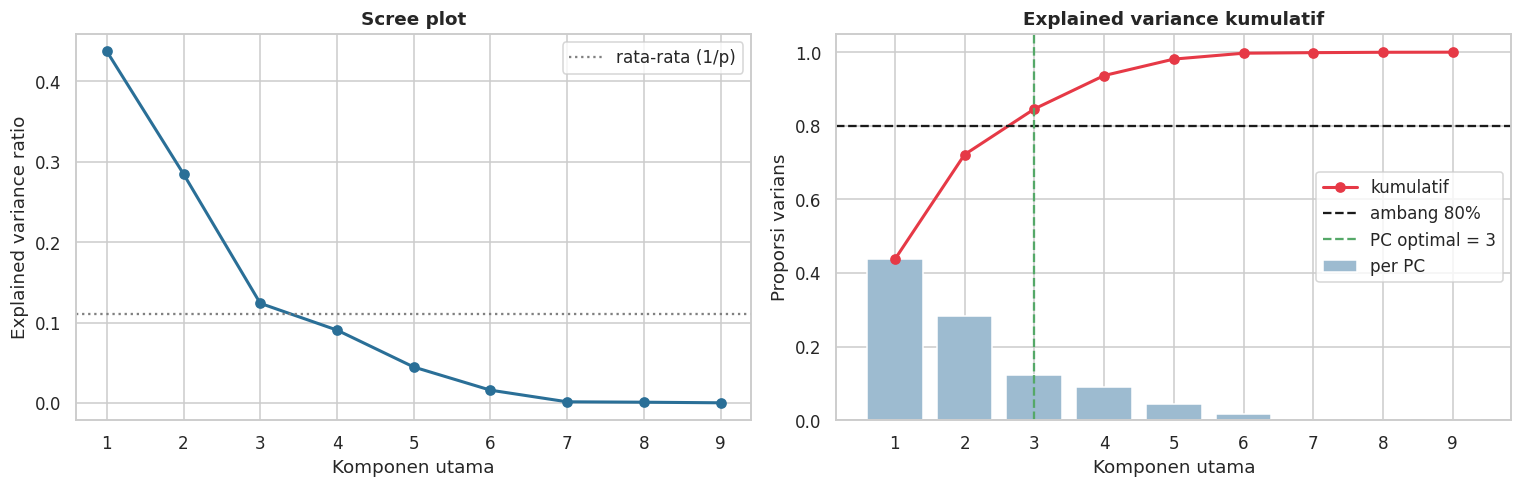

Jumlah PC optimal (aturan 80% varians kumulatif): 3  (kumulatif = 84.6%)
Pembanding kriteria Kaiser (eigenvalue > 1): 3 komponen


In [ ]:
pca = PCA(random_state=SEED).fit(X_scaled[PCA_VARS])
evr = pca.explained_variance_ratio_; cum = evr.cumsum(); eig = pca.explained_variance_
n_pc80 = int(np.argmax(cum >= 0.80) + 1)

ev_tbl = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))], "Eigenvalue": eig,
                       "Explained variance ratio": evr, "Kumulatif": cum})
display(ev_tbl)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(range(1, len(evr)+1), evr, "o-", color="#2a6f97", lw=2); axes[0].set_xlabel("Komponen utama"); axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Scree plot"); axes[0].set_xticks(range(1, len(evr)+1))
axes[0].axhline(1/len(evr), c="gray", ls=":", label="rata-rata (1/p)")
axes[0].legend()
axes[1].bar(range(1, len(evr)+1), evr, color="#9dbbd0", label="per PC")
axes[1].plot(range(1, len(evr)+1), cum, "o-", color="#e63946", lw=2, label="kumulatif")
axes[1].axhline(0.8, c="k", ls="--", label="ambang 80%"); axes[1].axvline(n_pc80, c="g", ls="--", label=f"PC optimal = {n_pc80}")
axes[1].set_xlabel("Komponen utama"); axes[1].set_ylabel("Proporsi varians"); axes[1].set_xticks(range(1, len(evr)+1))
axes[1].set_title("Explained variance kumulatif"); axes[1].legend(loc="center right")
plt.tight_layout(); plt.show()

print(f"Jumlah PC optimal (aturan 80% varians kumulatif): {n_pc80}  (kumulatif = {cum[n_pc80-1]*100:.1f}%)")
print(f"Pembanding kriteria Kaiser (eigenvalue > 1): {int((eig > 1).sum())} komponen")

**Gambar 12. Scree plot dan varians kumulatif.** Kiri: proporsi varians tiap komponen; garis putus-putus abu-abu adalah rata-rata (1/p). Kanan: batang adalah varians per komponen, garis merah kumulatif; garis hitam adalah ambang 80% dan garis hijau menandai jumlah PC optimal (3 komponen, 84,6%).

### III.1.4 Loading matrix dan interpretasi setiap PC

,PC1,PC2,PC3
housing_median_age,-0.224,0.127,-0.177
total_rooms,0.493,-0.086,-0.064
total_bedrooms,0.487,0.125,-0.097
population,0.464,0.123,0.275
households,0.488,0.126,-0.077
median_income,0.091,-0.510,-0.066
rooms_per_household,0.058,-0.571,0.004
bedrooms_per_room,-0.049,0.585,-0.055
population_per_household,-0.051,0.006,0.931


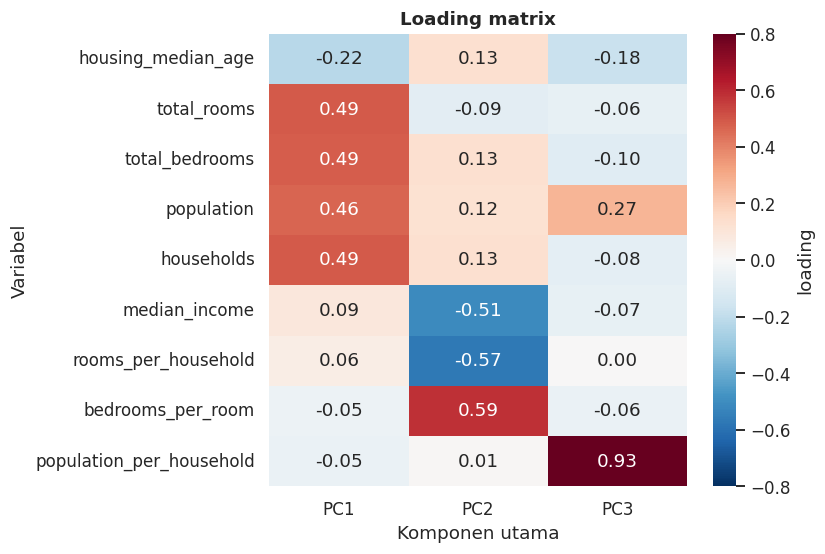

PC1 (43.7% varians) — kontributor terbesar: total_rooms (+0.49), households (+0.49), total_bedrooms (+0.49), population (+0.46)
PC2 (28.5% varians) — kontributor terbesar: bedrooms_per_room (+0.59), rooms_per_household (-0.57), median_income (-0.51), housing_median_age (+0.13)
PC3 (12.4% varians) — kontributor terbesar: population_per_household (+0.93), population (+0.27), housing_median_age (-0.18), total_bedrooms (-0.10)


In [ ]:
# Orientasi tanda: tanda PC bersifat sembarang. Dibuat agar loading terbesar (mutlak) tiap PC bernilai positif.
comps = pca.components_.copy()
for i in range(comps.shape[0]):
    if comps[i, np.abs(comps[i]).argmax()] < 0:
        comps[i] *= -1
pca.components_ = comps

K_SHOW = max(n_pc80, 3)
loadings = pd.DataFrame(comps[:K_SHOW].T, index=PCA_VARS, columns=[f"PC{i+1}" for i in range(K_SHOW)])
display(loadings)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.8, vmax=.8, ax=ax, cbar_kws={"label": "loading"})
ax.set_title("Loading matrix"); ax.set_xlabel("Komponen utama"); ax.set_ylabel("Variabel"); plt.tight_layout(); plt.show()

for c in loadings.columns:
    top = loadings[c].abs().sort_values(ascending=False).head(4).index
    print(f"{c} ({evr[int(c[2:])-1]*100:.1f}% varians) — kontributor terbesar:", ", ".join(f"{t} ({loadings.loc[t, c]:+.2f})" for t in top))

**Gambar 13. Loading matrix.** Nilai adalah bobot tiap variabel pada komponen utama (merah positif, biru negatif). PC1 didominasi variabel ukuran blok, PC2 oleh rasio ruangan dan pendapatan, PC3 oleh `population_per_household`.

**Interpretasi komponen (3 PC = 84,6% varians):**

| PC | Varians | Kontributor utama (loading) | Interpretasi |
|---|---|---|---|
| **PC1** | 43,7% | `total_rooms` (+0,49), `households` (+0,49), `total_bedrooms` (+0,49), `population` (+0,46); `housing_median_age` (−0,22) | **Ukuran blok sensus.** Skor tinggi berarti blok besar dan relatif baru; skor rendah berarti blok kecil dan lebih tua. |
| **PC2** | 28,5% | `bedrooms_per_room` (+0,59), `rooms_per_household` (−0,57), `median_income` (−0,51) | **Keluasan dan kemapanan hunian.** Skor tinggi berarti rumah ringkas, porsi kamar tidur besar, pendapatan rendah; skor rendah berarti rumah luas dan berpendapatan tinggi. |
| **PC3** | 12,4% | `population_per_household` (+0,93), `population` (+0,27) | **Kepadatan penghuni** per rumah tangga. |

Tanda komponen bersifat sembarang; di sini diorientasikan agar loading mutlak terbesar bernilai positif. Keempat variabel ukuran blok memuat hampir sama pada PC1, sejalan dengan korelasi >0,86 di antara mereka. Variabel yang mencerminkan kualitas hunian (rasio dan pendapatan) mengelompok sendiri di PC2.

In [ ]:
# ---- Uji sensitivitas: PCA dengan SATU wakil ukuran blok (households) ----
# Empat variabel cacahan hampir kembar (r 0,85-0,98) sehingga PC1 pada PCA utama dapat membengkak karena redundansi pemilihan variabel.
PCA_RED = ["housing_median_age", "households", "median_income", "rooms_per_household", "bedrooms_per_room", "population_per_household"]
pca_r = PCA(random_state=SEED).fit(X_scaled[PCA_RED])
evr_r = pca_r.explained_variance_ratio_
print("PCA utama (9 variabel)       : EVR PC1-PC3 =", np.round(evr[:3], 3), "| kumulatif 3 PC =", round(cum[2], 3))
print("PCA tereduksi (6 variabel)   : EVR PC1-PC3 =", np.round(evr_r[:3], 3), "| kumulatif 3 PC =", round(evr_r[:3].sum(), 3))
load_r = pd.DataFrame(pca_r.components_[:3].T, index=PCA_RED, columns=["PC1", "PC2", "PC3"])
display(load_r.round(3))
sc_r = pca_r.transform(X_scaled[PCA_RED])
print("Korelasi tiap PC (PCA tereduksi) dengan target:",
      {f"PC{i+1}": round(stats.pearsonr(sc_r[:, i], df[TARGET])[0], 3) for i in range(6)})

PCA utama (9 variabel)       : EVR PC1-PC3 = [0.437 0.285 0.124] | kumulatif 3 PC = 0.846
PCA tereduksi (6 variabel)   : EVR PC1-PC3 = [0.418 0.222 0.168] | kumulatif 3 PC = 0.808


,PC1,PC2,PC3
housing_median_age,0.187,-0.563,-0.484
households,0.015,0.736,0.044
median_income,-0.529,0.020,-0.128
rooms_per_household,-0.579,-0.071,-0.014
bedrooms_per_room,0.591,0.112,0.012
population_per_household,0.008,-0.352,0.865


Korelasi tiap PC (PCA tereduksi) dengan target: {'PC1': np.float64(-0.422), 'PC2': np.float64(0.046), 'PC3': np.float64(-0.373), 'PC4': np.float64(0.247), 'PC5': np.float64(0.429), 'PC6': np.float64(0.158)}


**Uji sensitivitas terhadap redundansi variabel.** Empat variabel cacahan (`total_rooms`, `total_bedrooms`, `population`, `households`) hampir kembar (r 0,85 sampai 0,98). Memasukkan keempatnya sekaligus membuat PC1 didominasi satu dimensi "ukuran blok" yang sebagian merupakan **artefak pemilihan variabel**, bukan struktur data yang alami. Untuk memeriksanya, PCA diulang dengan satu wakil ukuran blok saja (`households`) dan enam variabel.

Hasilnya: tiga PC menjelaskan 80,8% varians (PC1 41,8%; PC2 22,2%; PC3 16,8%). PC1 kini menjadi dimensi **kemapanan hunian** (`bedrooms_per_room` +0,59, `rooms_per_household` −0,58, `median_income` −0,53) dan berkorelasi −0,42 dengan target. Dimensi **ukuran blok** turun menjadi PC2 (`households` +0,74; `housing_median_age` −0,56) dan tetap tidak berkaitan dengan harga (r = 0,05). Jadi kesimpulan substantifnya bertahan, yaitu ukuran blok tidak menentukan harga, tetapi pernyataan bahwa ukuran blok adalah "dimensi terbesar dalam data" hanya berlaku pada kumpulan sembilan variabel di atas, bukan sifat data secara umum. Koordinat `longitude` dan `latitude` dikeluarkan bukan karena tidak bersifat numerik, melainkan karena tujuan segmentasi adalah menggambarkan **tipe blok** (karakter hunian), sedangkan lokasi dibahas terpisah lewat `ocean_proximity` dan peta klaster.

### III.1.5 Biplot PC1 vs PC2 diwarnai variabel target (`value_cat`)

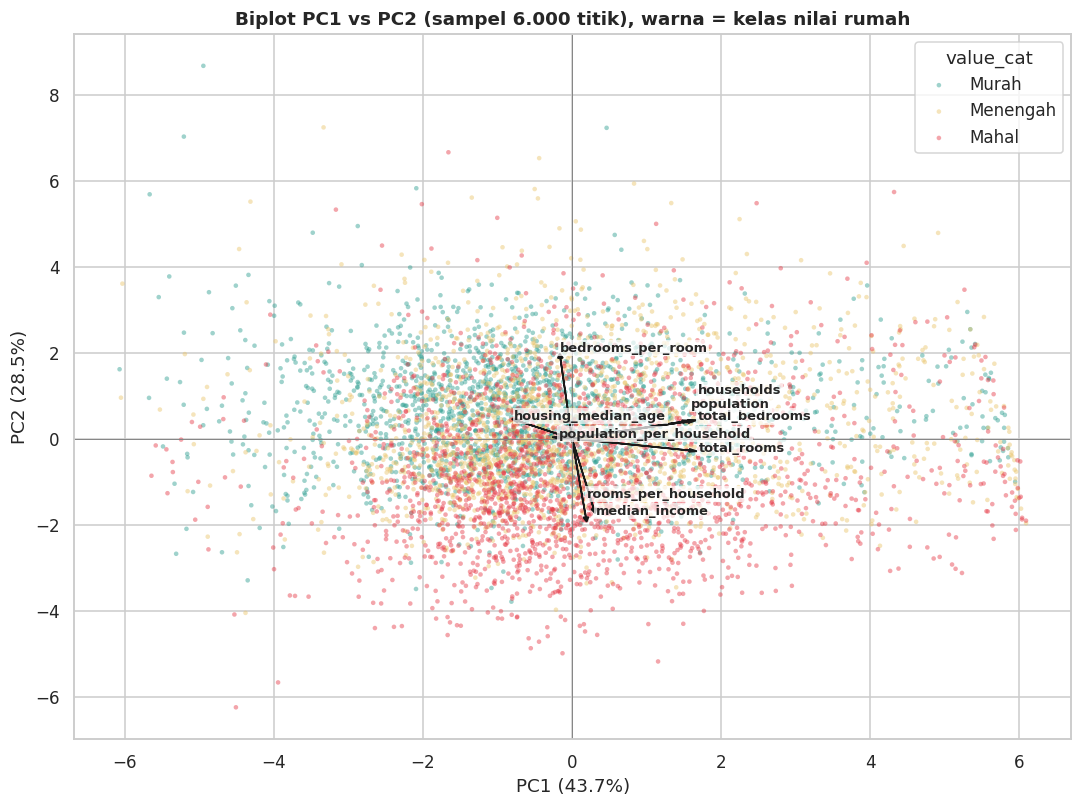

,PC1,PC2
value_cat,,
Murah,-0.369,0.575
Menengah,0.103,0.234
Mahal,0.266,-0.810


Silhouette kelas value_cat di ruang PC1-PC2: -0.006  (mendekati 0 = tumpang tindih; > 0,5 = terpisah baik)
Kruskal-Wallis PC1 antar kelas value_cat: H = 399.8, p = 1.50e-87, epsilon² = 0.019
Kruskal-Wallis PC2 antar kelas value_cat: H = 3,003.8, p = 0.00e+00, epsilon² = 0.146


In [ ]:
scores = pd.DataFrame(X_scaled[PCA_VARS].values @ comps.T, index=df.index, columns=[f"PC{i+1}" for i in range(comps.shape[0])])
df["PC1"], df["PC2"] = scores["PC1"], scores["PC2"]

pal = {"Murah": "#2a9d8f", "Menengah": "#e9c46a", "Mahal": "#e63946"}
sm = scores.join(df["value_cat"]).sample(6000, random_state=SEED)

fig, ax = plt.subplots(figsize=(10, 7.5))
for k in ["Murah", "Menengah", "Mahal"]:
    d_ = sm[sm.value_cat == k]; ax.scatter(d_["PC1"], d_["PC2"], s=9, alpha=.45, c=pal[k], label=k, edgecolor="none")
sc_ = 3.2
placed = []                                           # penempatan label sederhana agar teks panah tidak saling menimpa
for v in PCA_VARS:
    ax.arrow(0, 0, loadings.loc[v, "PC1"]*sc_, loadings.loc[v, "PC2"]*sc_, color="k", head_width=.07, lw=1.1)
    tx, ty = loadings.loc[v, "PC1"]*sc_*1.08, loadings.loc[v, "PC2"]*sc_*1.08
    while any(abs(tx - px) < 1.6 and abs(ty - py) < 0.28 for px, py in placed):
        ty += 0.3
    placed.append((tx, ty))
    ax.text(tx, ty, v, fontsize=8.5, weight="bold", bbox=dict(fc="white", ec="none", alpha=.7, pad=1))
ax.axhline(0, c="gray", lw=.6); ax.axvline(0, c="gray", lw=.6)
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title("Biplot PC1 vs PC2 (sampel 6.000 titik), warna = kelas nilai rumah"); ax.legend(title="value_cat")
plt.tight_layout(); plt.show()

# ---- Ukuran kuantitatif pemisahan kelas ----
cent = scores[["PC1", "PC2"]].groupby(df["value_cat"]).mean(); display(cent.round(3))
sil_pc = silhouette_score(scores[["PC1", "PC2"]].sample(8000, random_state=SEED), df.loc[scores[["PC1", "PC2"]].sample(8000, random_state=SEED).index, "value_cat"].astype(str))
print(f"Silhouette kelas value_cat di ruang PC1-PC2: {sil_pc:.3f}  (mendekati 0 = tumpang tindih; > 0,5 = terpisah baik)")
for pc in ["PC1", "PC2"]:
    H_, p_ = stats.kruskal(*[g[pc].values for _, g in scores.join(df["value_cat"]).groupby("value_cat")])
    print(f"Kruskal-Wallis {pc} antar kelas value_cat: H = {H_:,.1f}, p = {p_:.2e}, epsilon² = {H_/(len(df)-1):.3f}")

**Gambar 14. Biplot PC1 vs PC2.** Titik adalah sampel 6.000 blok sensus yang diwarnai kelas nilai rumah (Murah, Menengah, Mahal); panah hitam adalah arah dan besar loading variabel. Kelas Mahal condong ke PC2 negatif dan kelas Murah ke PC2 positif, tetapi tumpang tindih besar (silhouette −0,006).

**Apakah PC mampu memisahkan kelas nilai rumah?** Hanya **sebagian, berupa gradien dan bukan kelompok yang terpisah**.

- Pada biplot, titik kelas **Mahal** (merah) condong ke bagian bawah (PC2 negatif; rata-rata −0,81), kelas **Murah** (hijau) ke bagian atas (PC2 +0,58), dan **Menengah** di antaranya (+0,23). Panah `median_income` dan `rooms_per_household` mengarah ke bawah, ke wilayah merah, sedangkan `bedrooms_per_room` mengarah ke atas, ke wilayah hijau.
- Sepanjang **PC1 (ukuran blok)** rata-rata ketiga kelas hampir sama (−0,37; +0,10; +0,27). Uji Kruskal-Wallis memperlihatkan PC2 jauh lebih terkait dengan kelas harga (ε² = 0,146) dibanding PC1 (ε² = 0,019).
- Namun tumpang tindih tetap besar: **silhouette kelas nilai rumah di ruang PC1–PC2 = −0,006** (hampir nol, bahkan sedikit negatif), artinya kelas tidak membentuk kluster terpisah.

**Artinya:** pada sembilan variabel yang dipilih, dimensi terbesar (ukuran blok, sebagian akibat redundansi empat variabel cacahan; lihat uji sensitivitas di atas) hampir tidak terkait dengan harga. Informasi harga lebih banyak berada pada kemapanan hunian (PC2) dan pada hal yang tidak masuk PCA, yaitu **lokasi**.

### III.1.6 Skor komposit PC1 dan kemampuannya memprediksi target

Bobot PC1: {'housing_median_age': np.float64(-0.224), 'total_rooms': np.float64(0.493), 'total_bedrooms': np.float64(0.487), 'population': np.float64(0.464), 'households': np.float64(0.488), 'median_income': np.float64(0.091), 'rooms_per_household': np.float64(0.058), 'bedrooms_per_room': np.float64(-0.049), 'population_per_household': np.float64(-0.051)}

Korelasi skor PC1 dengan target: Pearson r = 0.110 (R² = 0.012) | Spearman rho = 0.148


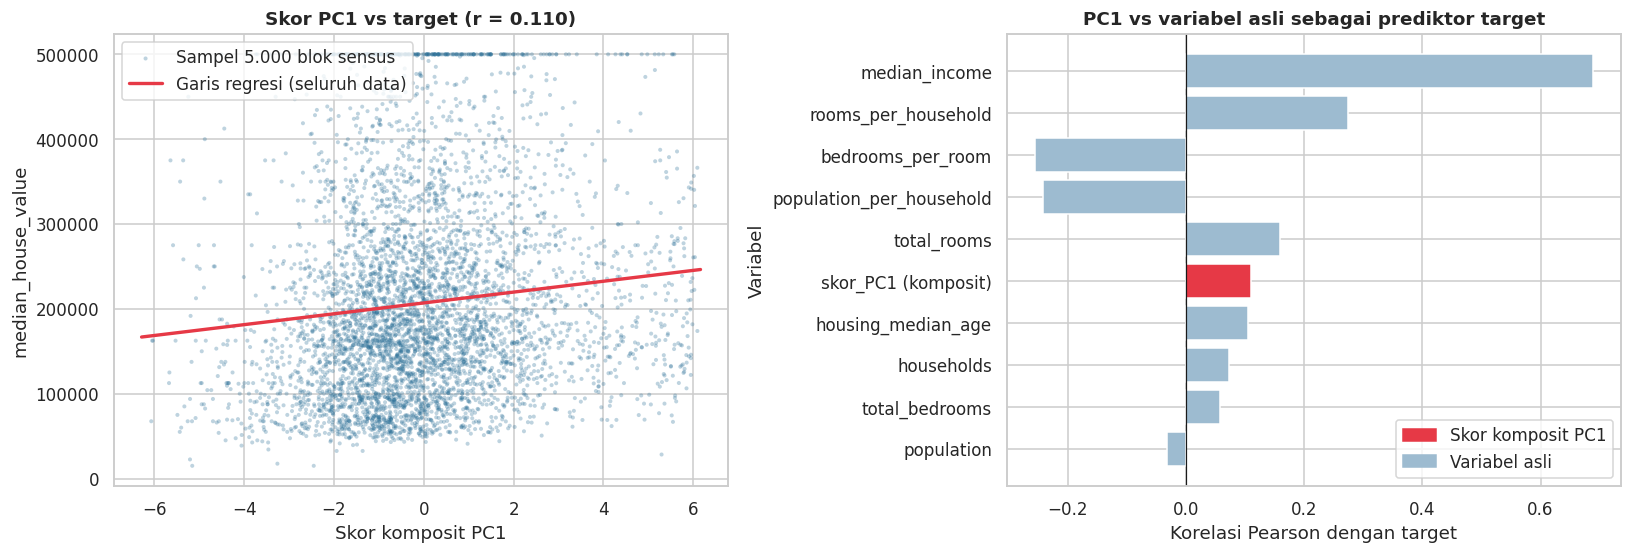

,"R² validasi silang (5-fold, shuffle)"
Skor PC1 saja,0.012
Variabel tunggal terbaik (median_income),0.451
PC1 + PC2,0.182
Seluruh 9 variabel (regresi linear),0.591


,Pearson r dengan target,R²
PC1,0.110,0.012
PC2,-0.412,0.170
PC3,-0.312,0.097
PC4,0.252,0.063
PC5,0.468,0.219
PC6,0.166,0.028


In [ ]:
# Skor komposit PC1 = proyeksi data terstandarisasi ke arah PC1 = sum_j( loading_j * z_j )
w1 = comps[0]
skor_pc1 = X_scaled[PCA_VARS].values @ w1
assert np.allclose(skor_pc1, scores["PC1"].values)          # sama dengan hasil transform PCA
df["skor_PC1"] = skor_pc1
print("Bobot PC1:", dict(zip(PCA_VARS, w1.round(3))))

r_p = stats.pearsonr(df["skor_PC1"], df[TARGET]); r_s = stats.spearmanr(df["skor_PC1"], df[TARGET])
print(f"\nKorelasi skor PC1 dengan target: Pearson r = {r_p[0]:.3f} (R² = {r_p[0]**2:.3f}) | Spearman rho = {r_s.correlation:.3f}")

samp = df.sample(5000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].scatter(samp["skor_PC1"], samp[TARGET], s=7, alpha=.3, c="#2a6f97", edgecolor="none", label="Sampel 5.000 blok sensus")
sl, ic, *_ = stats.linregress(df["skor_PC1"], df[TARGET]); xs = np.linspace(df.skor_PC1.min(), df.skor_PC1.max(), 100)
axes[0].plot(xs, ic + sl*xs, c="#e63946", lw=2.2, label="Garis regresi (seluruh data)"); axes[0].legend(loc="upper left"); axes[0].set_xlabel("Skor komposit PC1"); axes[0].set_ylabel(TARGET)
axes[0].set_title(f"Skor PC1 vs target (r = {r_p[0]:.3f})")

# Perbandingan dengan variabel asli
cmp_r = pd.Series({v: stats.pearsonr(df[v], df[TARGET])[0] for v in PCA_VARS})
cmp_r["skor_PC1 (komposit)"] = r_p[0]
cmp_r = cmp_r.reindex(cmp_r.abs().sort_values().index)
axes[1].barh(cmp_r.index, cmp_r.values, color=["#e63946" if "PC1" in i else "#9dbbd0" for i in cmp_r.index])
axes[1].axvline(0, c="k", lw=.8); axes[1].set_ylabel("Variabel")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#e63946", label="Skor komposit PC1"), Patch(color="#9dbbd0", label="Variabel asli")], loc="lower right")
axes[1].set_xlabel("Korelasi Pearson dengan target"); axes[1].set_title("PC1 vs variabel asli sebagai prediktor target")
plt.tight_layout(); plt.show()

# R² validasi silang 5-fold (WAJIB shuffle: baris data terurut secara geografis, tanpa shuffle fold-nya bias spasial)
KF = KFold(n_splits=5, shuffle=True, random_state=SEED)
Xs = X_scaled[PCA_VARS]; yy = df[TARGET].values
best_single = cmp_r.drop("skor_PC1 (komposit)").abs().idxmax()
r2 = {
    "Skor PC1 saja":                    cross_val_score(LinearRegression(), df[["skor_PC1"]], yy, cv=KF, scoring="r2").mean(),
    f"Variabel tunggal terbaik ({best_single})": cross_val_score(LinearRegression(), Xs[[best_single]], yy, cv=KF, scoring="r2").mean(),
    "PC1 + PC2":                         cross_val_score(LinearRegression(), df[["PC1", "PC2"]], yy, cv=KF, scoring="r2").mean(),
    f"Seluruh {len(PCA_VARS)} variabel (regresi linear)": cross_val_score(LinearRegression(), Xs, yy, cv=KF, scoring="r2").mean(),
}
display(pd.Series(r2, name="R² validasi silang (5-fold, shuffle)").to_frame())

# Korelasi setiap PC dengan target: komponen mana yang sebenarnya membawa informasi harga?
corr_pc = pd.Series({f"PC{i+1}": stats.pearsonr(scores[f"PC{i+1}"], df[TARGET])[0] for i in range(6)}, name="Pearson r dengan target")
display(corr_pc.to_frame().assign(**{"R²": lambda d: d.iloc[:, 0]**2}))

**Gambar 15. Skor komposit PC1 dan target.** Kiri: scatter skor PC1 terhadap nilai rumah dengan garis regresi (r = 0,110, hampir datar). Kanan: korelasi Pearson tiap variabel asli (biru) dan skor PC1 (merah) dengan target; `median_income` jauh lebih kuat daripada PC1.

**Apakah PC1 prediktor yang baik bagi target? Tidak.**

- Skor komposit PC1 = 0,49·z(total_rooms) + 0,49·z(households) + 0,49·z(total_bedrooms) + 0,46·z(population) + … (bobot lengkap dicetak di atas), dan identik dengan hasil `pca.transform`.
- Korelasi skor PC1 dengan target hanya **r = 0,110** (R² = 0,012; Spearman 0,148). Pada scatter plot, awan titik hampir datar terhadap garis regresi.
- **Perbandingan dengan variabel asli:** `median_income` memiliki r = 0,690 (sekitar 6 kali lipat), disusul `rooms_per_household` 0,274, `bedrooms_per_room` −0,256, dan `population_per_household` −0,242. Skor PC1 hanya setara dengan variabel ukuran blok yang lemah (`housing_median_age` 0,105).
- **Validasi silang (R², 5-fold dengan shuffle):** PC1 saja 0,012; PC1 + PC2 0,182; `median_income` saja 0,451; seluruh 9 variabel 0,591. Satu variabel asli yang tepat mengalahkan PC1 dan bahkan dua PC pertama.
- **Penyebab:** PCA memaksimalkan **varians**, bukan **hubungan dengan target**. Pada sembilan variabel ini varians terbesar berasal dari ukuran blok, yang tidak berkaitan dengan harga (dan membesar sebagian karena empat variabel cacahan yang redundan). Buktinya, korelasi tiap PC dengan target: PC2 −0,41; PC3 −0,31; **PC5 +0,47** (hanya 4,5% varians, tetapi korelasi terkuat). Varians besar belum tentu berarti informatif bagi target.

**Implikasi:** PCA berguna untuk meringkas multikolinearitas (9 variabel → 3 PC) tetapi tidak untuk memilih prediktor harga; untuk tujuan prediksi lebih tepat memakai seleksi fitur, regresi terregulasi, atau metode terawasi seperti PLS.

**Catatan validasi silang.** Skor R² di atas bersifat eksploratif, bukan estimasi generalisasi final, karena pemilihan transformasi, standardisasi, dan PCA dilakukan sebelum pembagian KFold. Untuk evaluasi yang lebih ketat, tahapan yang mempelajari informasi dari data perlu ditempatkan di dalam `Pipeline` dan di-fit ulang hanya pada data latih pada setiap fold.

---
## III.2 Segmentasi dengan Clustering
### III.2.1 Menentukan k optimal: Elbow Method dan Silhouette Score
Variabel yang dipakai sama dengan PCA (`PCA_VARS`, sudah log + Z-score), karena K-Means berbasis jarak Euclidean sehingga skala harus seragam.

,WCSS (inertia),Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,"135,842.085",0.258,1.448,"7,440.349"
3,"111,733.307",0.214,1.469,"6,740.153"
4,"99,064.950",0.192,1.478,"5,943.900"
5,"89,893.613",0.188,1.421,"5,436.740"
6,"83,769.692",0.179,1.462,"4,967.580"
7,"77,987.879",0.173,1.398,"4,700.253"
8,"73,789.993",0.172,1.391,"4,424.774"
9,"70,001.555",0.175,1.358,"4,220.020"
10,"67,009.844",0.174,1.357,"4,020.344"


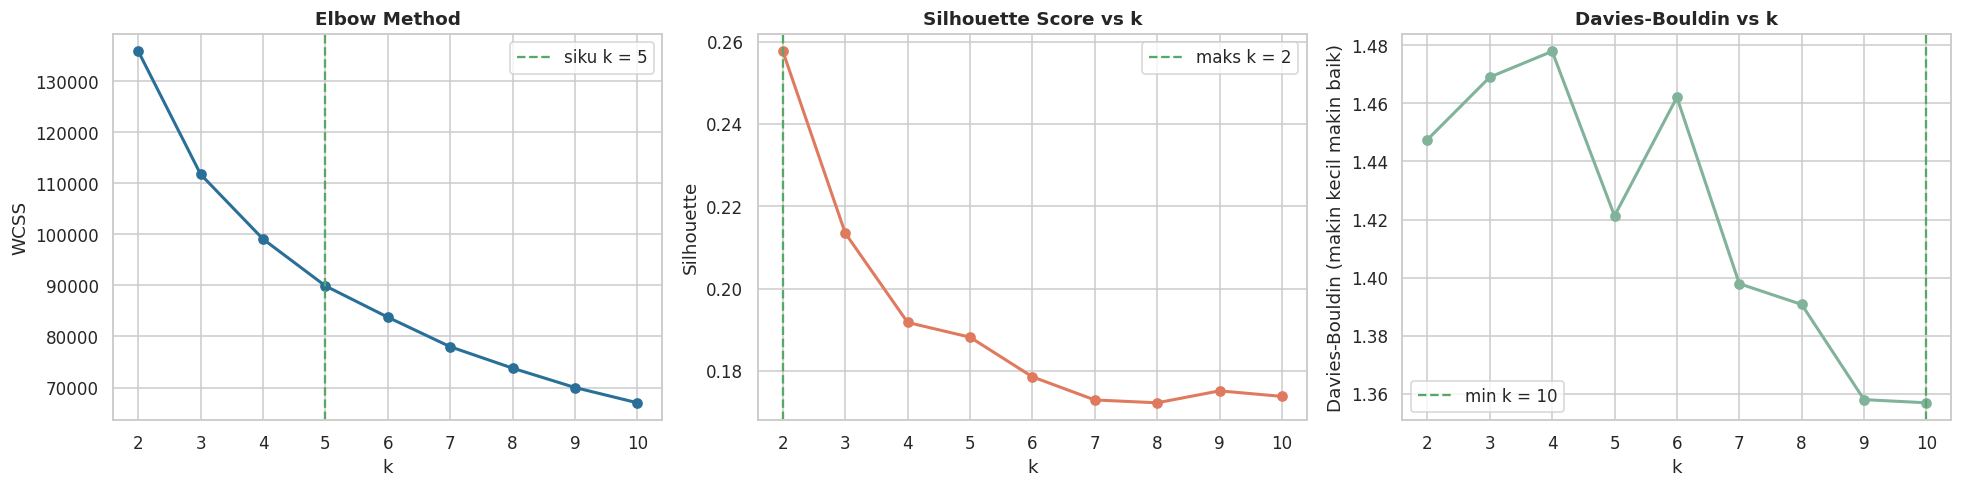

k menurut Elbow = 5 | k menurut Silhouette = 2 | k menurut Davies-Bouldin = 10


In [ ]:
Xc = X_scaled[PCA_VARS].values
ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xc)
    rows.append((k, km.inertia_, silhouette_score(Xc, km.labels_, sample_size=6000, random_state=SEED),
                 davies_bouldin_score(Xc, km.labels_), calinski_harabasz_score(Xc, km.labels_)))
kdf = pd.DataFrame(rows, columns=["k", "WCSS (inertia)", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]).set_index("k")
display(kdf)

# Titik siku: jarak terjauh kurva WCSS ke garis lurus antara titik awal dan akhir (metode 'kneedle' sederhana)
x_ = np.array(list(ks), float); y_ = kdf["WCSS (inertia)"].values
xn = (x_ - x_.min()) / (x_.max() - x_.min()); yn = (y_ - y_.min()) / (y_.max() - y_.min())
dist = np.abs(xn + yn - 1) / np.sqrt(2)                      # jarak ke garis dari (0,1) ke (1,0)
k_elbow = int(x_[dist.argmax()]); k_sil = int(kdf["Silhouette"].idxmax()); k_db = int(kdf["Davies-Bouldin"].idxmin())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
axes[0].plot(list(ks), kdf["WCSS (inertia)"], "o-", color="#2a6f97", lw=2); axes[0].axvline(k_elbow, c="g", ls="--", label=f"siku k = {k_elbow}")
axes[0].set_xlabel("k"); axes[0].set_ylabel("WCSS"); axes[0].set_title("Elbow Method"); axes[0].legend()
axes[1].plot(list(ks), kdf["Silhouette"], "o-", color="#e07a5f", lw=2); axes[1].axvline(k_sil, c="g", ls="--", label=f"maks k = {k_sil}")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette Score vs k"); axes[1].legend()
axes[2].plot(list(ks), kdf["Davies-Bouldin"], "o-", color="#81b29a", lw=2); axes[2].axvline(k_db, c="g", ls="--", label=f"min k = {k_db}")
axes[2].set_xlabel("k"); axes[2].set_ylabel("Davies-Bouldin (makin kecil makin baik)"); axes[2].set_title("Davies-Bouldin vs k"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"k menurut Elbow = {k_elbow} | k menurut Silhouette = {k_sil} | k menurut Davies-Bouldin = {k_db}")

**Gambar 16. Penentuan jumlah klaster.** Kiri: Elbow Method (WCSS), garis hijau menandai siku di k = 5. Tengah: Silhouette Score, tertinggi di k = 2 (0,258) lalu mendatar sekitar 0,19 pada k = 4 dan 5. Kanan: Davies-Bouldin, dengan minimum lokal di k = 5 (1,421).

**Pemilihan k.**

| Kriteria | k yang disarankan | Catatan |
|---|---|---|
| Elbow (jarak terjauh ke garis) | **5** | Penurunan WCSS melandai mulai k = 5; tidak ada siku tajam, sehingga ini penilaian yang bergantung pada kurva yang bergradasi. |
| Silhouette tertinggi | 2 (0,258) | Nilai turun ke 0,214 (k = 3), 0,192 (k = 4), 0,188 (k = 5), lalu mendatar sekitar 0,18. k = 2 hanya memisahkan blok "besar" dan "kecil" menurut PC1, sehingga kurang bernilai bagi interpretasi bisnis. |
| Calinski-Harabasz | 2 (7.440) | Menurun terus seiring k (5.437 pada k = 5), sehingga tidak mendukung k = 5 maupun siku apa pun. |
| Davies-Bouldin | minimum lokal di **5** (1,421) | Lebih baik daripada k = 4 (1,478) dan k = 6 (1,462). Minimum global di k = 10 hanya karena nilai terus turun seiring penambahan k. |

**Keputusan: k = 5.** Perlu diakui terus terang bahwa tidak ada kriteria numerik yang secara tegas mendukung k = 5: Silhouette dan Calinski-Harabasz tertinggi di k = 2, sedangkan Davies-Bouldin terus menurun hingga k = 10. Pemilihan k = 5 adalah keputusan yang dipandu titik siku dan interpretabilitas segmen, bukan optimum statistik.  Alasannya: (1) berada di titik siku, (2) silhouette mulai mendatar (tidak lebih buruk daripada k = 4), (3) Davies-Bouldin mencapai minimum lokal, dan (4) k = 5 menghasilkan segmen yang bermakna dan tidak terlihat pada k yang lebih kecil, yaitu kelompok *hunian padat berpendapatan rendah* (pada k = 3 dan k = 4 kelompok ini melebur ke klaster lain). Nilai silhouette yang rendah (≈ 0,19) menunjukkan struktur klaster tidak tegas; ini dibahas lebih lanjut pada III.2.2.

In [ ]:
K_OPT = 5
print("k optimal yang dipilih:", K_OPT)

k optimal yang dipilih: 5


### III.2.2 K-Means dengan k optimal dan evaluasinya

Silhouette Score      : 0.190
Davies-Bouldin Index  : 1.421   (makin kecil makin baik)
Calinski-Harabasz     : 5,436.7


,Jumlah anggota,Persen (%)
cluster,,
0,3115,15.153
1,4857,23.627
2,5294,25.753
3,2435,11.845
4,4856,23.622


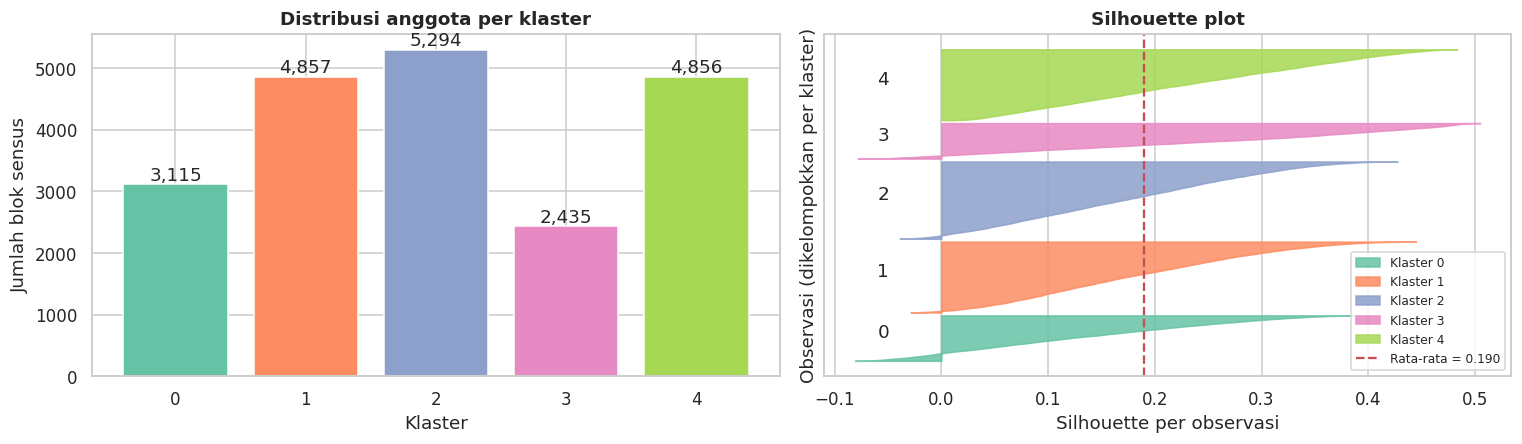

In [ ]:
km = KMeans(n_clusters=K_OPT, n_init=20, random_state=SEED).fit(Xc)
lab_raw = km.labels_

# Urutkan label klaster berdasarkan rata-rata pendapatan (hanya untuk penomoran; urutan ini lebih stabil daripada nilai rumah
# karena dua klaster menengah memiliki rata-rata nilai rumah yang nyaris sama, selisih sekitar 1.000 USD)
order_cl = pd.Series(df["median_income"].values).groupby(lab_raw).mean().sort_values().index.tolist()
remap = {old: new for new, old in enumerate(order_cl)}
df["cluster"] = pd.Series(lab_raw, index=df.index).map(remap)

sil_full = silhouette_score(Xc, df["cluster"].values, sample_size=10000, random_state=SEED)
dbi = davies_bouldin_score(Xc, df["cluster"].values)
chi_ = calinski_harabasz_score(Xc, df["cluster"].values)
print(f"Silhouette Score      : {sil_full:.3f}")
print(f"Davies-Bouldin Index  : {dbi:.3f}   (makin kecil makin baik)")
print(f"Calinski-Harabasz     : {chi_:,.1f}")

dist_cl = df["cluster"].value_counts().sort_index().to_frame("Jumlah anggota")
dist_cl["Persen (%)"] = dist_cl["Jumlah anggota"] / len(df) * 100
display(dist_cl)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bars = axes[0].bar(dist_cl.index.astype(str), dist_cl["Jumlah anggota"], color=sns.color_palette("Set2", K_OPT))
for b_, v_ in zip(bars, dist_cl["Jumlah anggota"]): axes[0].text(b_.get_x()+b_.get_width()/2, v_, f"{v_:,}", ha="center", va="bottom")
axes[0].set_xlabel("Klaster"); axes[0].set_ylabel("Jumlah blok sensus"); axes[0].set_title("Distribusi anggota per klaster")

from sklearn.metrics import silhouette_samples
ss = silhouette_samples(Xc, df["cluster"].values) if len(Xc) <= 25000 else None
y_low = 0
for c in range(K_OPT):
    v_ = np.sort(ss[df["cluster"].values == c]); axes[1].fill_betweenx(np.arange(y_low, y_low+len(v_)), 0, v_, color=sns.color_palette("Set2", K_OPT)[c], alpha=.85, label=f"Klaster {c}")
    axes[1].text(-0.06, y_low + len(v_)/2, str(c)); y_low += len(v_) + 200
axes[1].axvline(sil_full, c="r", ls="--", label=f"Rata-rata = {sil_full:.3f}"); axes[1].set_xlabel("Silhouette per observasi"); axes[1].set_ylabel("Observasi (dikelompokkan per klaster)"); axes[1].set_yticks([]); axes[1].set_title("Silhouette plot"); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Gambar 17. Hasil K-Means (k = 5).** Kiri: jumlah blok sensus per klaster. Kanan: silhouette plot, lebar bidang menunjukkan jumlah anggota dan garis putus-putus merah adalah rata-rata silhouette (0,190); sebagian kecil titik perbatasan memiliki silhouette negatif.

**Evaluasi:**

- **Silhouette = 0,190.** Ini tergolong lemah (di bawah 0,25), yang berarti data lebih menyerupai *kontinum* daripada kelompok yang terpisah jelas. Pada silhouette plot semua klaster memiliki rata-rata positif, dan Klaster 3 memiliki nilai individu tertinggi (hingga sekitar 0,51), tetapi beberapa klaster (paling jelas Klaster 0) memiliki titik perbatasan dengan silhouette negatif.
- **Davies-Bouldin = 1,421.** Di atas 1, sehingga klaster berada dalam kondisi sebagian tumpang tindih (nilai < 1 dianggap terpisah baik). Calinski-Harabasz = 5.437.
- **Distribusi anggota** cukup seimbang: 15,2% (Klaster 0), 23,6% (1), 25,8% (2), 11,8% (3), dan 23,6% (4). Tidak ada klaster yang hampir kosong atau mendominasi.

Segmentasi tetap bermanfaat untuk eksplorasi dan perumusan strategi, tetapi batas antar segmen bersifat *lunak*, tidak tegas.

### III.2.3 Profil komprehensif setiap klaster

RATA-RATA VARIABEL NUMERIK PER KLASTER (skala asli)


,n,median_house_value,median_income,housing_median_age,total_rooms,total_bedrooms,population,households,rooms_per_household,bedrooms_per_room,population_per_household,latitude,longitude
cluster,,,,,,,,,,,,,
0,3115,"136,729.409",2.280,34.018,"1,465.391",394.260,"1,445.864",372.556,3.982,0.278,3.964,34.861,-118.903
1,4857,"197,335.299",3.008,29.109,"2,653.980",626.666,"1,413.215",581.278,4.627,0.239,2.443,35.761,-119.719
2,5294,"196,057.099",3.735,34.620,"1,236.759",243.070,628.105,229.736,5.464,0.200,2.779,36.082,-119.941
3,2435,"213,207.343",4.176,17.214,"6,002.474","1,220.280","3,161.602","1,131.592",5.545,0.205,2.851,35.387,-119.291
4,4856,"270,432.092",5.751,24.065,"2,797.569",454.930,"1,268.081",427.686,6.666,0.164,2.978,35.599,-119.585


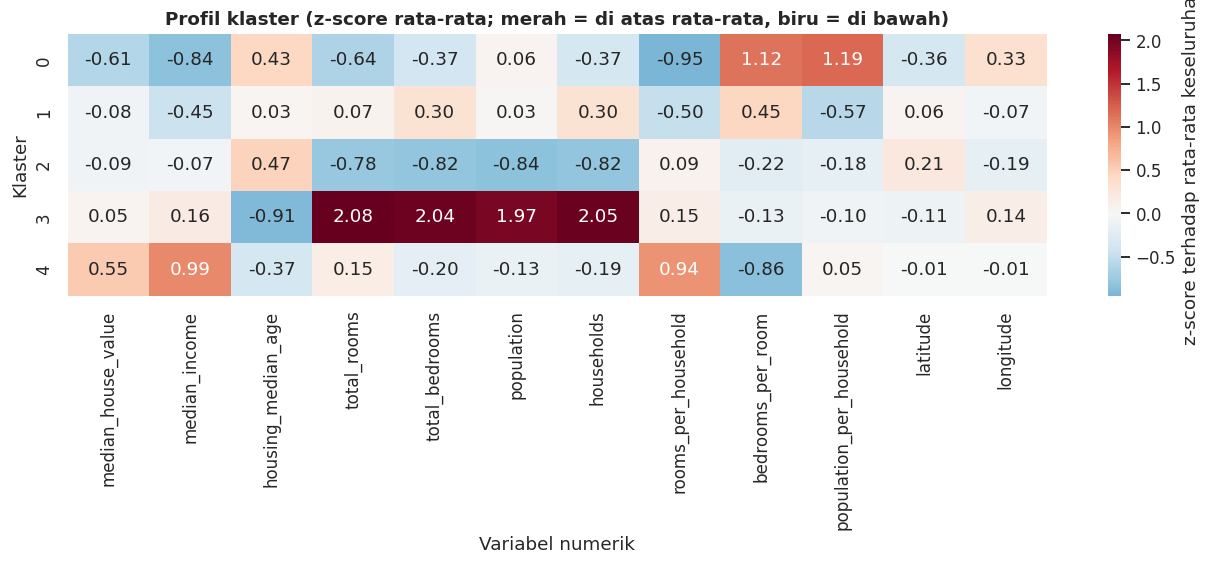

DISTRIBUSI KATEGORIK PER KLASTER (% baris)

ocean_proximity


ocean_proximity,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
cluster,,,,,
0,57.881,24.783,0.000,7.030,10.305
1,39.613,29.648,0.041,13.856,16.842
2,37.250,36.475,0.057,14.073,12.146
3,44.600,36.099,0.000,8.172,11.129
4,48.332,29.922,0.000,9.349,12.397



value_cat


value_cat,Murah,Menengah,Mahal
cluster,,,
0,54.543,38.780,6.677
1,36.648,32.963,30.389
2,37.080,33.037,29.883
3,26.982,37.659,35.359
4,15.527,28.501,55.972



income_cat


income_cat,Rendah,Menengah,Menengah-Atas,Tinggi
cluster,,,,
0,67.608,24.848,7.287,0.257
1,32.572,40.148,23.924,3.356
2,21.156,27.276,31.734,19.834
3,12.649,25.626,31.992,29.733
4,0.535,7.105,26.586,65.774



age_cat


age_cat,Baru (<=15),Cukup baru (16-30),Lama (31-45),Sangat lama (>45)
cluster,,,,
0,5.361,27.159,54.735,12.745
1,12.539,43.340,31.872,12.250
2,6.139,25.463,49.622,18.776
3,44.107,47.885,7.515,0.493
4,22.261,48.538,24.918,4.283


In [ ]:
PROF_NUM = ["median_house_value", "median_income", "housing_median_age", "total_rooms", "total_bedrooms", "population",
            "households", "rooms_per_household", "bedrooms_per_room", "population_per_household", "latitude", "longitude"]
prof_num = df.groupby("cluster")[PROF_NUM].mean()
prof_num.insert(0, "n", df["cluster"].value_counts().sort_index())
print("RATA-RATA VARIABEL NUMERIK PER KLASTER (skala asli)"); display(prof_num)

fig, ax = plt.subplots(figsize=(12, 3.8 + .3*K_OPT))
z_prof = (prof_num[PROF_NUM] - df[PROF_NUM].mean()) / df[PROF_NUM].std()
sns.heatmap(z_prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score terhadap rata-rata keseluruhan"})
ax.set_title("Profil klaster (z-score rata-rata; merah = di atas rata-rata, biru = di bawah)"); ax.set_xlabel("Variabel numerik"); ax.set_ylabel("Klaster"); plt.tight_layout(); plt.show()

print("DISTRIBUSI KATEGORIK PER KLASTER (% baris)")
for c in ["ocean_proximity", "value_cat", "income_cat", "age_cat"]:
    print(f"\n{c}"); display(pd.crosstab(df["cluster"], df[c], normalize="index") * 100)

**Gambar 18. Profil klaster.** Setiap sel adalah rata-rata variabel pada klaster tersebut yang dinyatakan dalam z-score terhadap rata-rata keseluruhan (merah di atas rata-rata, biru di bawah). Klaster 0 berpendapatan dan bernilai rumah terendah dengan penghuni terpadat; Klaster 4 sebaliknya.

**Ringkasan profil (nilai rata-rata, skala asli):**

| Klaster | n (%) | Nilai rumah | Pendapatan | Usia | Ruangan/RT | Penghuni/RT | Ciri kategorik utama |
|---|---|---|---|---|---|---|---|
| **0** | 3.115 (15,2%) | **136.729** (terendah) | 2,28 (terendah) | 34,0 | 3,98 (terkecil) | **3,96** (terpadat) | 54,5% kelas Murah, hanya 6,7% Mahal; 68% pendapatan Rendah; 58% `<1H OCEAN` |
| **1** | 4.857 (23,6%) | 197.335 | 3,01 | 29,1 | 4,63 | **2,44** (tersedikit) | 33% pendapatan Rendah, 40% Menengah; 30,4% Mahal |
| **2** | 5.294 (25,8%) | 196.057 | 3,74 | **34,6** (tertua) | 5,46 | 2,78 | blok kecil (rata-rata 230 rumah tangga); 18,8% bangunan >45 tahun; 36% Inland |
| **3** | 2.435 (11,8%) | 213.207 | 4,18 | **17,2** (termuda) | 5,55 | 2,85 | blok terbesar (rata-rata 1.132 rumah tangga); 44,1% bangunan ≤15 tahun; 35,4% Mahal |
| **4** | 4.856 (23,6%) | **270.432** (tertinggi) | **5,75** (tertinggi) | 24,1 | **6,67** (terluas) | 2,98 | 65,8% pendapatan Tinggi; 56,0% Mahal, hanya 15,5% Murah |

**Penamaan klaster:**

- **Klaster 0: "Hunian padat berpendapatan rendah"**: rumah paling kecil (4 ruangan per rumah tangga) dengan penghuni paling banyak (4 orang per rumah tangga), pendapatan terendah, dan nilai rumah terendah.
- **Klaster 1: "Rumah tangga kecil berpendapatan menengah-bawah"**: rumah tangga paling kecil (2,4 orang), pendapatan menengah-bawah, nilai rumah menengah.
- **Klaster 2: "Blok kecil bangunan tua"**: blok sensus kecil dengan bangunan paling tua dan pendapatan sedang (rata-rata mendekati rata-rata keseluruhan).
- **Klaster 3: "Perumahan baru berskala besar"**: blok sensus terbesar dengan bangunan paling baru.
- **Klaster 4: "Hunian luas berpendapatan tinggi"**: rumah paling luas (6,7 ruangan per rumah tangga), pendapatan dan nilai rumah tertinggi.

Nama diberikan lewat aturan berbasis profil (sel di bawah), sehingga tetap sesuai bila nomor klaster berubah.

Penomoran klaster diurutkan menurut rata-rata pendapatan (bukan nilai rumah), karena Klaster 1 dan 2 memiliki rata-rata nilai rumah yang nyaris sama (selisih sekitar 1.000 USD) sehingga urutannya tidak stabil.

In [ ]:
# ---- Penamaan klaster (nama diberikan berdasarkan profil di atas) ----
# Aturan penamaan berbasis profil (bukan nomor tetap), agar tetap benar bila urutan klaster berubah
cm = df.groupby("cluster")[["households", "median_income", "population_per_household"]].mean()
sisa, NAMA_KLASTER = set(cm.index), {}
def beri(pilih, nama):
    c = pilih(cm.loc[sorted(sisa)]); NAMA_KLASTER[c] = nama; sisa.discard(c)
beri(lambda d: d["median_income"].idxmax(),            "Hunian luas berpendapatan tinggi")
beri(lambda d: d["population_per_household"].idxmax(), "Hunian padat berpendapatan rendah")
beri(lambda d: d["households"].idxmax(),               "Perumahan baru berskala besar")
beri(lambda d: d["households"].idxmin(),               "Blok kecil bangunan tua")
beri(lambda d: d.index[0],                             "Rumah tangga kecil berpendapatan menengah-bawah")
assert len(NAMA_KLASTER) == K_OPT == 5, "Aturan penamaan ini dirancang untuk k = 5"
df["segmen"] = df["cluster"].map(NAMA_KLASTER)
ringkas_seg = df.groupby(["cluster", "segmen"]).agg(
    Jumlah=("segmen", "size"), Nilai_rumah=("median_house_value", "mean"), Pendapatan=("median_income", "mean"),
    Usia_rumah=("housing_median_age", "mean"), Penghuni_per_RT=("population_per_household", "mean"),
    Pct_Pesisir=("lokasi", lambda s: (s == "Pesisir").mean() * 100)).reset_index()
ringkas_seg

,cluster,segmen,Jumlah,Nilai_rumah,Pendapatan,Usia_rumah,Penghuni_per_RT,Pct_Pesisir
0,0,Hunian padat berpendapatan rendah,3115,"136,729.409",2.280,34.018,3.964,75.217
1,1,Rumah tangga kecil berpendapatan menengah-bawah,4857,"197,335.299",3.008,29.109,2.443,70.352
2,2,Blok kecil bangunan tua,5294,"196,057.099",3.735,34.620,2.779,63.525
3,3,Perumahan baru berskala besar,2435,"213,207.343",4.176,17.214,2.851,63.901
4,4,Hunian luas berpendapatan tinggi,4856,"270,432.092",5.751,24.065,2.978,70.078


### III.2.4 Visualisasi klaster pada ruang PC1 vs PC2

Centroid klaster pada ruang PC1-PC2:


,PC1,PC2
cluster,,
0,-0.981,1.841
1,0.512,0.905
2,-1.892,-0.413
3,3.771,0.110
4,0.289,-1.691


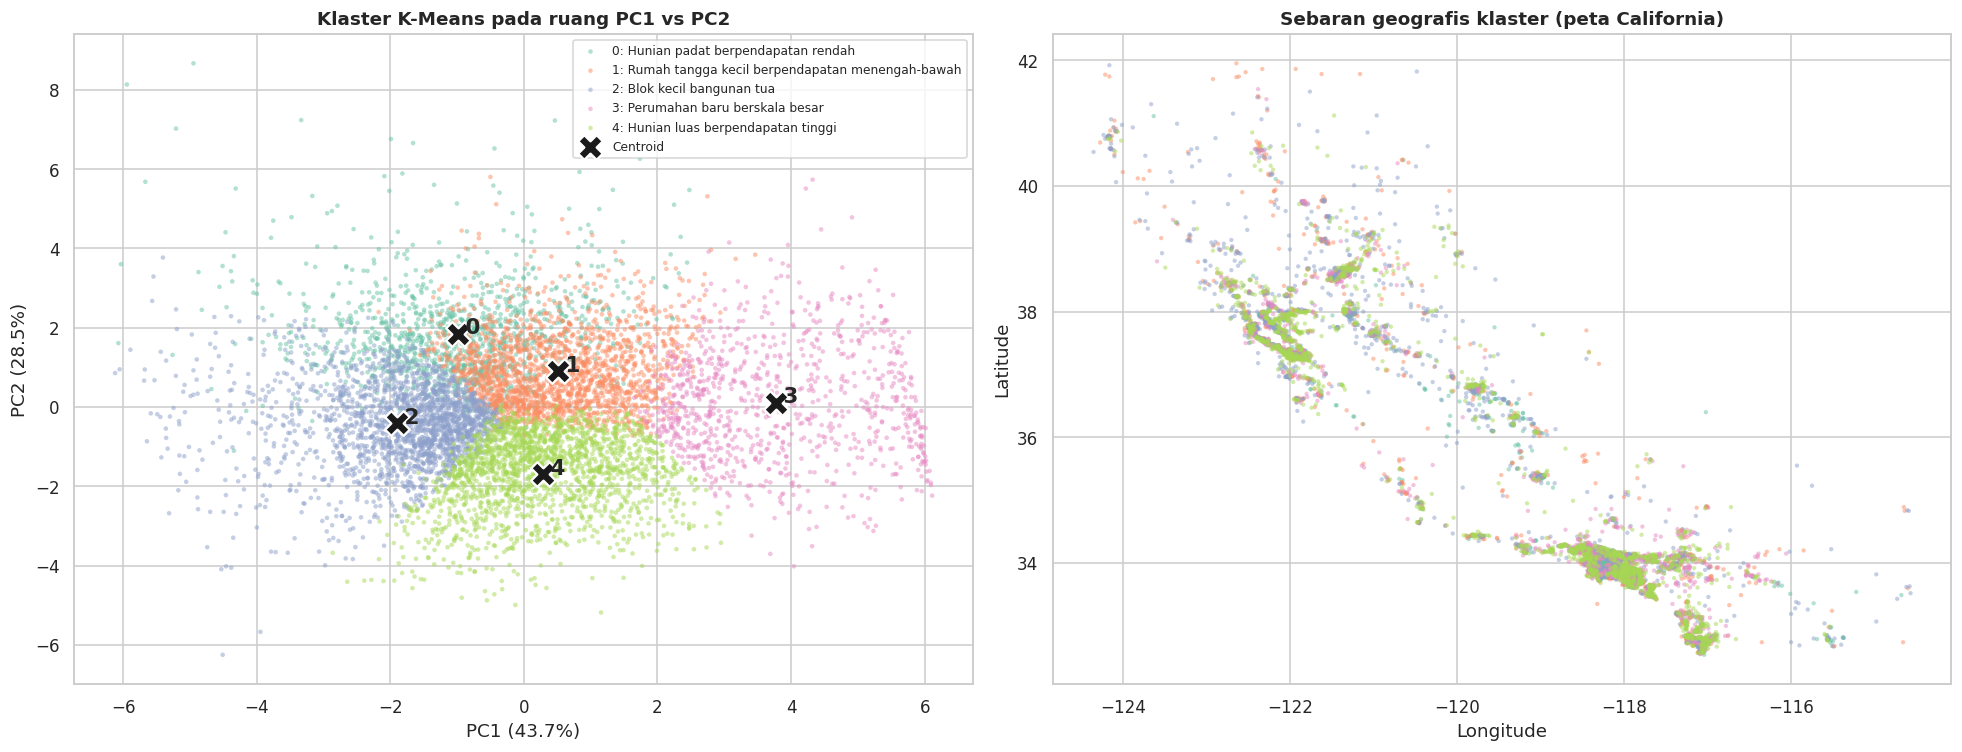

Silhouette klaster pada ruang PC1-PC2 : 0.237
Silhouette klaster pada ruang asli (9 dimensi): 0.190
Dua PC pertama menangkap 72.2% varians -> sisanya (27.8%) tidak terlihat pada plot 2D.


,Jarak centroid di PC1-PC2
0 vs 1,1.762
0 vs 2,2.432
2 vs 4,2.528
1 vs 4,2.606
1 vs 2,2.742
1 vs 3,3.355
0 vs 4,3.754
3 vs 4,3.921
0 vs 3,5.058
2 vs 3,5.688


In [ ]:
sm = df.sample(8000, random_state=SEED)
cols_cl = sns.color_palette("Set2", K_OPT)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for c in range(K_OPT):
    d_ = sm[sm.cluster == c]
    axes[0].scatter(d_["PC1"], d_["PC2"], s=9, alpha=.5, color=cols_cl[c], label=f"{c}: {NAMA_KLASTER[c]}", edgecolor="none")
cent_pc = df.groupby("cluster")[["PC1", "PC2"]].mean()
print("Centroid klaster pada ruang PC1-PC2:"); display(cent_pc)
axes[0].scatter(cent_pc["PC1"], cent_pc["PC2"], marker="X", s=260, c="k", edgecolor="w", lw=1.5, label="Centroid", zorder=5)
for c, r in cent_pc.iterrows(): axes[0].text(r["PC1"], r["PC2"], f" {c}", fontsize=14, weight="bold", zorder=6)
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); axes[0].set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
axes[0].set_title("Klaster K-Means pada ruang PC1 vs PC2"); axes[0].legend(fontsize=8, loc="best")

for c in range(K_OPT):
    d_ = sm[sm.cluster == c]; axes[1].scatter(d_["longitude"], d_["latitude"], s=8, alpha=.5, color=cols_cl[c], edgecolor="none")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude"); axes[1].set_title("Sebaran geografis klaster (peta California)")
plt.tight_layout(); plt.show()

sil_pc12 = silhouette_score(df[["PC1", "PC2"]].values, df["cluster"].values, sample_size=8000, random_state=SEED)
print(f"Silhouette klaster pada ruang PC1-PC2 : {sil_pc12:.3f}")
print(f"Silhouette klaster pada ruang asli ({len(PCA_VARS)} dimensi): {sil_full:.3f}")
cum2 = evr[:2].sum()
print(f"Dua PC pertama menangkap {cum2*100:.1f}% varians -> sisanya ({(1-cum2)*100:.1f}%) tidak terlihat pada plot 2D.")
sep = pd.Series({f"{a} vs {b}": np.linalg.norm(cent_pc.loc[a] - cent_pc.loc[b]) for a in range(K_OPT) for b in range(a+1, K_OPT)}, name="Jarak centroid di PC1-PC2")
display(sep.sort_values().to_frame())

**Gambar 19. Visualisasi klaster.** Kiri: klaster pada ruang PC1 vs PC2 (sampel 8.000 titik); tanda X hitam adalah centroid. Klaster 3 paling terpisah di kanan, sedangkan Klaster 0 dan 1 paling tumpang tindih. Kanan: sebaran geografis klaster, yang bercampur di seluruh California.

**Klaster mana yang paling terpisah?**

- Pada ruang PC1–PC2, klaster tersusun sebagai "irisan" di sepanjang dua sumbu: **Klaster 3** di kanan jauh (PC1 ≈ +3,8, blok besar) dan **Klaster 2** di kiri (PC1 ≈ −1,9, blok kecil). Klaster 0 berada di atas (PC2 ≈ +1,8) dan Klaster 4 di bawah (PC2 ≈ −1,7).
- **Klaster 3 paling terpisah**: jarak centroidnya ke Klaster 2 sebesar 5,69 dan ke Klaster 0 sebesar 5,06. Ini sesuai silhouette individu yang tertinggi. Klaster ini adalah satu-satunya yang berdiri sendiri di sisi kanan.
- **Klaster 0 dan 1 paling tumpang tindih** (jarak centroid hanya 1,76), diikuti Klaster 0 dan 2 (2,43) serta Klaster 2 dan 4 (2,53). Titik-titik di perbatasan ini menjelaskan silhouette yang rendah.
- Silhouette di ruang PC1–PC2 (0,237) lebih tinggi daripada di ruang 9 dimensi (0,190) karena dua PC pertama (72,2% varians) menyaring sebagian derau. Perlu diingat bahwa 27,8% varians lainnya tidak tampak pada gambar 2D, sehingga ada klaster yang terlihat bertumpuk padahal terpisah pada PC3 dan seterusnya.
- **Peta geografis** (panel kanan) memperlihatkan klaster **bercampur di seluruh wilayah**, termasuk di area padat seperti Los Angeles dan Teluk San Francisco. Jadi segmen ini menggambarkan *tipe blok*, bukan zona geografis; lokasi tidak ikut membentuk klaster karena `longitude` dan `latitude` memang tidak dipakai.

### III.2.5 Interpretasi bisnis/praktis dan rekomendasi

**Asumsi:** analisis ini dari sudut pandang pengembang atau lembaga pembiayaan perumahan yang perlu menentukan sasaran, dan juga pembuat kebijakan perumahan. Tingkat keterjangkauan diukur dengan rasio median nilai rumah terhadap median pendapatan tahunan (tabel di bawah).

| Klaster | Rekomendasi konkret |
|---|---|
| **4. Hunian luas berpendapatan tinggi** (23,6%) | **Prioritas utama untuk produk komersial.** Daya beli tertinggi dan beban terendah (rasio 4,6×). Cocok untuk produk premium, renovasi kelas atas, dan pembiayaan bernilai besar. 11,1% nilainya tersensor, sehingga potensi sebenarnya bahkan lebih tinggi. |
| **3. Perumahan baru berskala besar** (11,8%) | **Prioritas kedua (pertumbuhan).** Blok terbesar dan termuda (rata-rata 17 tahun) dengan pendapatan menengah-atas. Cocok untuk infrastruktur, fasilitas komunitas, dan jasa layanan perumahan baru. Segmen terkecil, tetapi paling jelas terpisah. |
| **2. Blok kecil bangunan tua** (25,8%) | Segmen terbesar dengan bangunan tertua (34,6 tahun; 18,8% di atas 45 tahun). Peluang **program renovasi, retrofit, dan peremajaan**; rasio keterjangkauan relatif sehat (4,8×). |
| **1. Rumah tangga kecil berpendapatan menengah-bawah** (23,6%) | Rumah tangga kecil (2,4 orang) dengan beban cukup tinggi (5,9×). Cocok untuk **unit ringkas yang terjangkau** (apartemen kecil, rumah tipe kecil) dan skema cicilan. |
| **0. Hunian padat berpendapatan rendah** (15,2%) | **Prioritas utama untuk kebijakan sosial.** Beban keterjangkauan tertinggi (**6,2×** pendapatan), paling padat (4 penghuni per rumah tangga), dan nilai rumah terendah. Sasaran **program perumahan terjangkau**, subsidi, dan perluasan unit. |

**Klaster yang harus diprioritaskan.** Untuk tujuan **komersial**, Klaster 4 diprioritaskan karena kombinasi ukuran besar (23,6%), nilai dan pendapatan tertinggi, serta keterjangkauan terbaik, sehingga risiko pembiayaan paling rendah dan potensi nilai tertinggi. Untuk tujuan **kebijakan publik**, Klaster 0 diprioritaskan karena kebutuhan terbesar: penghuni terpadat, pendapatan terendah, dan beban keterjangkauan tertinggi. Pilihan akhir bergantung pada tujuan organisasi.

*Catatan:* klaster tidak tegas (silhouette 0,19), sehingga rekomendasi sebaiknya diperlakukan sebagai arah strategi, bukan aturan klasifikasi yang kaku.

In [ ]:
# Tabel pendukung prioritas: ukuran segmen, daya beli, tingkat kepadatan
prio = df.groupby(["cluster", "segmen"]).agg(
    Jumlah=("segmen", "size"),
    Median_nilai_rumah=("median_house_value", "median"),
    Median_pendapatan_x10rb=("median_income", "median"),
    Penghuni_per_RT=("population_per_household", "mean"),
    Pct_value_censored=("flag_value_censored", lambda s: s.mean() * 100),
    Pct_Mahal=("value_cat", lambda s: (s == "Mahal").mean() * 100),
).reset_index()
prio["Rasio nilai rumah / pendapatan"] = prio["Median_nilai_rumah"] / (prio["Median_pendapatan_x10rb"] * 10000)
prio

,cluster,segmen,Jumlah,Median_nilai_rumah,Median_pendapatan_x10rb,Penghuni_per_RT,Pct_value_censored,Pct_Mahal,Rasio nilai rumah / pendapatan
0,0,Hunian padat berpendapatan rendah,3115,"135,700.000",2.186,3.964,0.385,6.677,6.207
1,1,Rumah tangga kecil berpendapatan menengah-bawah,4857,"176,600.000",2.975,2.443,3.068,30.389,5.936
2,2,Blok kecil bangunan tua,5294,"172,950.000",3.583,2.779,3.476,29.883,4.827
3,3,Perumahan baru berskala besar,2435,"190,000.000",3.958,2.851,3.244,35.359,4.801
4,4,Hunian luas berpendapatan tinggi,4856,"246,900.000",5.324,2.978,11.100,55.972,4.637


---
# Bagian IV — Sintesis dan Refleksi Kritis
## IV.1 Narasi Analisis Terpadu
Sebelum menulis narasi, saya menguji konsistensi antara PCA, clustering, dan variabel target secara kuantitatif.

Kesesuaian klaster dengan kelas nilai rumah: ARI = 0.039, NMI = 0.050  (0 = acak, 1 = identik)
Skor PC1 antar klaster: Kruskal-Wallis H = 14,320, p = 0.0e+00; eta² = 0.720 (porsi varians PC1 yang dijelaskan klaster)
PC2 antar klaster: eta² = 0.558

Crosstab klaster x kelas nilai rumah (% baris):


value_cat,Murah,Menengah,Mahal
segmen,,,
Blok kecil bangunan tua,37.080,33.037,29.883
Hunian luas berpendapatan tinggi,15.527,28.501,55.972
Hunian padat berpendapatan rendah,54.543,38.780,6.677
Perumahan baru berskala besar,26.982,37.659,35.359
Rumah tangga kecil berpendapatan menengah-bawah,36.648,32.963,30.389


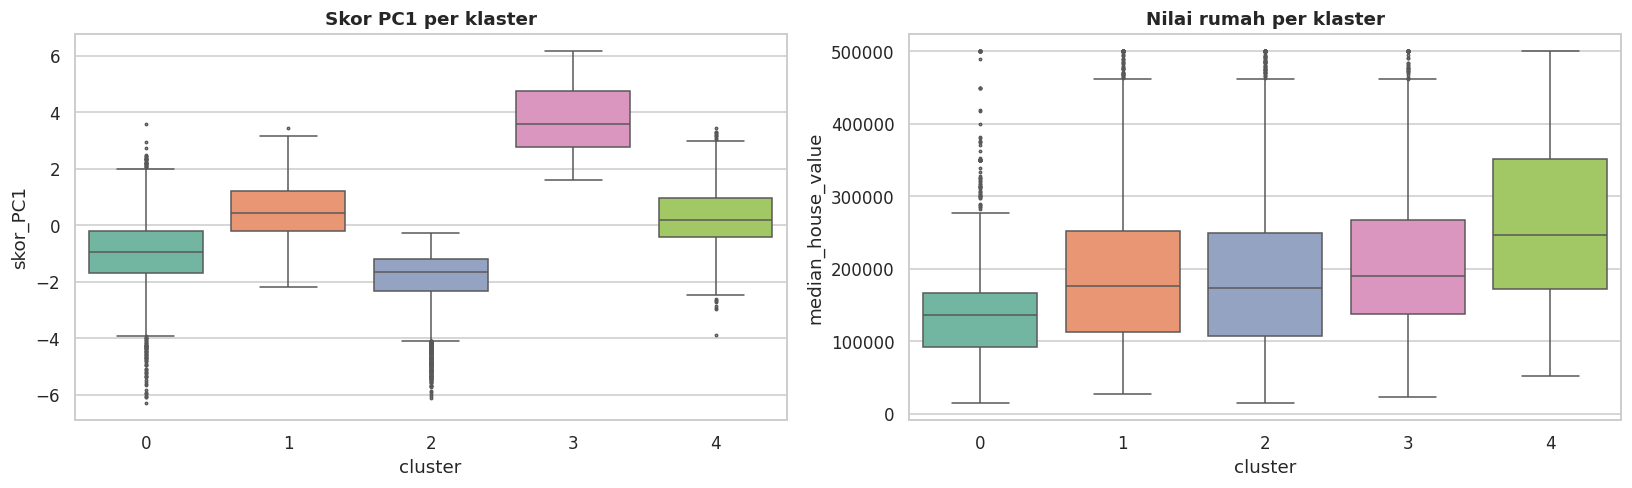

,Pearson,Spearman,Selisih
longitude,-0.046,-0.070,-0.024
latitude,-0.144,-0.165,-0.021
housing_median_age,0.105,0.074,-0.031
total_rooms,0.159,0.207,0.047
total_bedrooms,0.057,0.088,0.031
population,-0.032,0.002,0.034
households,0.072,0.112,0.039
median_income,0.690,0.678,-0.011
rooms_per_household,0.274,0.267,-0.007
bedrooms_per_room,-0.256,-0.331,-0.074


In [ ]:
# ---- Konsistensi klaster vs kelas nilai rumah vs skor PC1 ----
ari = adjusted_rand_score(df["value_cat"].astype(str), df["cluster"]); nmi = normalized_mutual_info_score(df["value_cat"].astype(str), df["cluster"])
print(f"Kesesuaian klaster dengan kelas nilai rumah: ARI = {ari:.3f}, NMI = {nmi:.3f}  (0 = acak, 1 = identik)")

H_pc, p_pc = stats.kruskal(*[g["skor_PC1"].values for _, g in df.groupby("cluster")])
ssb_pc = sum(len(g) * (g["skor_PC1"].mean() - df["skor_PC1"].mean())**2 for _, g in df.groupby("cluster")); sst_pc = ((df["skor_PC1"] - df["skor_PC1"].mean())**2).sum()
print(f"Skor PC1 antar klaster: Kruskal-Wallis H = {H_pc:,.0f}, p = {p_pc:.1e}; eta² = {ssb_pc/sst_pc:.3f} (porsi varians PC1 yang dijelaskan klaster)")
ssb_pc2 = sum(len(g) * (g["PC2"].mean() - df["PC2"].mean())**2 for _, g in df.groupby("cluster")); sst_pc2 = ((df["PC2"] - df["PC2"].mean()).pow(2)).sum()
print(f"PC2 antar klaster: eta² = {ssb_pc2/sst_pc2:.3f}")

print("\nCrosstab klaster x kelas nilai rumah (% baris):")
display(pd.crosstab(df["segmen"], df["value_cat"], normalize="index") * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sns.boxplot(data=df, x="cluster", y="skor_PC1", palette="Set2", ax=axes[0], fliersize=1.5); axes[0].set_title("Skor PC1 per klaster")
sns.boxplot(data=df, x="cluster", y="median_house_value", palette="Set2", ax=axes[1], fliersize=1.5); axes[1].set_title("Nilai rumah per klaster")
plt.tight_layout(); plt.show()

# Jawaban "apakah temuan univariat menjelaskan bivariat": skewness tinggi -> Spearman vs Pearson
cmp_sp = pd.DataFrame({"Pearson": df[NUM_ALL].corr()[TARGET], "Spearman": df[NUM_ALL].corr(method="spearman")[TARGET]}).drop(TARGET)
display(cmp_sp.assign(Selisih=lambda d: d.Spearman - d.Pearson).round(3))

**Gambar 20. Konsistensi klaster dengan skor PC1 dan nilai rumah.** Kiri: skor PC1 per klaster, yang terbedakan sangat jelas (klaster menjelaskan 72,0% varians PC1). Kanan: nilai rumah per klaster; nilai tertinggi pada Klaster 4 dan terendah pada Klaster 0, dengan tumpang tindih besar pada klaster tengah.

### IV.1.1 Kisah data: dari kualitas sampai segmentasi

Analisis ini memakai data sensus California 1990 berisi **20.640 blok sensus** dengan sepuluh variabel, yaitu sembilan numerik dan satu kategorik. Targetnya adalah median nilai rumah (`median_house_value`). Pemeriksaan awal menunjukkan data yang secara umum bersih (tanpa duplikat, tanpa inkonsistensi logis), tetapi memiliki tiga masalah penting. Pertama, ada **207 missing value** (1,00%) pada `total_bedrooms`, yang diimputasi memakai rasio terhadap `households` (MAE 33 dibandingkan 268 untuk median biasa). Kedua, ada **nilai tersensor** di batas pencatatan: 4,68% nilai rumah berhenti di 500.001, 6,17% usia bangunan berhenti di 52 tahun, dan 51 nilai pendapatan di 15,0001. Ketiga, variabel cacahan sangat miring (skewness 3,4–4,9) dengan sekitar 6% outlier menurut IQR, ditambah 83 baris (0,40%) dengan rasio hunian yang tidak wajar. Setelah dibersihkan (imputasi, penghapusan 83 baris, cap pada Q3 + 3×IQR, transformasi akar kuadrat/log1p, dan Z-score), tersisa **20.557 baris** dan hanya 1,07% sel numerik yang berubah, sehingga data layak dianalisis.

Pada tahap **univariat**, hampir semua variabel numerik miring ke kanan (paling ekstrem `population_per_household`, skewness 4,06 dan kurtosis 49,6), dan target miring moderat (0,98) dengan lonjakan di 500.001. Satu-satunya variabel kategorik asli, `ocean_proximity`, sangat tidak seimbang (kelas `ISLAND` hanya 5 baris). Pada tahap **bivariat**, muncul dua pola besar. Pertama, variabel yang terkait ukuran blok saling berkorelasi sangat kuat (hingga r = 0,984) tetapi hampir tidak berkaitan dengan harga. Kedua, harga sangat berkaitan dengan **pendapatan** (r = 0,690) dan **lokasi**: kedekatan dengan laut berasosiasi kuat dengan kelas harga (Cramér's V = 0,408), dan rata-rata nilai rumah di pesisir lebih tinggi 120.643 USD daripada daratan (Cohen's d = 1,20), sementara usia bangunan hampir tidak berpengaruh (V = 0,089).

Pada tahap **multivariat**, PCA meringkas sembilan variabel menjadi tiga komponen (84,6% varians): ukuran blok (PC1, 43,7%), keluasan dan kemapanan hunian (PC2, 28,5%), dan kepadatan penghuni (PC3, 12,4%). K-Means dengan k = 5 kemudian menghasilkan lima segmen: *hunian padat berpendapatan rendah*, *rumah tangga kecil berpendapatan menengah-bawah*, *blok kecil bangunan tua*, *perumahan baru berskala besar*, dan *hunian luas berpendapatan tinggi*, dengan nilai rumah rata-rata dari 136.729 sampai 270.432 USD.

### IV.1.2 Menghubungkan temuan kunci

**Univariat → bivariat.** Skewness tinggi menjelaskan mengapa korelasi Pearson dan Spearman berbeda pada beberapa variabel (selisih terbesar pada `bedrooms_per_room`: −0,256 vs −0,331), tetapi untuk pendapatan keduanya hampir sama (0,690 vs 0,678), artinya hubungan pendapatan dan harga cukup linear meski pendapatan sendiri miring. Lonjakan di 500.001 pada univariat juga menjelaskan pita datar pada scatter pendapatan–harga yang melandaikan korelasi. Ketidakseimbangan `ocean_proximity` menjelaskan mengapa `ISLAND` tidak signifikan pada uji lanjut walaupun selisih rata-ratanya besar (n = 5).

**PCA ↔ clustering.** Keduanya mengungkap dimensi yang sama, tetapi kecocokan ini **sebagian bersifat melingkar**: K-Means dan PCA memakai sembilan variabel yang sama, sehingga klaster yang tersusun mengikuti PC1 dan PC2 memang diharapkan dan bukan konfirmasi independen. Bukti yang lebih independen adalah hubungan klaster dengan variabel yang tidak dipakai membentuknya (nilai rumah dan kategori lokasi). Klaster tersusun mengikuti PC1 dan PC2: klaster menjelaskan 72,0% varians skor PC1 dan 55,8% varians PC2 (η²). Klaster 3 (blok terbesar) memiliki centroid PC1 tertinggi (+3,77), sedangkan Klaster 2 (blok kecil) terendah (−1,89), yang sejalan dengan interpretasi PC1 sebagai ukuran blok. Klaster 4 (berpendapatan tinggi) berada di PC2 paling negatif (−1,69), konsisten dengan PC2 yang menandai kemapanan. Keduanya menyimpulkan hal yang sama: struktur utama data adalah *ukuran blok* dan *kemapanan hunian*.

**Skor komposit PC1 ↔ segmentasi.** Konsisten dalam hal struktur (PC1 membedakan klaster dengan sangat jelas), tetapi **tidak konsisten dalam hal prediksi harga**: kesesuaian klaster dengan kelas harga rendah (ARI = 0,039; NMI = 0,050) dan skor PC1 hanya berkorelasi 0,110 dengan target. Klaster dan PC1 membedakan *tipe blok*, sedangkan harga lebih ditentukan oleh pendapatan dan lokasi. Meski demikian, segmen berbeda nyata dalam harga: Klaster 4 memiliki 56,0% blok kelas Mahal, sedangkan Klaster 0 hanya 6,7%.

### IV.1.3 Tiga insight terpenting

**Insight 1: Pendapatan, bukan ukuran blok, adalah penentu utama harga.**
*Temuan:* `median_income` berkorelasi 0,690 dengan harga dan sendirian menjelaskan R² validasi silang 0,451, sedangkan seluruh variabel ukuran blok berkorelasi di bawah 0,16 dan seluruh sembilan variabel bersama-sama hanya mencapai 0,590.
*Mengapa penting:* Kita sering menganggap area yang lebih besar atau lebih padat identik dengan harga lebih tinggi, padahal data membantahnya.
*Implikasi:* Model penilaian dan analisis pasar sebaiknya berfokus pada pendapatan dan kualitas hunian (rasio ruangan per rumah tangga), bukan jumlah ruangan atau penduduk blok.

**Insight 2: Lokasi pesisir vs daratan adalah pembeda harga paling jelas, tetapi gradasi di dalam pesisir kecil.**
*Temuan:* Median nilai rumah `INLAND` 108.200 USD, sedangkan kategori pesisir 214.800–233.800 USD; 71,8% blok Inland tergolong murah. Variabel biner `lokasi` (Pesisir/Daratan) menjelaskan η² = 0,236 variasi nilai rumah, yaitu 99% dari η² `ocean_proximity` lima kategori (0,239), sedangkan η² antar tiga kategori pesisir utama hanya 0,004. Perbedaan antar kategori pesisir (sekitar 9 ribu sampai 19 ribu USD) signifikan secara statistik tetapi sangat kecil secara praktis.
*Mengapa penting:* Efek lokasi terutama bersifat "ada atau tidak ada akses pesisir"; gradasi "makin dekat makin mahal" di dalam pesisir ada tetapi sangat kecil (η² 0,004).
*Implikasi:* Variabel biner pesisir/daratan sudah menangkap sebagian besar efeknya; untuk presisi lebih tinggi diperlukan informasi spasial yang lebih rinci (koordinat, jarak ke kota besar), bukan hanya label kategori.

**Insight 3: Beban keterjangkauan terkonsentrasi pada satu segmen, yaitu hunian padat berpendapatan rendah.**
*Temuan:* Klaster 0 (15,2% blok) memiliki rasio median nilai rumah terhadap pendapatan tahunan 6,2×, tertinggi dibanding 4,6× pada klaster berpendapatan tinggi, dengan 4 penghuni per rumah tangga dan hanya 6,7% blok kelas Mahal.
*Mengapa penting:* Nilai rumah yang rendah menyembunyikan kenyataan bahwa penghuninya paling terbebani.
*Implikasi:* Program perumahan terjangkau sebaiknya menyasar segmen ini terlebih dahulu, dan indikator keterjangkauan (harga/pendapatan) lebih tepat daripada harga mutlak untuk menentukan sasaran.

**Insight tambahan: Varians terbesar belum tentu informatif.** PC1 menyerap 43,7% varians tetapi hanya berkorelasi 0,110 dengan harga, sedangkan PC5 (hanya 4,5% varians) berkorelasi 0,472. Reduksi dimensi tanpa pengawasan tidak otomatis menyimpan informasi yang relevan bagi target. Catatan: besarnya varians PC1 sebagian dipengaruhi redundansi empat variabel cacahan (uji sensitivitas pada III.1.4), sehingga angka 43,7% sebaiknya tidak dibaca sebagai ukuran struktur data yang alami.

## IV.2 Keterbatasan dan Rekomendasi

### Keterbatasan analisis

1. **Kualitas data: censoring dan usia data.** 4,68% nilai rumah, 6,17% usia bangunan, dan 51 nilai pendapatan tersensor di batas pencatatan. Hal ini menurunkan korelasi pada ujung atas dan memperkecil segmen termahal (11,1% blok di Klaster 4 tersensor). Data juga berasal dari 1990 sehingga tidak mencerminkan pasar sekarang.
2. **Ukuran dan sifat sampel.** Unit analisis adalah *agregat* blok sensus (median dan jumlah), bukan rumah atau rumah tangga individu, sehingga kesimpulan pada tingkat blok tidak dapat serta-merta diterapkan pada rumah individu (*ecological fallacy*). Kategori `ISLAND` hanya 5 baris sehingga tidak ada kesimpulan yang andal untuk kategori tersebut. Cakupan hanya California.
3. **Asumsi statistik yang dilanggar.** Distribusi tidak normal dan varians antar kelompok tidak homogen (Levene p ≈ 0), sehingga ANOVA klasik diganti Welch ANOVA dan Kruskal-Wallis. Blok yang berdekatan secara geografis cenderung mirip (*autokorelasi spasial*), sehingga observasi tidak independen dan p-value cenderung terlalu kecil. Dengan n lebih dari 20 ribu hampir semua uji signifikan, jadi interpretasi harus bertumpu pada ukuran efek (V, η², Cohen's d). Frekuensi harapan Chi-Square di bawah 5 pada sel `ISLAND`.
4. **Keterbatasan metode.** PCA hanya menangkap hubungan **linear** dan tidak mempertimbangkan target. Dua PC pertama hanya menampilkan 72,2% varians. PCA utama memuat empat variabel cacahan yang hampir kembar sehingga PC1 sebagian merupakan artefak redundansi (uji sensitivitas pada III.1.4 menunjukkan PC1 berubah menjadi dimensi kemapanan hunian bila hanya satu wakil ukuran blok dipakai). K-Means mengasumsikan klaster berbentuk bola dengan ukuran serupa dan sensitif terhadap skala, pilihan k, dan inisialisasi; silhouette hanya 0,19 sehingga klaster tumpang tindih. Beberapa keputusan bersifat subjektif (batas cap 3×IQR, pembagian tertil harga, pemilihan variabel PCA, penamaan klaster). `longitude` dan `latitude` tidak dimasukkan dalam PCA dan K-Means sehingga dimensi spasial tidak ikut membentuk segmen.

5. **Validasi silang.** Nilai R² pada III.1.5 masih bersifat eksploratif karena sebagian praproses, standardisasi, dan PCA dilakukan sebelum pembagian fold. Evaluasi yang ketat perlu menempatkan tahapan tersebut di dalam `Pipeline` agar setiap fold hanya mempelajari parameter dari data latih.

### Rekomendasi analisis lanjutan

| # | Rekomendasi | Metode dan alasan |
|---|---|---|
| 1 | **Memodelkan struktur spasial** | Tambahkan fitur spasial (jarak ke pantai dan kota besar, kluster geografis) atau gunakan *Geographically Weighted Regression* / model spasial. Gunakan **validasi silang spasial (spatial block CV)** agar blok tetangga tidak bocor antar lipatan. Alasannya: lokasi adalah penentu harga terbesar yang belum masuk model dan menyebabkan autokorelasi. |
| 2 | **Pemodelan prediktif terawasi** | **Gradient boosting / Random Forest** pada log(nilai rumah) dengan **SHAP** untuk interpretasi, dibandingkan dengan **Ridge/Lasso** (menangani multikolinearitas). Evaluasi dengan MAE, RMSE, dan R² pada validasi silang. Perlakukan data tersensor secara khusus (model Tobit atau klasifikasi "≥ 500 ribu"). Alasannya: PCA tidak mampu memprediksi harga (PC1 r = 0,11), sedangkan hubungan di data jelas non-linear dan penuh interaksi. |
| 3 | **Memvalidasi segmentasi** | Bandingkan dengan **Gaussian Mixture Model** (klaster elips dan keanggotaan lunak, cocok untuk data yang berupa kontinum), **hierarchical clustering (Ward)**, dan **HDBSCAN**. Uji kestabilan dengan *bootstrap* (ARI antar-run) dan **gap statistic** untuk k. Alasannya: silhouette 0,19 menunjukkan struktur klaster lemah sehingga hasil perlu dipastikan tidak bergantung pada satu algoritma. |
| 4 | **Reduksi dimensi yang sadar target** | **PLS (Partial Least Squares)** atau seleksi fitur terawasi; untuk visualisasi non-linear gunakan **UMAP/t-SNE**. Alasannya: PCA memilih arah berdasarkan varians, bukan relevansi terhadap harga (PC5 lebih informatif daripada PC1). |
| 5 | **Memperkaya dan memperbarui data** | Gunakan data yang lebih baru (mis. American Community Survey) dengan variabel tambahan (sekolah, kriminalitas, akses kerja) agar hasil relevan dengan kondisi sekarang dan tidak tersensor di 500 ribu. |